# **Loading, Inspection and Cleaning**

In [1]:
import pandas as pd
import numpy as np
import re
import ast
import json
import warnings
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#fafafa',
    'figure.dpi': 110,
    'axes.titleweight': 'bold'
})

RESUME_PATH = '/content/Resume.csv'
JOB_PATH = '/content/all_job_post.csv'
SEED = 42
STOP = set(stopwords.words('english'))
np.random.seed(SEED)

In [2]:
resumes = pd.read_csv(RESUME_PATH)
jobs = pd.read_csv(JOB_PATH)

display(resumes.head(3))
display(jobs.head(3))

,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR


,job_id,category,job_title,job_description,job_skill_set
0,3902668440,HR,Sr Human Resource Generalist,SUMMARY\nTHE SR. HR GENERALIST PROVIDES HR EXP...,"['employee relations', 'talent acquisition', '..."
1,3905823748,HR,Human Resources Manager,BE PART OF A STELLAR TEAM AT YSB AS THE MANAGE...,"['Talent Acquisition', 'Employee Performance M..."
2,3905854799,HR,Director of Human Resources,OUR CLIENT IS A THRIVING ORGANIZATION OFFERING...,"['Human Resources Management', 'Recruitment', ..."


In [3]:
for name, df in [('resumes', resumes), ('jobs', jobs)]:
    print(name, df.shape)
    display(pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'missing': df.isnull().sum(),
        'missing_pct': (df.isnull().mean() * 100).round(2),
        'unique': df.nunique()
    }))
    print('duplicate rows:', df.duplicated().sum())

resumes (2484, 4)


,dtype,missing,missing_pct,unique
ID,int64,0,0.0,2484
Resume_str,object,0,0.0,2482
Resume_html,object,0,0.0,2482
Category,object,0,0.0,24


duplicate rows: 0
jobs (1167, 5)


,dtype,missing,missing_pct,unique
job_id,int64,0,0.0,1167
category,object,0,0.0,5
job_title,object,0,0.0,723
job_description,object,0,0.0,1167
job_skill_set,object,0,0.0,1167


duplicate rows: 0


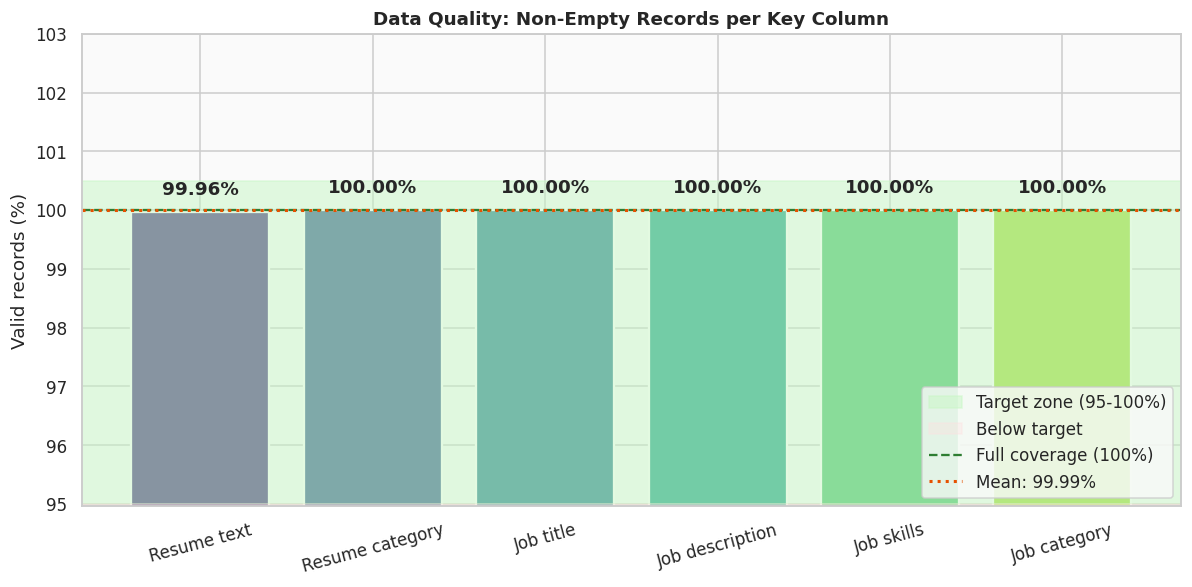

Resume_str {'resume_parsing_success_pct': np.float64(99.96), 'job_description_parsing_success_pct': np.float64(100.0)}


In [4]:
if 'Resume' in resumes.columns:
    RESUME_COL = 'Resume'
elif 'Resume_str' in resumes.columns:
    RESUME_COL = 'Resume_str'
else:
    obj_cols = resumes.select_dtypes('object').columns
    RESUME_COL = max(obj_cols, key=lambda c: resumes[c].astype(str).str.len().mean())

RESUME_CAT = 'Category'
JOB_TITLE, JOB_DESC, JOB_SKILLS, JOB_CAT = 'job_title', 'job_description', 'job_skill_set', 'category'

def valid_pct(series):
    return (series.notna() & (series.astype(str).str.strip() != '')).mean() * 100

quality = pd.Series({
    'Resume text': valid_pct(resumes[RESUME_COL]),
    'Resume category': valid_pct(resumes[RESUME_CAT]),
    'Job title': valid_pct(jobs[JOB_TITLE]),
    'Job description': valid_pct(jobs[JOB_DESC]),
    'Job skills': valid_pct(jobs[JOB_SKILLS]),
    'Job category': valid_pct(jobs[JOB_CAT])
})

parsing_success = {
    'resume_parsing_success_pct': round(quality['Resume text'], 2),
    'job_description_parsing_success_pct': round(quality['Job description'], 2)
}

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = sns.color_palette('viridis', len(quality))
bars = ax.bar(quality.index, quality.values, color=colors, edgecolor='white', linewidth=1.5)
ax.axhspan(95, 100.5, color='#c8f7c5', alpha=0.5, label='Target zone (95-100%)')
ax.axhspan(0, 95, color='#ffe0e0', alpha=0.35, label='Below target')
ax.axhline(100, color='#2e7d32', linestyle='--', linewidth=1.5, label='Full coverage (100%)')
ax.axhline(quality.mean(), color='#e65100', linestyle=':', linewidth=2, label=f'Mean: {quality.mean():.2f}%')
for b, v in zip(bars, quality.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.3, f'{v:.2f}%', ha='center', fontweight='bold')
ax.set_ylim(max(0, quality.min() - 5), 103)
ax.set_ylabel('Valid records (%)')
ax.set_title('Data Quality: Non-Empty Records per Key Column')
ax.legend(loc='lower right')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print(RESUME_COL, parsing_success)

In [5]:
def clean_text(t):
    t = str(t).lower()
    t = re.sub(r'http\S+|www\S+', ' ', t)
    t = re.sub(r'[^a-z0-9+#.\s]', ' ', t)
    t = re.sub(r'(?<![a-z0-9])\.|\.(?![a-z0-9])', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

def remove_stopwords(t):
    return ' '.join(w for w in t.split() if w not in STOP)

n_resumes_before, n_jobs_before = len(resumes), len(jobs)

resumes = resumes[resumes[RESUME_COL].notna() & (resumes[RESUME_COL].astype(str).str.strip() != '')].copy()
resumes = resumes[resumes[RESUME_CAT].notna()].reset_index(drop=True)
jobs = jobs[jobs[JOB_DESC].notna() & jobs[JOB_SKILLS].notna() & jobs[JOB_CAT].notna()].copy()
jobs = jobs[jobs[JOB_DESC].astype(str).str.strip() != ''].reset_index(drop=True)

resumes['resume_clean'] = resumes[RESUME_COL].apply(clean_text)
resumes['resume_nostop'] = resumes['resume_clean'].apply(remove_stopwords)
resumes['resume_chars'] = resumes['resume_clean'].str.len()
resumes['resume_words'] = resumes['resume_clean'].str.split().str.len()

jobs['jd_clean'] = jobs[JOB_DESC].apply(clean_text)
jobs['jd_nostop'] = jobs['jd_clean'].apply(remove_stopwords)
jobs['jd_chars'] = jobs['jd_clean'].str.len()
jobs['jd_words'] = jobs['jd_clean'].str.split().str.len()

print('resumes:', n_resumes_before, '->', len(resumes))
print('jobs:', n_jobs_before, '->', len(jobs))
display(resumes[['resume_chars', 'resume_words']].describe().round(1))
display(jobs[['jd_chars', 'jd_words']].describe().round(1))

resumes: 2484 -> 2483
jobs: 1167 -> 1167


,resume_chars,resume_words
count,2483.0,2483.0
mean,5764.7,814.2
std,2605.0,374.9
min,663.0,108.0
25%,4685.0,652.5
50%,5381.0,759.0
75%,6665.0,934.5
max,34366.0,5167.0


,jd_chars,jd_words
count,1167.0,1167.0
mean,3673.4,530.0
std,2047.1,299.9
min,161.0,29.0
25%,2082.0,294.5
50%,3378.0,484.0
75%,4822.0,698.0
max,13332.0,1903.0


In [6]:
SYNONYMS = {
    'js': 'javascript', 'node': 'nodejs', 'node.js': 'nodejs', 'reactjs': 'react', 'react.js': 'react',
    'ml': 'machine learning', 'ai': 'artificial intelligence', 'nlp': 'natural language processing',
    'k8s': 'kubernetes', 'postgres': 'postgresql', 'mongo': 'mongodb', 'ms excel': 'excel',
    'microsoft excel': 'excel', 'powerbi': 'power bi', 'sklearn': 'scikit-learn', 'tf': 'tensorflow',
    'py': 'python', 'golang': 'go', 'amazon web services': 'aws', 'google cloud platform': 'gcp'
}

def normalize_skill(s):
    s = re.sub(r'[\'"\[\]]', '', str(s)).lower().strip()
    s = re.sub(r'\s+', ' ', s)
    return SYNONYMS.get(s, s)

def parse_skills(raw):
    raw = str(raw).strip()
    items = None
    if raw.startswith('['):
        try:
            items = ast.literal_eval(raw)
        except Exception:
            items = None
    if items is None:
        items = re.split(r'[,;|\n]', raw)
    cleaned = [normalize_skill(i) for i in items]
    return list(dict.fromkeys(s for s in cleaned if s and len(s) <= 40))

jobs['skills_list'] = jobs[JOB_SKILLS].apply(parse_skills)
jobs['n_skills'] = jobs['skills_list'].str.len()
jobs = jobs[jobs['n_skills'] > 0].reset_index(drop=True)

skill_counter = Counter(s for lst in jobs['skills_list'] for s in lst)
MIN_FREQ = 3
skills_vocab = sorted([s for s, c in skill_counter.items() if c >= MIN_FREQ])

print('jobs after skill filter:', len(jobs))
print('unique skills:', len(skill_counter), '| vocabulary (freq >= 3):', len(skills_vocab))
print('average skills per job:', round(jobs['n_skills'].mean(), 2))
print(skill_counter.most_common(15))
display(jobs[[JOB_TITLE, JOB_CAT, 'skills_list', 'n_skills']].head(5))
print('resume categories:', sorted(resumes[RESUME_CAT].unique()))
print('job categories:', sorted(jobs[JOB_CAT].unique()))

jobs after skill filter: 1167
unique skills: 4901 | vocabulary (freq >= 3): 874
average skills per job: 17.78
[('communication', 1092), ('problem solving', 878), ('adaptability', 588), ('teamwork', 569), ('collaboration', 341), ('leadership', 325), ('time management', 316), ('interpersonal skills', 288), ('customer service', 272), ('relationship building', 267), ('attention to detail', 253), ('data analysis', 251), ('project management', 234), ('organizational skills', 231), ('negotiation', 157)]


,job_title,category,skills_list,n_skills
0,Sr Human Resource Generalist,HR,"[employee relations, talent acquisition, perfo...",27
1,Human Resources Manager,HR,"[talent acquisition, employee performance mana...",16
2,Director of Human Resources,HR,"[human resources management, recruitment, empl...",20
3,Chief Human Resources Officer,HR,"[talent management, organizational development...",18
4,Human Resources Generalist (Hybrid Role),HR,"[microsoft office, data analysis, employee onb...",20


resume categories: ['ACCOUNTANT', 'ADVOCATE', 'AGRICULTURE', 'APPAREL', 'ARTS', 'AUTOMOBILE', 'AVIATION', 'BANKING', 'BPO', 'BUSINESS-DEVELOPMENT', 'CHEF', 'CONSTRUCTION', 'CONSULTANT', 'DESIGNER', 'DIGITAL-MEDIA', 'ENGINEERING', 'FINANCE', 'FITNESS', 'HEALTHCARE', 'HR', 'INFORMATION-TECHNOLOGY', 'PUBLIC-RELATIONS', 'SALES', 'TEACHER']
job categories: ['BUSINESS-DEVELOPMENT', 'FINANCE', 'HR', 'INFORMATION-TECHNOLOGY', 'SALES']


# **Deduplication and Resume-Side EDA**

In [7]:
n_before = len(resumes)
resumes = resumes.drop_duplicates(subset='resume_clean').reset_index(drop=True)
print('resumes after removing duplicate text:', n_before, '->', len(resumes))

balance = pd.DataFrame({
    'resumes': resumes[RESUME_CAT].value_counts(),
    'jobs': jobs[JOB_CAT].value_counts()
}).fillna(0).astype(int)
balance['resume_pct'] = (balance['resumes'] / balance['resumes'].sum() * 100).round(2)
balance['job_pct'] = (balance['jobs'] / balance['jobs'].sum() * 100).round(2)
display(balance.sort_values('resumes', ascending=False))

cat_counts_all = resumes[RESUME_CAT].value_counts()
JOB_MATCHABLE = sorted(jobs[JOB_CAT].unique())
TOP_CATS = cat_counts_all.head(3).index.tolist()
print('imbalance ratio (largest/smallest):', round(cat_counts_all.max() / cat_counts_all.min(), 2))
print('top 3 resume categories:', TOP_CATS)
print('resumes with a job counterpart:', int(resumes[RESUME_CAT].isin(JOB_MATCHABLE).sum()), 'of', len(resumes))

resumes after removing duplicate text: 2483 -> 2481


,resumes,jobs,resume_pct,job_pct
INFORMATION-TECHNOLOGY,120,240,4.84,20.57
BUSINESS-DEVELOPMENT,119,239,4.80,20.48
ACCOUNTANT,118,0,4.76,0.00
ADVOCATE,118,0,4.76,0.00
CHEF,118,0,4.76,0.00
ENGINEERING,118,0,4.76,0.00
FITNESS,117,0,4.72,0.00
FINANCE,117,236,4.72,20.22
SALES,116,232,4.68,19.88
AVIATION,116,0,4.68,0.00


imbalance ratio (largest/smallest): 5.45
top 3 resume categories: ['INFORMATION-TECHNOLOGY', 'BUSINESS-DEVELOPMENT', 'ADVOCATE']
resumes with a job counterpart: 582 of 2481


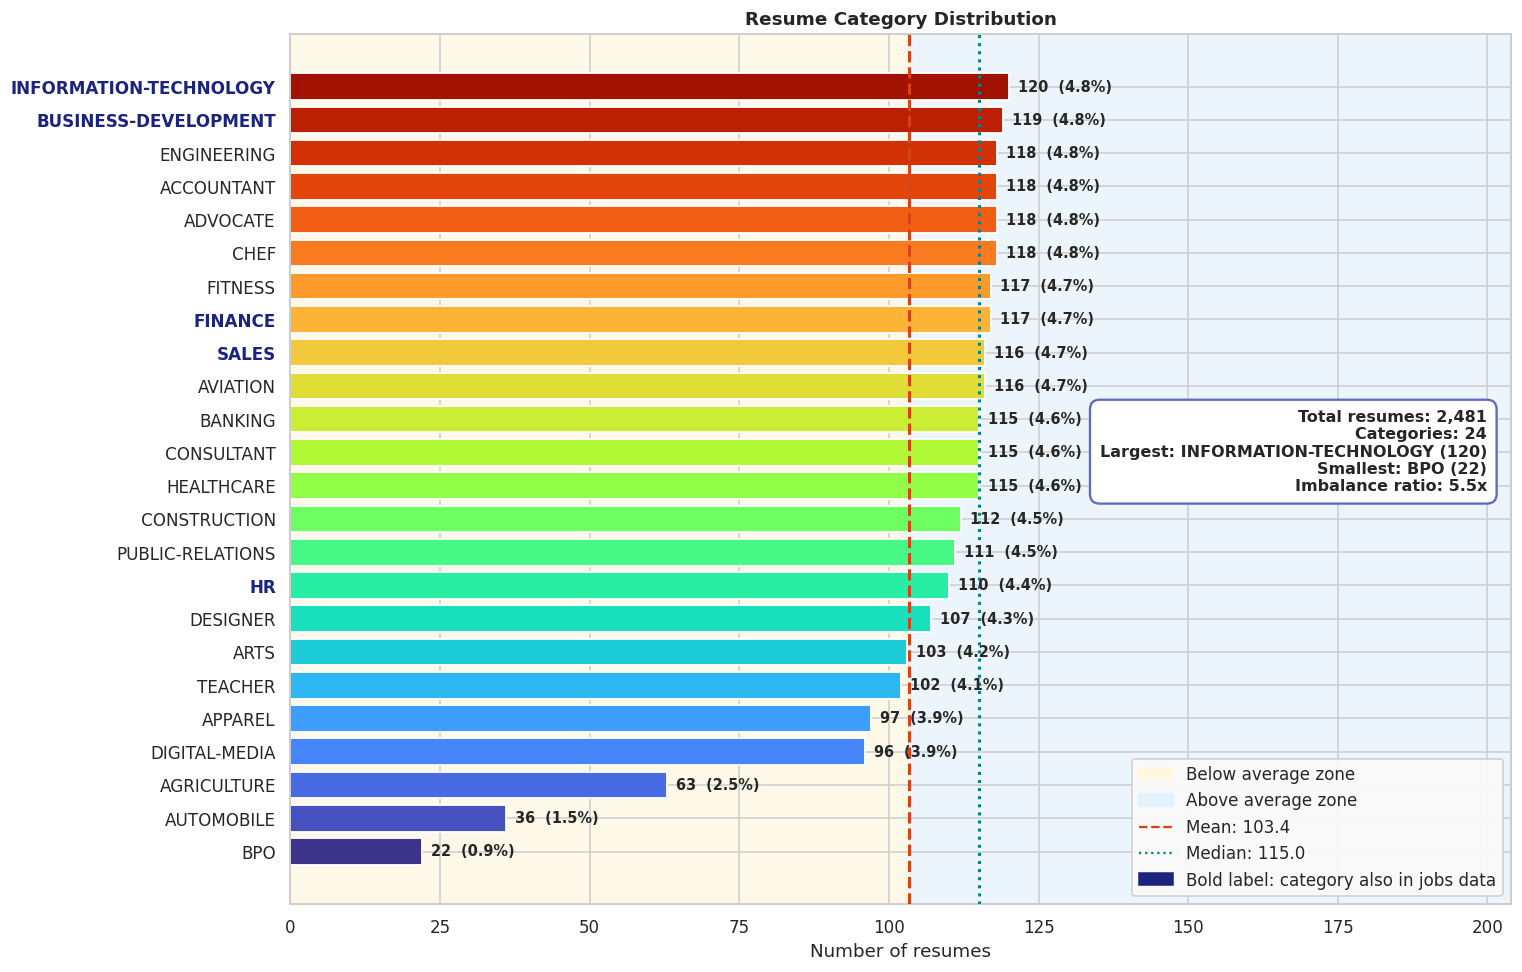

In [8]:
from matplotlib.patches import Patch

cat_counts = resumes[RESUME_CAT].value_counts().sort_values()
mean_v, med_v = cat_counts.mean(), cat_counts.median()
colors = plt.cm.turbo(np.linspace(0.05, 0.95, len(cat_counts)))

fig, ax = plt.subplots(figsize=(14, 9))
ax.axvspan(0, mean_v, color='#fff8e1', alpha=0.7, zorder=0)
ax.axvspan(mean_v, cat_counts.max() * 1.7, color='#e3f2fd', alpha=0.6, zorder=0)
bars = ax.barh(cat_counts.index, cat_counts.values, color=colors, edgecolor='white', linewidth=1.2, zorder=2)
ax.axvline(mean_v, color='#d84315', linestyle='--', linewidth=2, zorder=3)
ax.axvline(med_v, color='#00838f', linestyle=':', linewidth=2, zorder=3)

for b, (c, v) in zip(bars, cat_counts.items()):
    ax.text(v + 1.5, b.get_y() + b.get_height() / 2, f'{v}  ({v / len(resumes) * 100:.1f}%)',
            va='center', fontsize=9.5, fontweight='bold')

for lbl in ax.get_yticklabels():
    if lbl.get_text() in JOB_MATCHABLE:
        lbl.set_fontweight('bold')
        lbl.set_color('#1a237e')

ax.set_xlim(0, cat_counts.max() * 1.7)
ax.set_xlabel('Number of resumes')
ax.set_title('Resume Category Distribution')
kpi = (f'Total resumes: {len(resumes):,}\nCategories: {len(cat_counts)}\n'
       f'Largest: {cat_counts.idxmax()} ({cat_counts.max()})\nSmallest: {cat_counts.idxmin()} ({cat_counts.min()})\n'
       f'Imbalance ratio: {cat_counts.max() / cat_counts.min():.1f}x')
ax.text(0.98, 0.52, kpi, transform=ax.transAxes, ha='right', va='center', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
handles = [Patch(color='#fff8e1', label='Below average zone'), Patch(color='#e3f2fd', label='Above average zone'),
           plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Mean: {mean_v:.1f}'),
           plt.Line2D([0], [0], color='#00838f', linestyle=':', label=f'Median: {med_v:.1f}'),
           Patch(color='#1a237e', label='Bold label: category also in jobs data')]
ax.legend(handles=handles, loc='lower right', framealpha=0.95)
plt.tight_layout()
plt.show()

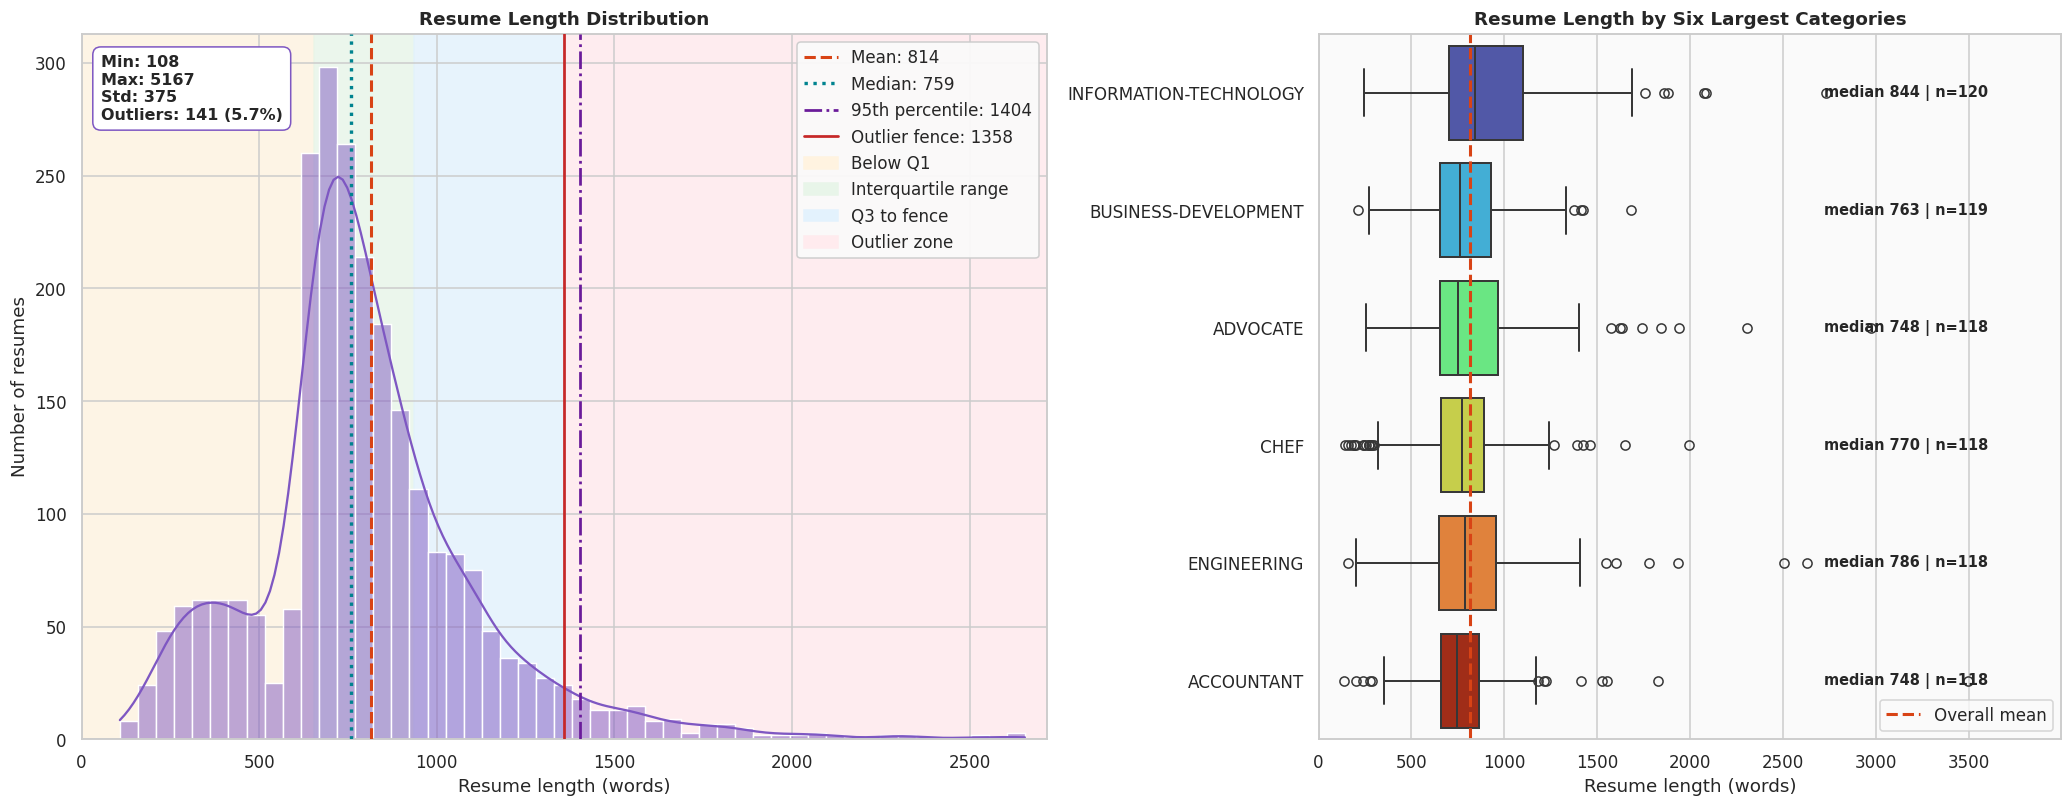

In [9]:
w = resumes['resume_words']
q1, q3 = w.quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
p95 = w.quantile(0.95)
n_out = int((w > upper_fence).sum())
plot_cap = w.quantile(0.995)

top6 = resumes[RESUME_CAT].value_counts().head(6).index.tolist()
pal6 = dict(zip(top6, plt.cm.turbo(np.linspace(0.08, 0.92, 6))))
sub = resumes[resumes[RESUME_CAT].isin(top6)]

fig, axes = plt.subplots(1, 2, figsize=(19, 7.5), gridspec_kw={'width_ratios': [1.3, 1]})
ax = axes[0]
ax.axvspan(0, q1, color='#fff3e0', alpha=0.8, zorder=0)
ax.axvspan(q1, q3, color='#e8f5e9', alpha=0.8, zorder=0)
ax.axvspan(q3, upper_fence, color='#e3f2fd', alpha=0.8, zorder=0)
ax.axvspan(upper_fence, plot_cap * 1.02, color='#ffebee', alpha=0.9, zorder=0)
sns.histplot(w[w <= plot_cap], bins=50, kde=True, color='#7e57c2', edgecolor='white', ax=ax, zorder=2)
ax.axvline(w.mean(), color='#d84315', linestyle='--', linewidth=2, label=f'Mean: {w.mean():.0f}', zorder=3)
ax.axvline(w.median(), color='#00838f', linestyle=':', linewidth=2.2, label=f'Median: {w.median():.0f}', zorder=3)
ax.axvline(p95, color='#6a1b9a', linestyle='-.', linewidth=1.8, label=f'95th percentile: {p95:.0f}', zorder=3)
ax.axvline(upper_fence, color='#c62828', linestyle='-', linewidth=1.8, label=f'Outlier fence: {upper_fence:.0f}', zorder=3)
ax.set_xlim(0, plot_cap * 1.02)
ax.set_xlabel('Resume length (words)')
ax.set_ylabel('Number of resumes')
ax.set_title('Resume Length Distribution')
kpi = f'Min: {w.min()}\nMax: {w.max()}\nStd: {w.std():.0f}\nOutliers: {n_out} ({n_out / len(w) * 100:.1f}%)'
ax.text(0.02, 0.97, kpi, transform=ax.transAxes, va='top', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#7e57c2'))
handles, labels = ax.get_legend_handles_labels()
handles += [Patch(color='#fff3e0'), Patch(color='#e8f5e9'), Patch(color='#e3f2fd'), Patch(color='#ffebee')]
labels += ['Below Q1', 'Interquartile range', 'Q3 to fence', 'Outlier zone']
ax.legend(handles, labels, loc='upper right', framealpha=0.95)

ax2 = axes[1]
sns.boxplot(data=sub, y=RESUME_CAT, x='resume_words', order=top6, hue=RESUME_CAT, palette=pal6,
            legend=False, orient='h', linewidth=1.3, ax=ax2)
ax2.axvline(w.mean(), color='#d84315', linestyle='--', linewidth=2, label='Overall mean')
for i, c in enumerate(top6):
    s = sub.loc[sub[RESUME_CAT] == c, 'resume_words']
    ax2.text(plot_cap * 1.02, i, f'median {s.median():.0f} | n={len(s)}', va='center', fontsize=9.5, fontweight='bold')
ax2.set_xlim(0, plot_cap * 1.5)
ax2.set_xlabel('Resume length (words)')
ax2.set_ylabel('')
ax2.set_title('Resume Length by Six Largest Categories')
ax2.legend(loc='lower right')
plt.tight_layout()
plt.show()

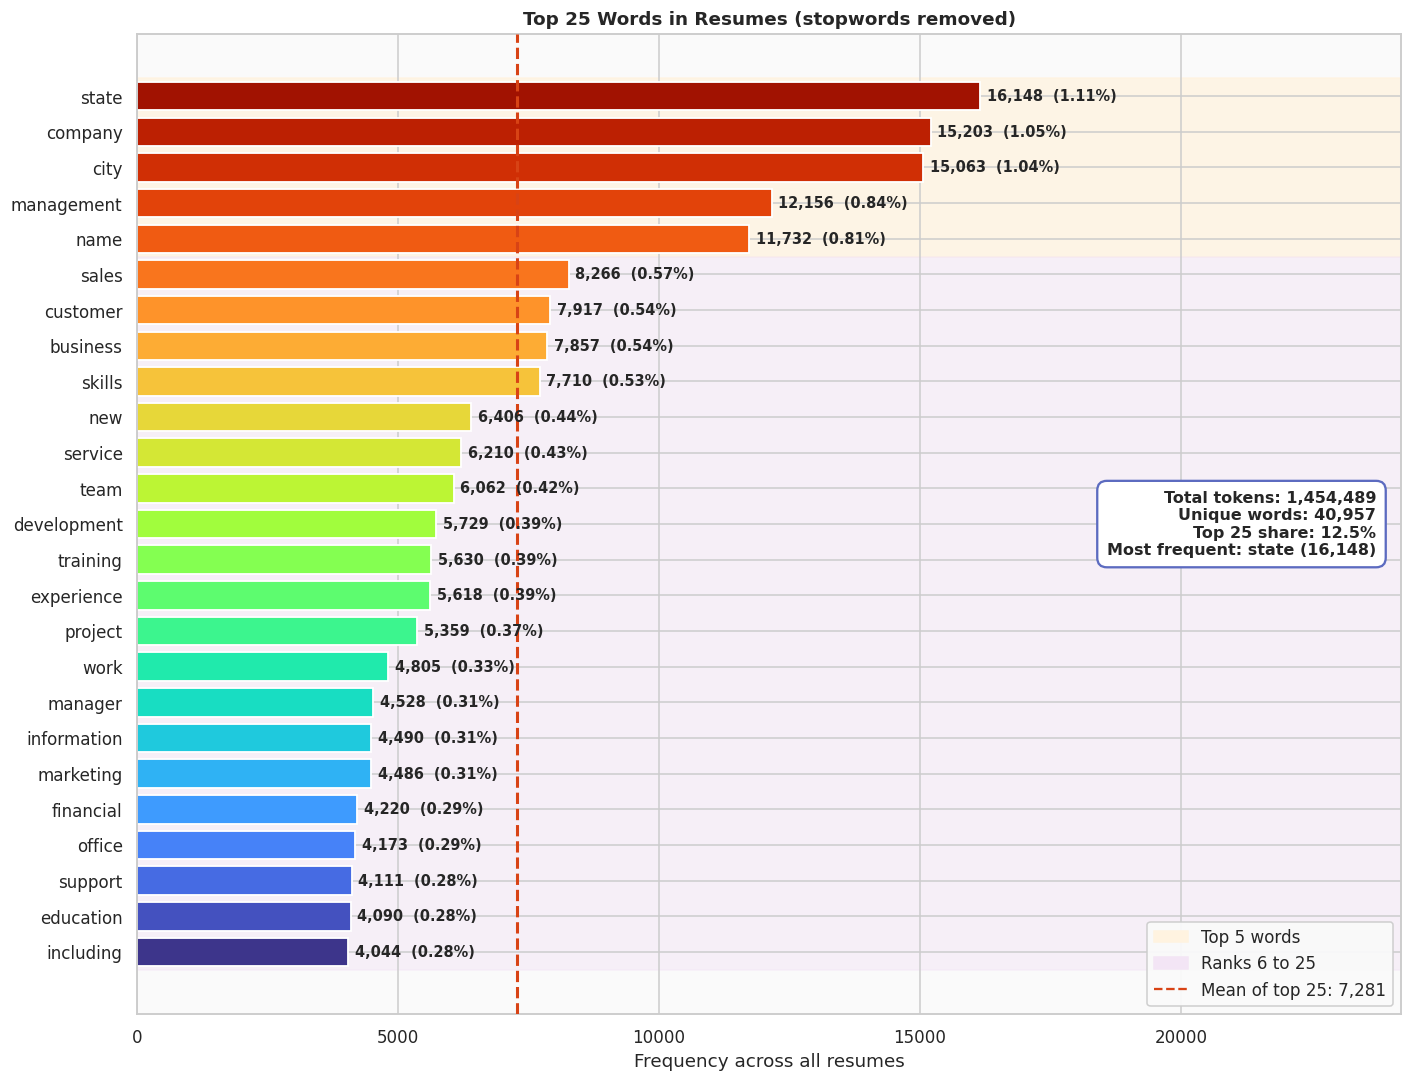

In [10]:
def token_list(t):
    return [x for x in t.split() if len(x) > 2 and not x.isdigit()]

global_counter = Counter()
for t in resumes['resume_nostop']:
    global_counter.update(token_list(t))

top_n = 25
top_words = global_counter.most_common(top_n)
words, freqs = zip(*top_words[::-1])
total_tokens = sum(global_counter.values())
avg_top = np.mean(freqs)

fig, ax = plt.subplots(figsize=(13, 10))
ax.axhspan(top_n - 5.5, top_n - 0.5, color='#fff3e0', alpha=0.8, zorder=0)
ax.axhspan(-0.5, top_n - 5.5, color='#f3e5f5', alpha=0.5, zorder=0)
bars = ax.barh(words, freqs, color=plt.cm.turbo(np.linspace(0.05, 0.95, top_n)), edgecolor='white', linewidth=1.2, zorder=2)
ax.axvline(avg_top, color='#d84315', linestyle='--', linewidth=2, zorder=3)
for b, f in zip(bars, freqs):
    ax.text(f + max(freqs) * 0.008, b.get_y() + b.get_height() / 2, f'{f:,}  ({f / total_tokens * 100:.2f}%)',
            va='center', fontsize=9.5, fontweight='bold')
ax.set_xlim(0, max(freqs) * 1.5)
ax.set_xlabel('Frequency across all resumes')
ax.set_title('Top 25 Words in Resumes (stopwords removed)')
kpi = (f'Total tokens: {total_tokens:,}\nUnique words: {len(global_counter):,}\n'
       f'Top 25 share: {sum(freqs) / total_tokens * 100:.1f}%\nMost frequent: {top_words[0][0]} ({top_words[0][1]:,})')
ax.text(0.98, 0.5, kpi, transform=ax.transAxes, ha='right', va='center', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
handles = [Patch(color='#fff3e0', label='Top 5 words'), Patch(color='#f3e5f5', label='Ranks 6 to 25'),
           plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Mean of top 25: {avg_top:,.0f}')]
ax.legend(handles=handles, loc='lower right', framealpha=0.95)
plt.tight_layout()
plt.show()

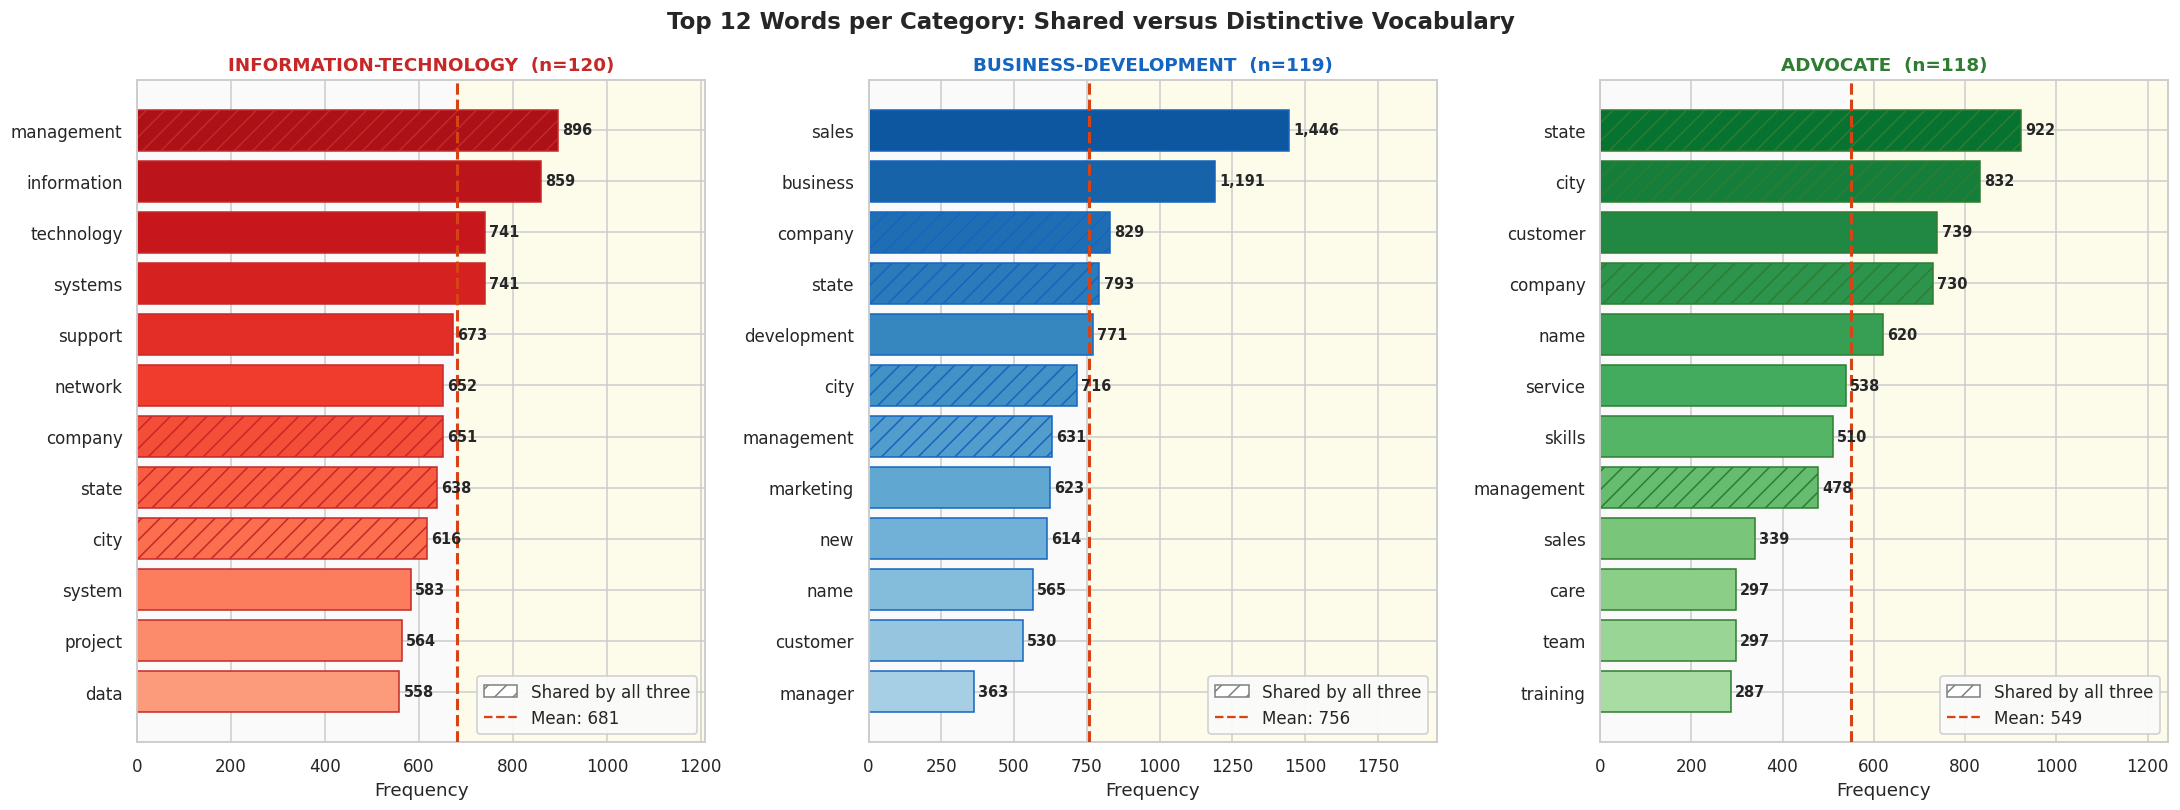

INFORMATION-TECHNOLOGY distinctive: ['information', 'technology', 'systems', 'support', 'network', 'system', 'project', 'data']
BUSINESS-DEVELOPMENT distinctive: ['sales', 'business', 'development', 'marketing', 'new', 'name', 'customer', 'manager']
ADVOCATE distinctive: ['customer', 'name', 'service', 'skills', 'sales', 'care', 'team', 'training']
shared: ['city', 'company', 'management', 'state']


In [11]:
cat_top = {}
for c in TOP_CATS:
    cnt = Counter()
    for t in resumes.loc[resumes[RESUME_CAT] == c, 'resume_nostop']:
        cnt.update(token_list(t))
    cat_top[c] = cnt.most_common(12)

shared = set.intersection(*[set(wd for wd, _ in v) for v in cat_top.values()])
cmaps = [plt.cm.Reds, plt.cm.Blues, plt.cm.Greens]
edge_cols = ['#c62828', '#1565c0', '#2e7d32']

fig, axes = plt.subplots(1, 3, figsize=(20, 7.5))
for ax, c, cmap, ec in zip(axes, TOP_CATS, cmaps, edge_cols):
    wd, fr = zip(*cat_top[c][::-1])
    m = np.mean(fr)
    ax.axvspan(m, max(fr) * 1.35, color='#fffde7', alpha=0.8, zorder=0)
    bars = ax.barh(wd, fr, color=cmap(np.linspace(0.85, 0.35, len(fr))[::-1]), edgecolor=ec, linewidth=1, zorder=2)
    for b, word in zip(bars, wd):
        if word in shared:
            b.set_hatch('//')
    ax.axvline(m, color='#d84315', linestyle='--', linewidth=2, zorder=3)
    for b, f in zip(bars, fr):
        ax.text(f + max(fr) * 0.01, b.get_y() + b.get_height() / 2, f'{f:,}', va='center', fontsize=9.5, fontweight='bold')
    n_c = int((resumes[RESUME_CAT] == c).sum())
    ax.set_xlim(0, max(fr) * 1.35)
    ax.set_title(f'{c}  (n={n_c})', color=ec)
    ax.set_xlabel('Frequency')
    ax.legend(handles=[Patch(facecolor='white', edgecolor='grey', hatch='//', label='Shared by all three'),
                       plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Mean: {m:,.0f}')],
              loc='lower right', framealpha=0.95)
fig.suptitle('Top 12 Words per Category: Shared versus Distinctive Vocabulary', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

for c in TOP_CATS:
    print(c, 'distinctive:', [wd for wd, _ in cat_top[c] if wd not in shared])
print('shared:', sorted(shared))

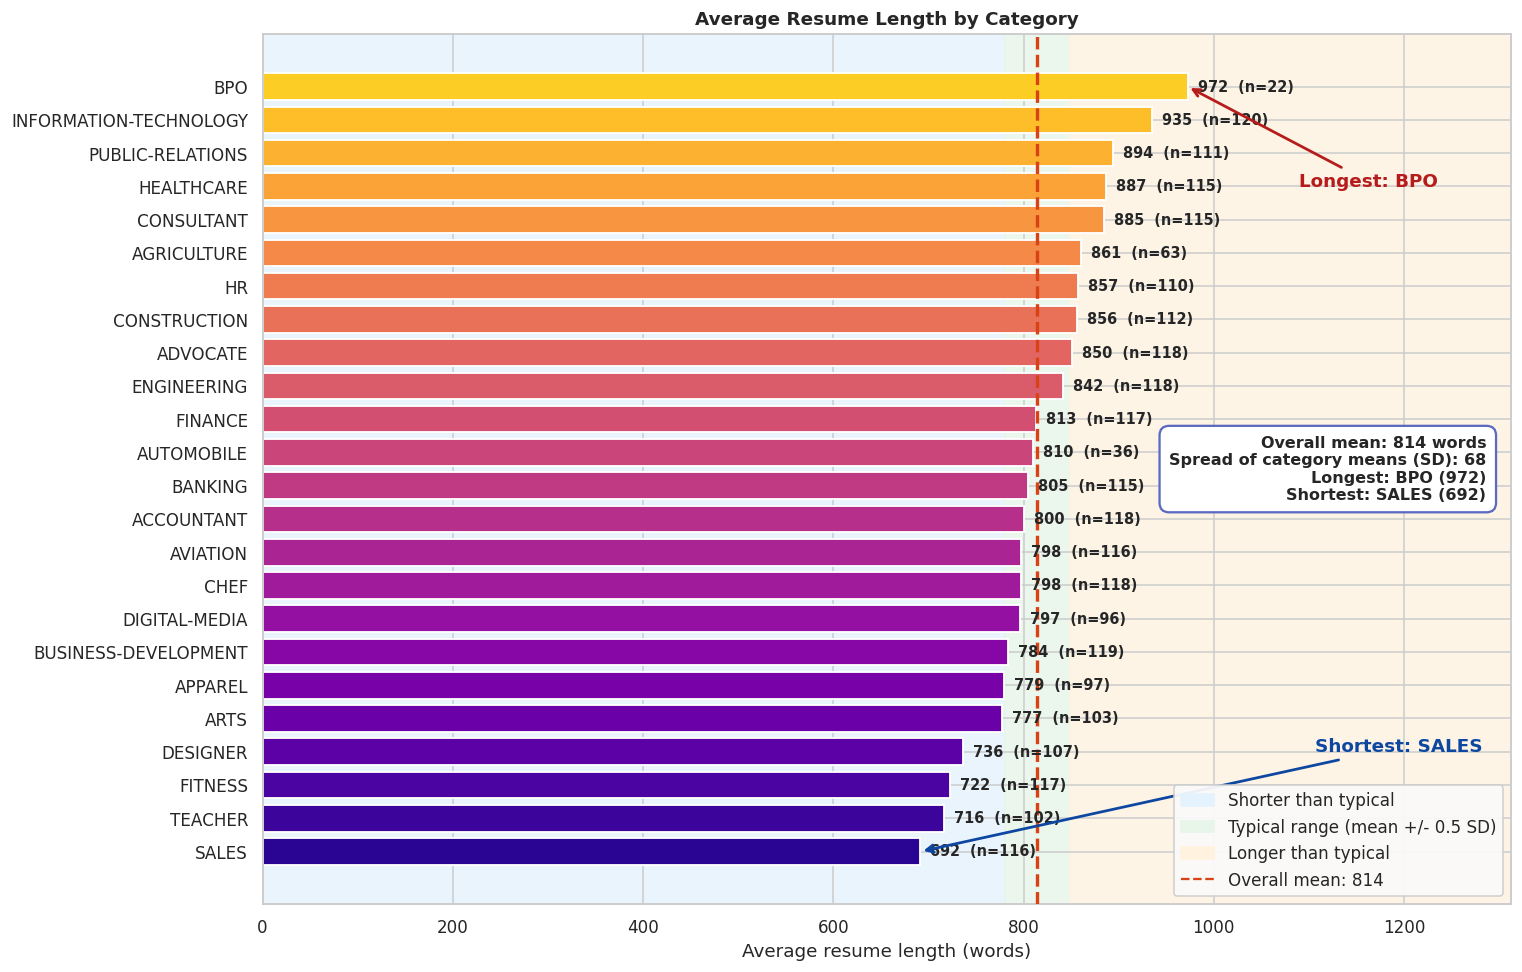

In [12]:
avg_len = resumes.groupby(RESUME_CAT)['resume_words'].agg(['mean', 'median', 'count']).sort_values('mean')
g_mean = resumes['resume_words'].mean()
sd = avg_len['mean'].std()
lo, hi = g_mean - 0.5 * sd, g_mean + 0.5 * sd
xmax = avg_len['mean'].max() * 1.35

fig, ax = plt.subplots(figsize=(14, 9))
ax.axvspan(0, lo, color='#e3f2fd', alpha=0.7, zorder=0)
ax.axvspan(lo, hi, color='#e8f5e9', alpha=0.8, zorder=0)
ax.axvspan(hi, xmax, color='#fff3e0', alpha=0.8, zorder=0)
bars = ax.barh(avg_len.index, avg_len['mean'], color=plt.cm.plasma(np.linspace(0.05, 0.9, len(avg_len))),
               edgecolor='white', linewidth=1.2, zorder=2)
ax.axvline(g_mean, color='#d84315', linestyle='--', linewidth=2.2, zorder=3)
for b, (c, r) in zip(bars, avg_len.iterrows()):
    ax.text(r['mean'] + xmax * 0.008, b.get_y() + b.get_height() / 2, f"{r['mean']:.0f}  (n={int(r['count'])})",
            va='center', fontsize=9.5, fontweight='bold')
top_c, bot_c = avg_len['mean'].idxmax(), avg_len['mean'].idxmin()
ax.annotate(f'Longest: {top_c}', xy=(avg_len['mean'].max(), len(avg_len) - 1),
            xytext=(avg_len['mean'].max() * 1.12, len(avg_len) - 4), fontweight='bold', color='#b71c1c',
            arrowprops=dict(arrowstyle='->', color='#b71c1c', linewidth=1.8))
ax.annotate(f'Shortest: {bot_c}', xy=(avg_len['mean'].min(), 0),
            xytext=(avg_len['mean'].min() * 1.6, 3), fontweight='bold', color='#0d47a1',
            arrowprops=dict(arrowstyle='->', color='#0d47a1', linewidth=1.8))
ax.set_xlim(0, xmax)
ax.set_xlabel('Average resume length (words)')
ax.set_title('Average Resume Length by Category')
kpi = (f'Overall mean: {g_mean:.0f} words\nSpread of category means (SD): {sd:.0f}\n'
       f'Longest: {top_c} ({avg_len["mean"].max():.0f})\nShortest: {bot_c} ({avg_len["mean"].min():.0f})')
ax.text(0.98, 0.5, kpi, transform=ax.transAxes, ha='right', va='center', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
handles = [Patch(color='#e3f2fd', label='Shorter than typical'), Patch(color='#e8f5e9', label='Typical range (mean +/- 0.5 SD)'),
           Patch(color='#fff3e0', label='Longer than typical'),
           plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Overall mean: {g_mean:.0f}')]
ax.legend(handles=handles, loc='lower right', framealpha=0.95)
plt.tight_layout()
plt.show()

# **Job-Side EDA**

In [13]:
SOFT_SKILLS = {
    'communication', 'problem solving', 'adaptability', 'teamwork', 'collaboration', 'leadership',
    'time management', 'interpersonal skills', 'customer service', 'relationship building',
    'attention to detail', 'organizational skills', 'negotiation', 'critical thinking', 'creativity',
    'decision making', 'conflict resolution', 'active listening', 'multitasking', 'work ethic',
    'emotional intelligence', 'flexibility', 'initiative', 'professionalism', 'presentation skills',
    'public speaking', 'strategic thinking', 'analytical skills', 'stakeholder management', 'mentoring',
    'coaching', 'planning', 'verbal communication', 'written communication', 'team leadership',
    'organization', 'people management', 'influencing', 'persuasion', 'empathy', 'self-motivation',
    'resilience', 'accountability', 'relationship management', 'team collaboration',
    'communication skills', 'problem-solving', 'decision-making', 'time-management', 'team player'
}
BOILERPLATE = {'company', 'name', 'city', 'state'}

jobs['title_norm'] = (jobs[JOB_TITLE].str.lower()
                      .str.replace(r'\(.*?\)', ' ', regex=True)
                      .str.replace(r'[^a-z0-9 ]', ' ', regex=True)
                      .str.replace(r'\s+', ' ', regex=True).str.strip().str.title())
jobs['n_soft'] = jobs['skills_list'].apply(lambda l: sum(s in SOFT_SKILLS for s in l))
jobs['n_tech'] = jobs['n_skills'] - jobs['n_soft']

title_counts = jobs['title_norm'].value_counts()
total_mentions = sum(skill_counter.values())
vocab_set = set(skills_vocab)
vocab_mention_cov = sum(c for s, c in skill_counter.items() if s in vocab_set) / total_mentions * 100
soft_share = jobs['n_soft'].sum() / jobs['n_skills'].sum() * 100

print('unique raw titles:', jobs[JOB_TITLE].nunique(), '| unique normalised titles:', title_counts.shape[0])
print('titles appearing once:', int((title_counts == 1).sum()))
print('total skill mentions:', total_mentions)
print('soft skill share of mentions (%):', round(soft_share, 2))
print('vocabulary coverage of skill mentions (%):', round(vocab_mention_cov, 2))
display(jobs[['n_skills', 'n_soft', 'n_tech']].describe().round(2))

unique raw titles: 723 | unique normalised titles: 686
titles appearing once: 581
total skill mentions: 20748
soft skill share of mentions (%): 34.86
vocabulary coverage of skill mentions (%): 78.02


,n_skills,n_soft,n_tech
count,1167.00,1167.00,1167.00
mean,17.78,6.20,11.58
std,4.95,1.98,4.22
min,5.00,0.00,0.00
25%,15.00,5.00,9.00
50%,17.00,6.00,11.00
75%,20.00,7.00,14.00
max,41.00,14.00,31.00


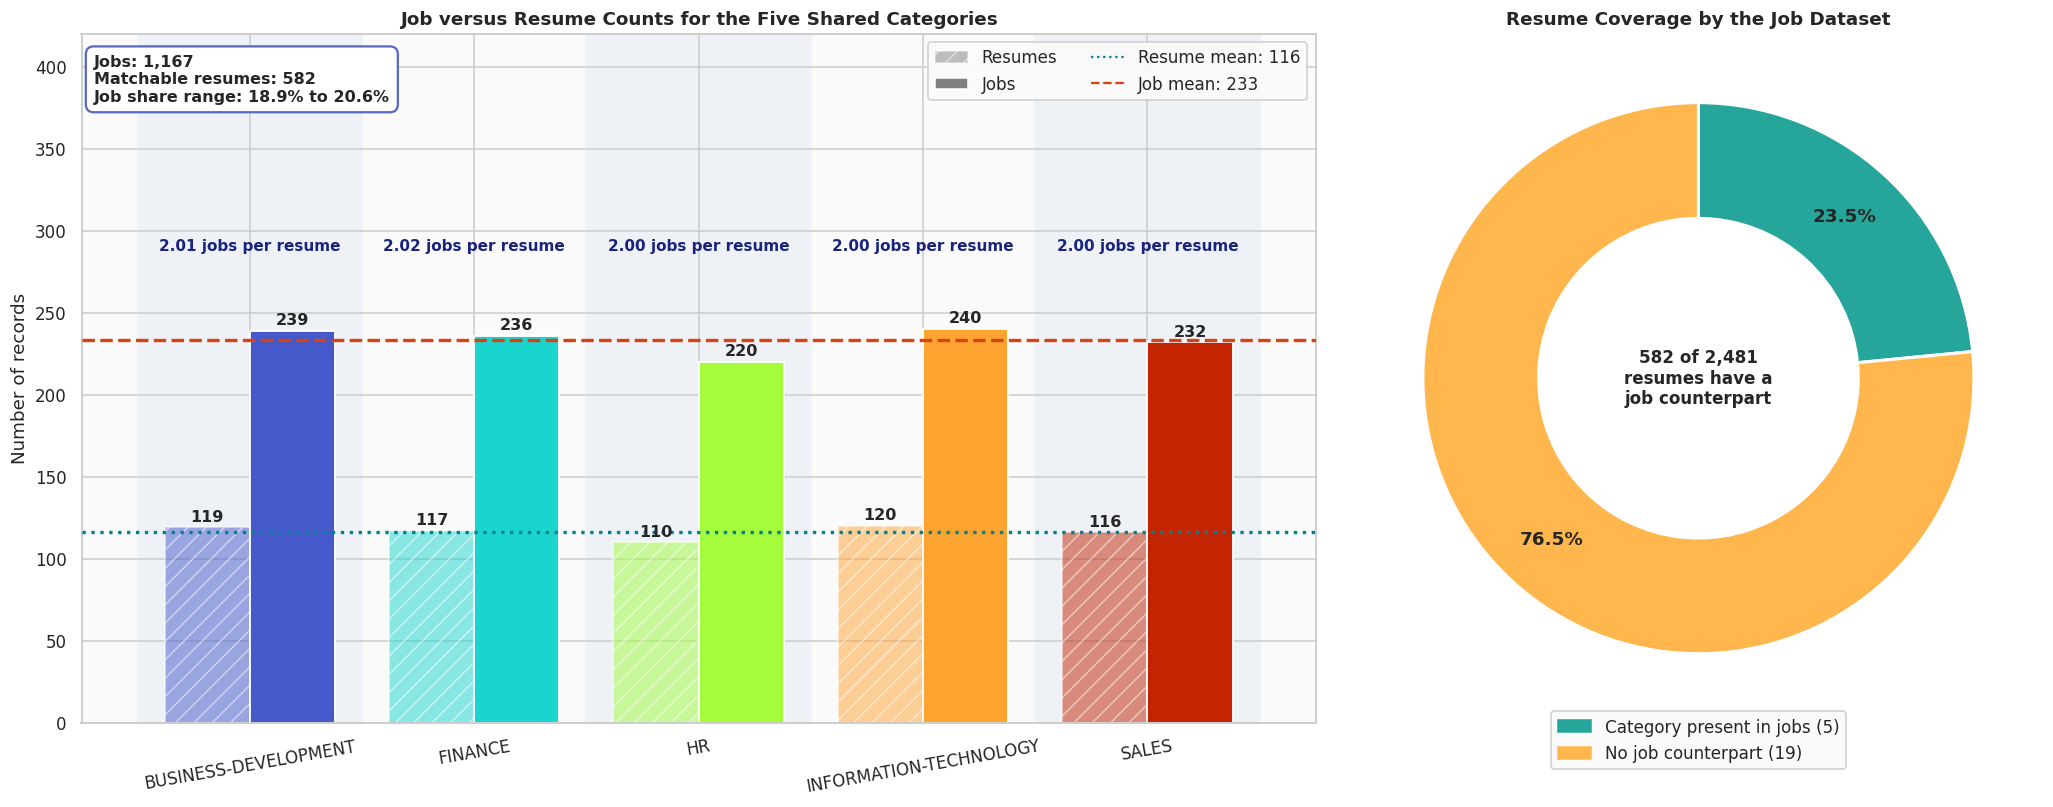

In [14]:
cats = sorted(JOB_MATCHABLE)
CAT_COLORS = dict(zip(cats, plt.cm.turbo(np.linspace(0.1, 0.9, len(cats)))))
res_c = resumes[RESUME_CAT].value_counts().reindex(cats)
job_c = jobs[JOB_CAT].value_counts().reindex(cats)
x = np.arange(len(cats))
bw = 0.38
top_y = max(res_c.max(), job_c.max())
n_with = int(resumes[RESUME_CAT].isin(cats).sum())
cols = [CAT_COLORS[c] for c in cats]

fig, axes = plt.subplots(1, 2, figsize=(19, 7.5), gridspec_kw={'width_ratios': [1.7, 1]})
ax = axes[0]
for i in x[::2]:
    ax.axvspan(i - 0.5, i + 0.5, color='#eef2f7', zorder=0)
b1 = ax.bar(x - bw / 2, res_c.values, bw, color=cols, alpha=0.5, hatch='//', edgecolor='white', linewidth=1.2, zorder=2)
b2 = ax.bar(x + bw / 2, job_c.values, bw, color=cols, edgecolor='white', linewidth=1.2, zorder=2)
ax.axhline(res_c.mean(), color='#00838f', linestyle=':', linewidth=2.2, zorder=3)
ax.axhline(job_c.mean(), color='#d84315', linestyle='--', linewidth=2.2, zorder=3)
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + top_y * 0.015, f'{int(b.get_height())}',
                ha='center', fontsize=10.5, fontweight='bold')
for i, c in enumerate(cats):
    ax.text(i, top_y * 1.2, f'{job_c[c] / res_c[c]:.2f} jobs per resume', ha='center', fontsize=10, fontweight='bold', color='#1a237e')
ax.set_xticks(x)
ax.set_xticklabels(cats, rotation=10)
ax.set_ylim(0, top_y * 1.75)
ax.set_ylabel('Number of records')
ax.set_title('Job versus Resume Counts for the Five Shared Categories')
kpi = (f'Jobs: {len(jobs):,}\nMatchable resumes: {n_with:,}\nJob share range: {job_c.min() / len(jobs) * 100:.1f}% to {job_c.max() / len(jobs) * 100:.1f}%')
ax.text(0.01, 0.97, kpi, transform=ax.transAxes, va='top', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
handles = [Patch(facecolor='grey', alpha=0.5, hatch='//', label='Resumes'), Patch(facecolor='grey', label='Jobs'),
           plt.Line2D([0], [0], color='#00838f', linestyle=':', label=f'Resume mean: {res_c.mean():.0f}'),
           plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Job mean: {job_c.mean():.0f}')]
ax.legend(handles=handles, loc='upper right', ncol=2, framealpha=0.95)

ax2 = axes[1]
ax2.pie([n_with, len(resumes) - n_with], colors=['#26a69a', '#ffb74d'], startangle=90, counterclock=False,
        wedgeprops=dict(width=0.42, edgecolor='white', linewidth=2),
        autopct=lambda p: f'{p:.1f}%', pctdistance=0.79, textprops=dict(fontweight='bold', fontsize=12))
ax2.text(0, 0, f'{n_with:,} of {len(resumes):,}\nresumes have a\njob counterpart', ha='center', va='center', fontsize=11, fontweight='bold')
ax2.legend(handles=[Patch(color='#26a69a', label='Category present in jobs (5)'), Patch(color='#ffb74d', label='No job counterpart (19)')],
           loc='lower center', bbox_to_anchor=(0.5, -0.08), framealpha=0.95)
ax2.set_title('Resume Coverage by the Job Dataset')
plt.tight_layout()
plt.show()

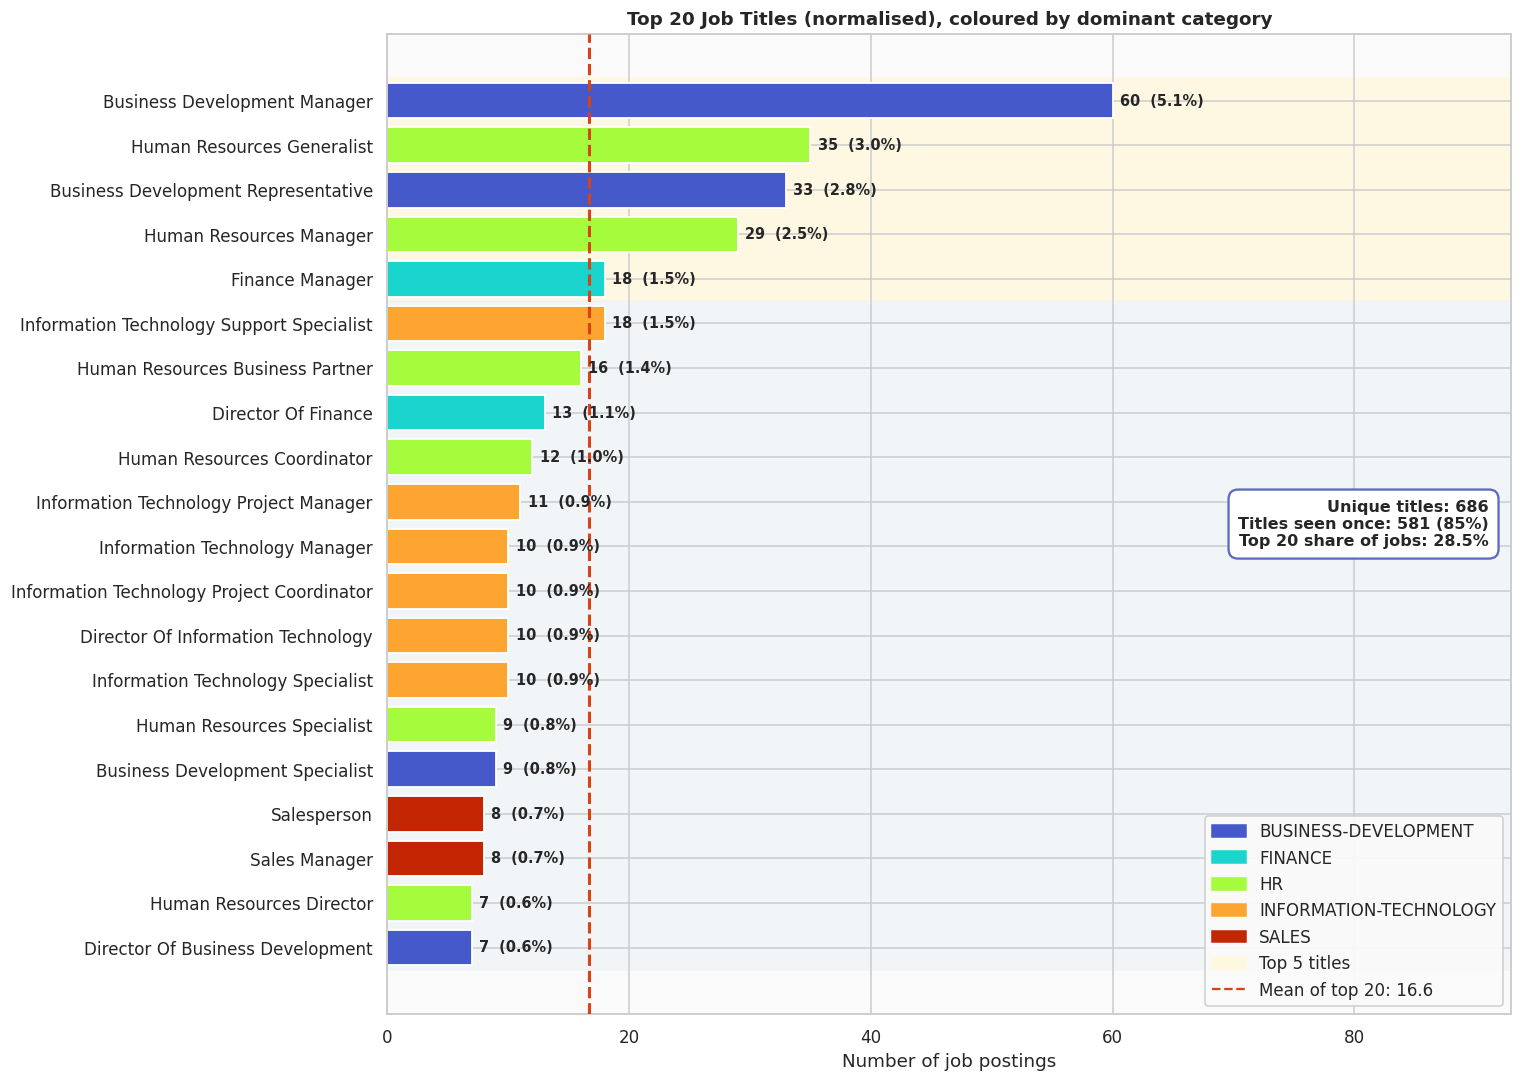

In [15]:
top_t = title_counts.head(20).sort_values()
title_cat = jobs.groupby('title_norm')[JOB_CAT].agg(lambda s: s.mode().iloc[0])
mean_t = top_t.mean()
n_t = len(top_t)

fig, ax = plt.subplots(figsize=(14, 10))
ax.axhspan(n_t - 5.5, n_t - 0.5, color='#fff8e1', alpha=0.9, zorder=0)
ax.axhspan(-0.5, n_t - 5.5, color='#eef2f7', alpha=0.6, zorder=0)
bars = ax.barh(top_t.index, top_t.values, color=[CAT_COLORS[title_cat[t]] for t in top_t.index],
               edgecolor='white', linewidth=1.2, zorder=2)
ax.axvline(mean_t, color='#d84315', linestyle='--', linewidth=2, zorder=3)
for b, v in zip(bars, top_t.values):
    ax.text(v + top_t.max() * 0.01, b.get_y() + b.get_height() / 2, f'{v}  ({v / len(jobs) * 100:.1f}%)',
            va='center', fontsize=9.5, fontweight='bold')
ax.set_xlim(0, top_t.max() * 1.55)
ax.set_xlabel('Number of job postings')
ax.set_title('Top 20 Job Titles (normalised), coloured by dominant category')
kpi = (f'Unique titles: {title_counts.shape[0]}\nTitles seen once: {int((title_counts == 1).sum())} '
       f'({(title_counts == 1).mean() * 100:.0f}%)\nTop 20 share of jobs: {top_t.sum() / len(jobs) * 100:.1f}%')
ax.text(0.98, 0.5, kpi, transform=ax.transAxes, ha='right', va='center', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
handles = [Patch(color=CAT_COLORS[c], label=c) for c in cats]
handles += [Patch(color='#fff8e1', label='Top 5 titles'), plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Mean of top 20: {mean_t:.1f}')]
ax.legend(handles=handles, loc='lower right', framealpha=0.95)
plt.tight_layout()
plt.show()

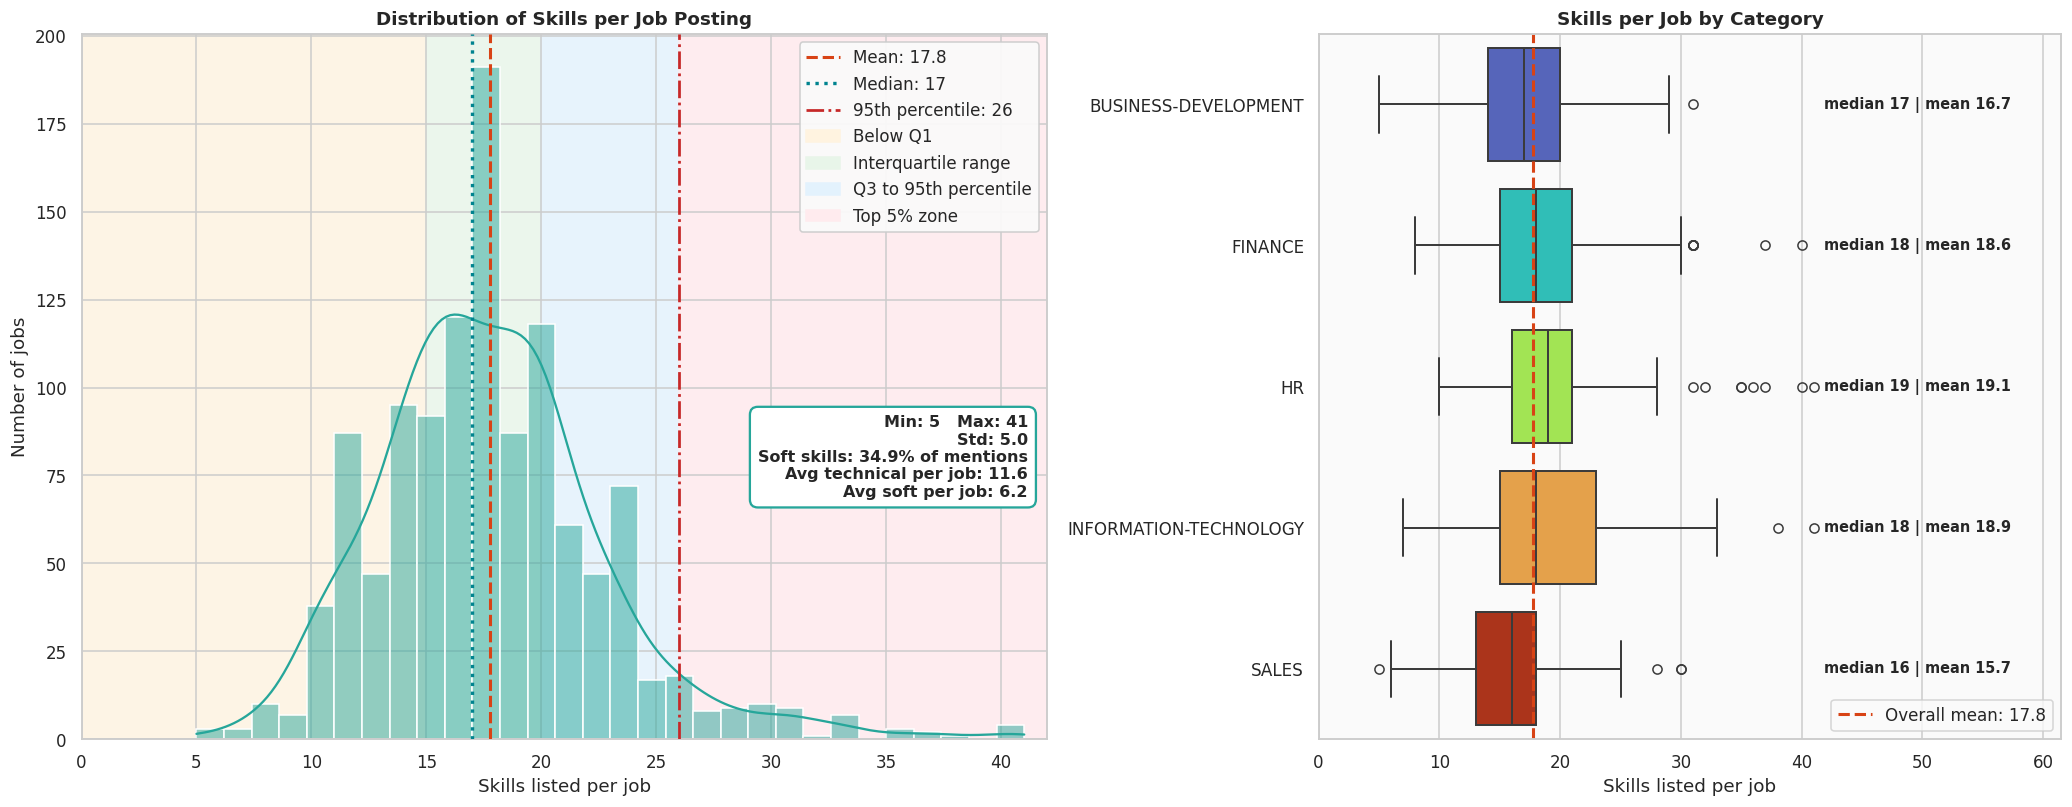

In [16]:
s = jobs['n_skills']
q1, q3 = s.quantile([0.25, 0.75])
p95 = s.quantile(0.95)
xmax = s.max() + 1

fig, axes = plt.subplots(1, 2, figsize=(19, 7.5), gridspec_kw={'width_ratios': [1.3, 1]})
ax = axes[0]
ax.axvspan(0, q1, color='#fff3e0', alpha=0.8, zorder=0)
ax.axvspan(q1, q3, color='#e8f5e9', alpha=0.8, zorder=0)
ax.axvspan(q3, p95, color='#e3f2fd', alpha=0.8, zorder=0)
ax.axvspan(p95, xmax, color='#ffebee', alpha=0.9, zorder=0)
sns.histplot(s, bins=30, kde=True, color='#26a69a', edgecolor='white', ax=ax, zorder=2)
ax.axvline(s.mean(), color='#d84315', linestyle='--', linewidth=2, label=f'Mean: {s.mean():.1f}', zorder=3)
ax.axvline(s.median(), color='#00838f', linestyle=':', linewidth=2.2, label=f'Median: {s.median():.0f}', zorder=3)
ax.axvline(p95, color='#c62828', linestyle='-.', linewidth=1.8, label=f'95th percentile: {p95:.0f}', zorder=3)
ax.set_xlim(0, xmax)
ax.set_xlabel('Skills listed per job')
ax.set_ylabel('Number of jobs')
ax.set_title('Distribution of Skills per Job Posting')
kpi = (f'Min: {s.min()}   Max: {s.max()}\nStd: {s.std():.1f}\nSoft skills: {soft_share:.1f}% of mentions\n'
       f'Avg technical per job: {jobs["n_tech"].mean():.1f}\nAvg soft per job: {jobs["n_soft"].mean():.1f}')
ax.text(0.98, 0.4, kpi, transform=ax.transAxes, ha='right', va='center', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#26a69a', linewidth=1.5))
handles, labels = ax.get_legend_handles_labels()
handles += [Patch(color='#fff3e0'), Patch(color='#e8f5e9'), Patch(color='#e3f2fd'), Patch(color='#ffebee')]
labels += ['Below Q1', 'Interquartile range', 'Q3 to 95th percentile', 'Top 5% zone']
ax.legend(handles, labels, loc='upper right', framealpha=0.95)

ax2 = axes[1]
sns.boxplot(data=jobs, y=JOB_CAT, x='n_skills', order=cats, hue=JOB_CAT, palette=CAT_COLORS, legend=False,
            orient='h', linewidth=1.3, ax=ax2)
ax2.axvline(s.mean(), color='#d84315', linestyle='--', linewidth=2, label=f'Overall mean: {s.mean():.1f}')
for i, c in enumerate(cats):
    v = jobs.loc[jobs[JOB_CAT] == c, 'n_skills']
    ax2.text(s.max() * 1.02, i, f'median {v.median():.0f} | mean {v.mean():.1f}', va='center', fontsize=9.5, fontweight='bold')
ax2.set_xlim(0, s.max() * 1.5)
ax2.set_xlabel('Skills listed per job')
ax2.set_ylabel('')
ax2.set_title('Skills per Job by Category')
ax2.legend(loc='lower right')
plt.tight_layout()
plt.show()

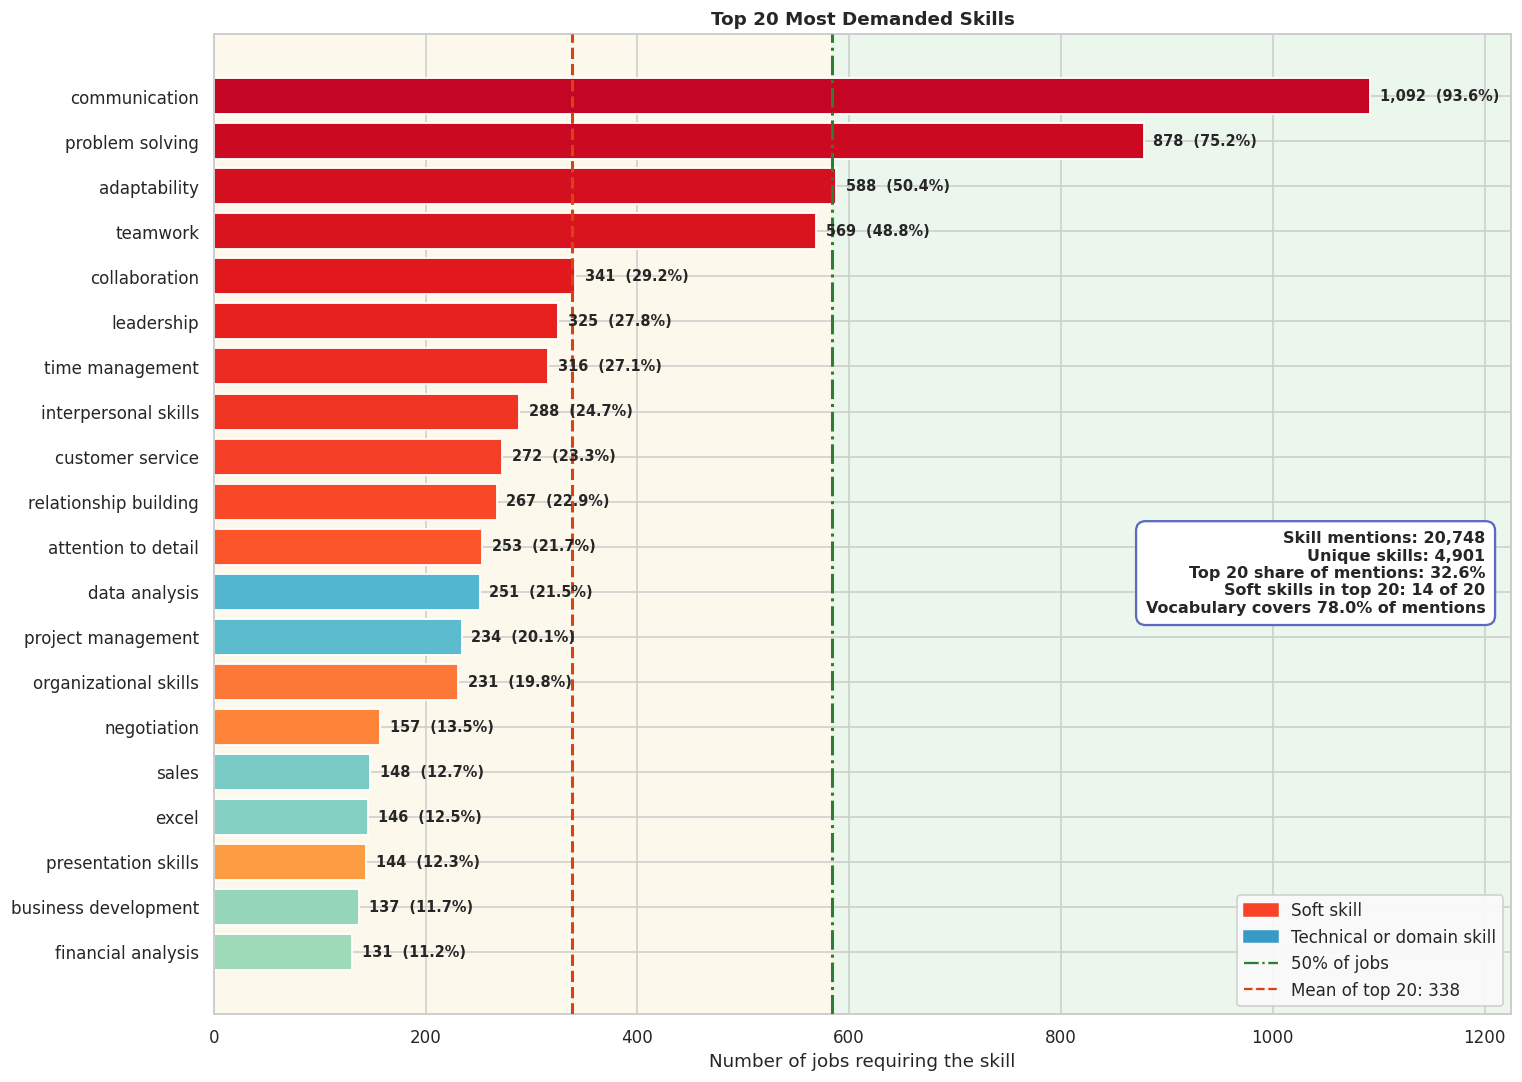

In [17]:
top20 = skill_counter.most_common(20)
rank_map = {k: i for i, (k, _) in enumerate(top20)}
n_j = len(jobs)

def skill_color(k):
    f = rank_map[k] / 19
    return plt.cm.YlOrRd(0.85 - 0.45 * f) if k in SOFT_SKILLS else plt.cm.GnBu(0.9 - 0.5 * f)

names = [k for k, _ in top20][::-1]
vals = [v for _, v in top20][::-1]
mean_v = np.mean(vals)
n_soft_top = sum(k in SOFT_SKILLS for k in names)

fig, ax = plt.subplots(figsize=(14, 10))
ax.axvspan(n_j * 0.5, n_j * 1.05, color='#e8f5e9', alpha=0.8, zorder=0)
ax.axvspan(0, n_j * 0.5, color='#fff8e1', alpha=0.6, zorder=0)
bars = ax.barh(names, vals, color=[skill_color(k) for k in names], edgecolor='white', linewidth=1.2, zorder=2)
ax.axvline(n_j * 0.5, color='#2e7d32', linestyle='-.', linewidth=2, zorder=3)
ax.axvline(mean_v, color='#d84315', linestyle='--', linewidth=2, zorder=3)
for b, v in zip(bars, vals):
    ax.text(v + n_j * 0.008, b.get_y() + b.get_height() / 2, f'{v:,}  ({v / n_j * 100:.1f}%)', va='center', fontsize=9.5, fontweight='bold')
ax.set_xlim(0, n_j * 1.05)
ax.set_xlabel('Number of jobs requiring the skill')
ax.set_title('Top 20 Most Demanded Skills')
kpi = (f'Skill mentions: {total_mentions:,}\nUnique skills: {len(skill_counter):,}\n'
       f'Top 20 share of mentions: {sum(vals) / total_mentions * 100:.1f}%\nSoft skills in top 20: {n_soft_top} of 20\n'
       f'Vocabulary covers {vocab_mention_cov:.1f}% of mentions')
ax.text(0.98, 0.45, kpi, transform=ax.transAxes, ha='right', va='center', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
handles = [Patch(color=plt.cm.YlOrRd(0.65), label='Soft skill'), Patch(color=plt.cm.GnBu(0.7), label='Technical or domain skill'),
           plt.Line2D([0], [0], color='#2e7d32', linestyle='-.', label='50% of jobs'),
           plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Mean of top 20: {mean_v:,.0f}')]
ax.legend(handles=handles, loc='lower right', framealpha=0.95)
plt.tight_layout()
plt.show()

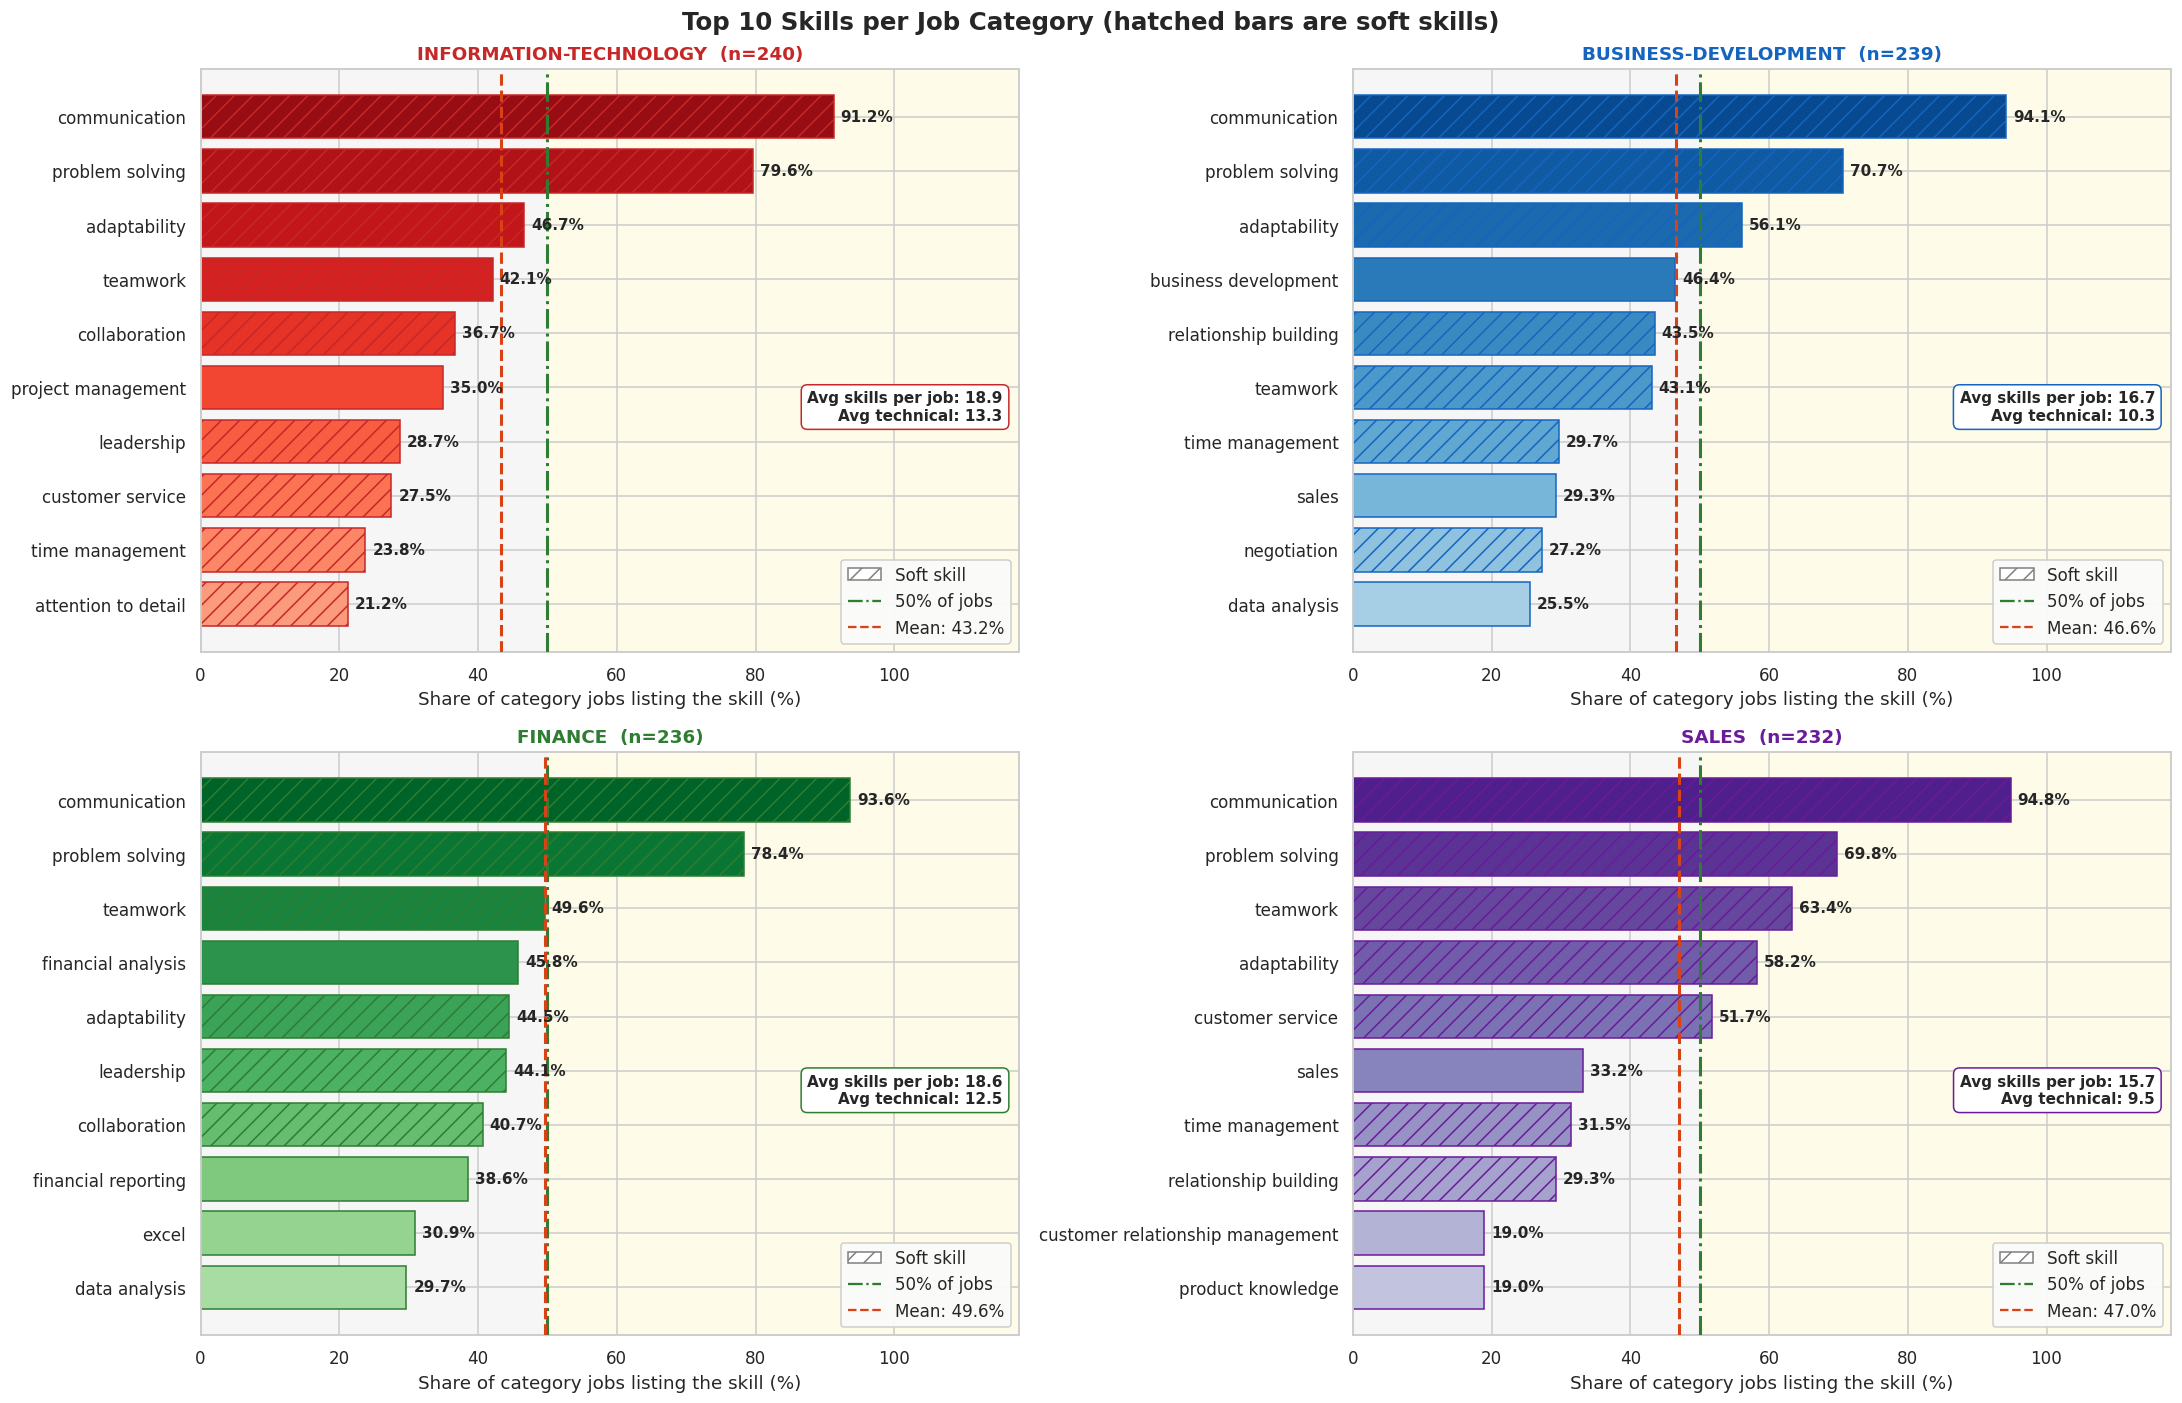

INFORMATION-TECHNOLOGY top technical skills: ['project management', 'troubleshooting', 'documentation', 'technical support', 'data analysis', 'active directory']
BUSINESS-DEVELOPMENT top technical skills: ['business development', 'sales', 'data analysis', 'market analysis', 'project management', 'lead generation']
FINANCE top technical skills: ['financial analysis', 'financial reporting', 'excel', 'data analysis', 'budgeting', 'accounting']
SALES top technical skills: ['sales', 'customer relationship management', 'product knowledge', 'inventory management', 'positive attitude', 'motivation']


In [18]:
top_job_cats = jobs[JOB_CAT].value_counts().head(4).index.tolist()
cmaps = [plt.cm.Reds, plt.cm.Blues, plt.cm.Greens, plt.cm.Purples]
edge_cols = ['#c62828', '#1565c0', '#2e7d32', '#6a1b9a']
cat_tech = {}

fig, axes = plt.subplots(2, 2, figsize=(20, 13))
for ax, c, cmap, ec in zip(axes.ravel(), top_job_cats, cmaps, edge_cols):
    sub = jobs[jobs[JOB_CAT] == c]
    cnt = Counter(sk for l in sub['skills_list'] for sk in l)
    cat_tech[c] = [k for k, _ in cnt.most_common(60) if k not in SOFT_SKILLS][:6]
    top = cnt.most_common(10)[::-1]
    names = [k for k, _ in top]
    pct = [v / len(sub) * 100 for _, v in top]
    ax.axvspan(50, 118, color='#fffde7', alpha=0.9, zorder=0)
    ax.axvspan(0, 50, color='#f5f5f5', alpha=0.7, zorder=0)
    bars = ax.barh(names, pct, color=cmap(np.linspace(0.35, 0.9, len(pct))), edgecolor=ec, linewidth=1, zorder=2)
    for b, n in zip(bars, names):
        if n in SOFT_SKILLS:
            b.set_hatch('//')
    ax.axvline(50, color='#2e7d32', linestyle='-.', linewidth=2, zorder=3)
    ax.axvline(np.mean(pct), color='#d84315', linestyle='--', linewidth=2, zorder=3)
    for b, p in zip(bars, pct):
        ax.text(p + 1, b.get_y() + b.get_height() / 2, f'{p:.1f}%', va='center', fontsize=10, fontweight='bold')
    ax.set_xlim(0, 118)
    ax.set_xlabel('Share of category jobs listing the skill (%)')
    ax.set_title(f'{c}  (n={len(sub)})', color=ec)
    ax.text(0.98, 0.42, f'Avg skills per job: {sub["n_skills"].mean():.1f}\nAvg technical: {sub["n_tech"].mean():.1f}',
            transform=ax.transAxes, ha='right', va='center', fontsize=10, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor=ec))
    ax.legend(handles=[Patch(facecolor='white', edgecolor='grey', hatch='//', label='Soft skill'),
                       plt.Line2D([0], [0], color='#2e7d32', linestyle='-.', label='50% of jobs'),
                       plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Mean: {np.mean(pct):.1f}%')],
              loc='lower right', framealpha=0.95)
fig.suptitle('Top 10 Skills per Job Category (hatched bars are soft skills)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

for c in top_job_cats:
    print(c, 'top technical skills:', cat_tech[c])

# **Combined EDA and Model Prep**

In [19]:
N_PAIRS = 500
rng = np.random.default_rng(SEED)
ri = rng.integers(0, len(resumes), N_PAIRS)
ji = rng.integers(0, len(jobs), N_PAIRS)

sample_pairs = pd.DataFrame({
    'resume_idx': ri,
    'job_idx': ji,
    'resume_cat': resumes[RESUME_CAT].values[ri],
    'job_cat': jobs[JOB_CAT].values[ji],
    'resume_words': resumes['resume_words'].values[ri],
    'jd_words': jobs['jd_words'].values[ji],
    'n_skills': jobs['n_skills'].values[ji],
    'n_tech': jobs['n_tech'].values[ji],
    'n_soft': jobs['n_soft'].values[ji]
})
sample_pairs['match'] = (sample_pairs['resume_cat'] == sample_pairs['job_cat']).astype(int)
sample_pairs['resume_matchable'] = sample_pairs['resume_cat'].isin(JOB_MATCHABLE)

p_res = resumes[RESUME_CAT].value_counts(normalize=True)
p_job = jobs[JOB_CAT].value_counts(normalize=True)
expected_match = sum(p_res[c] * p_job[c] for c in JOB_MATCHABLE)

print('pairs:', len(sample_pairs))
print('observed match rate (%):', round(sample_pairs['match'].mean() * 100, 2))
print('expected match rate by chance (%):', round(expected_match * 100, 2))
display(sample_pairs.head())

pairs: 500
observed match rate (%): 4.8
expected match rate by chance (%): 4.7


,resume_idx,job_idx,resume_cat,job_cat,resume_words,jd_words,n_skills,n_tech,n_soft,match,resume_matchable
0,221,132,INFORMATION-TECHNOLOGY,HR,566,1122,20,11,9,0,True
1,1920,760,ACCOUNTANT,FINANCE,1171,411,16,10,6,0,False
2,1623,1123,APPAREL,BUSINESS-DEVELOPMENT,911,274,13,8,5,0,False
3,1088,1012,SALES,BUSINESS-DEVELOPMENT,467,528,15,8,7,0,True
4,1074,319,SALES,INFORMATION-TECHNOLOGY,686,597,25,20,5,0,True


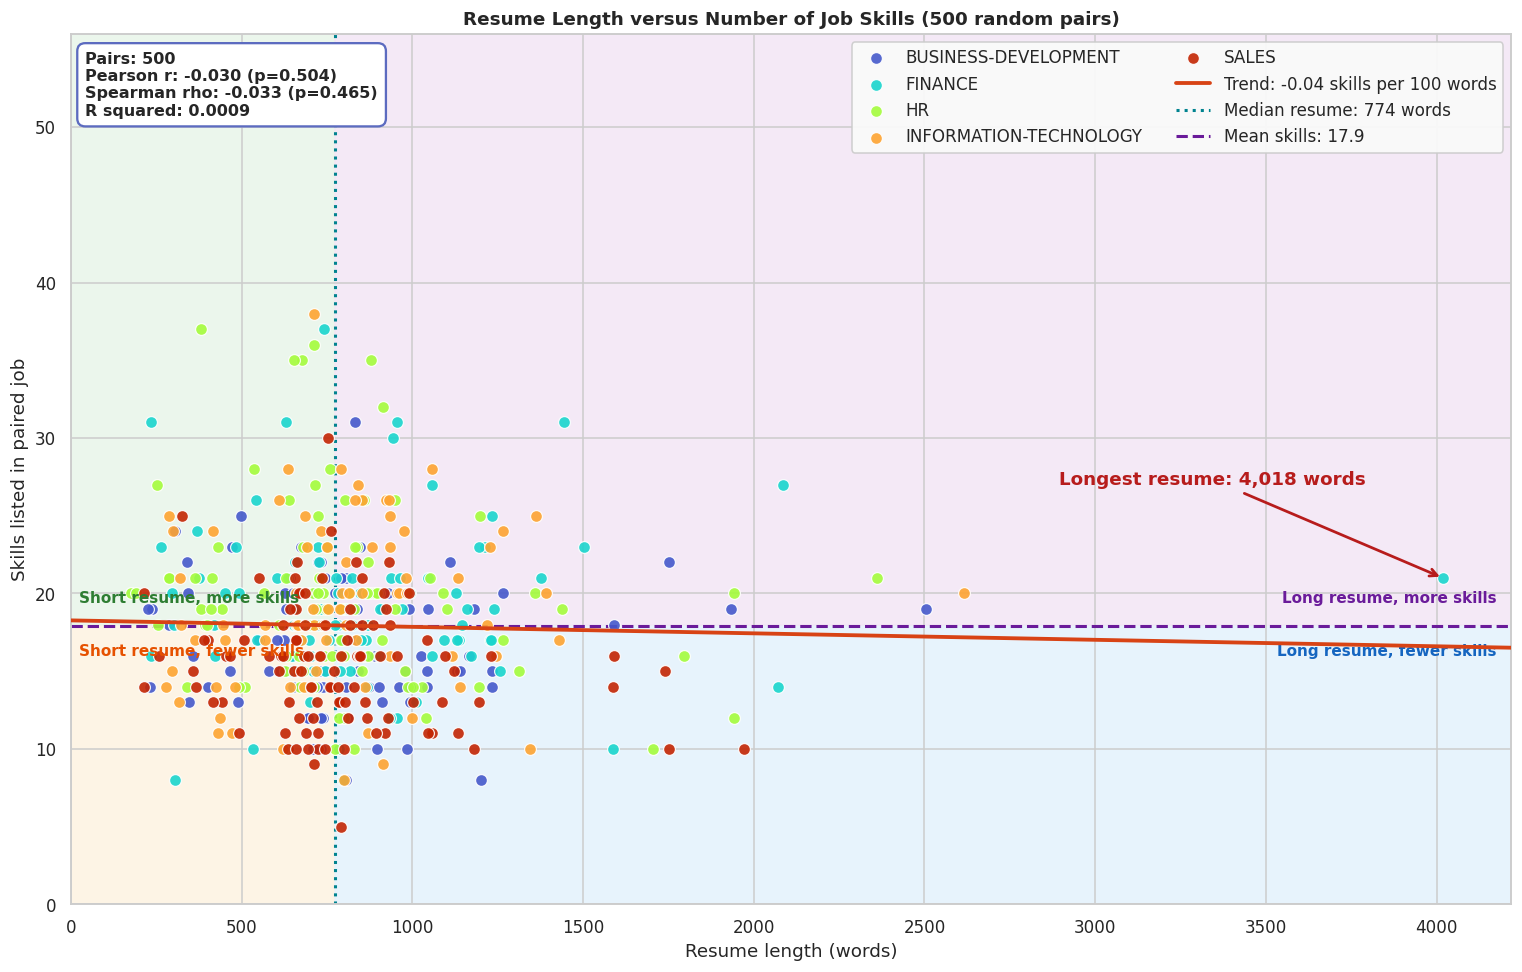

In [20]:
from scipy import stats

x, y = sample_pairs['resume_words'], sample_pairs['n_skills']
pr, pp = stats.pearsonr(x, y)
sr, sp = stats.spearmanr(x, y)
slope, intercept = np.polyfit(x, y, 1)
xm, ym = x.median(), y.median()
y0, y1 = 0, y.max() + 18
x1 = x.max() * 1.05
frac = (ym - y0) / (y1 - y0)

fig, ax = plt.subplots(figsize=(14, 9))
ax.axvspan(0, xm, ymin=0, ymax=frac, color='#fff3e0', alpha=0.8, zorder=0)
ax.axvspan(0, xm, ymin=frac, ymax=1, color='#e8f5e9', alpha=0.8, zorder=0)
ax.axvspan(xm, x1, ymin=0, ymax=frac, color='#e3f2fd', alpha=0.8, zorder=0)
ax.axvspan(xm, x1, ymin=frac, ymax=1, color='#f3e5f5', alpha=0.8, zorder=0)
for c in cats:
    m = sample_pairs['job_cat'] == c
    ax.scatter(x[m], y[m], s=60, color=CAT_COLORS[c], edgecolor='white', linewidth=0.8, alpha=0.9, zorder=3, label=c)
xs = np.linspace(0, x1, 100)
ax.plot(xs, slope * xs + intercept, color='#d84315', linewidth=2.5, zorder=4, label=f'Trend: {slope * 100:.2f} skills per 100 words')
ax.axvline(xm, color='#00838f', linestyle=':', linewidth=2, zorder=2, label=f'Median resume: {xm:.0f} words')
ax.axhline(y.mean(), color='#6a1b9a', linestyle='--', linewidth=2, zorder=2, label=f'Mean skills: {y.mean():.1f}')

ax.text(xm * 0.03, ym - 1.2, 'Short resume, fewer skills', fontsize=10, fontweight='bold', color='#e65100', va='top')
ax.text(xm * 0.03, ym + 1.2, 'Short resume, more skills', fontsize=10, fontweight='bold', color='#2e7d32', va='bottom')
ax.text(x1 * 0.99, ym - 1.2, 'Long resume, fewer skills', fontsize=10, fontweight='bold', color='#1565c0', va='top', ha='right')
ax.text(x1 * 0.99, ym + 1.2, 'Long resume, more skills', fontsize=10, fontweight='bold', color='#6a1b9a', va='bottom', ha='right')

imax = x.idxmax()
ax.annotate(f'Longest resume: {x[imax]:,} words', xy=(x[imax], y[imax]), xytext=(x[imax] * 0.72, y[imax] + 6),
            fontweight='bold', color='#b71c1c', arrowprops=dict(arrowstyle='->', color='#b71c1c', linewidth=1.8))

ax.set_xlim(0, x1)
ax.set_ylim(y0, y1)
ax.set_xlabel('Resume length (words)')
ax.set_ylabel('Skills listed in paired job')
ax.set_title('Resume Length versus Number of Job Skills (500 random pairs)')
kpi = (f'Pairs: {len(sample_pairs)}\nPearson r: {pr:.3f} (p={pp:.3f})\nSpearman rho: {sr:.3f} (p={sp:.3f})\n'
       f'R squared: {pr ** 2:.4f}')
ax.text(0.01, 0.98, kpi, transform=ax.transAxes, va='top', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
ax.legend(loc='upper right', ncol=2, framealpha=0.95)
plt.tight_layout()
plt.show()

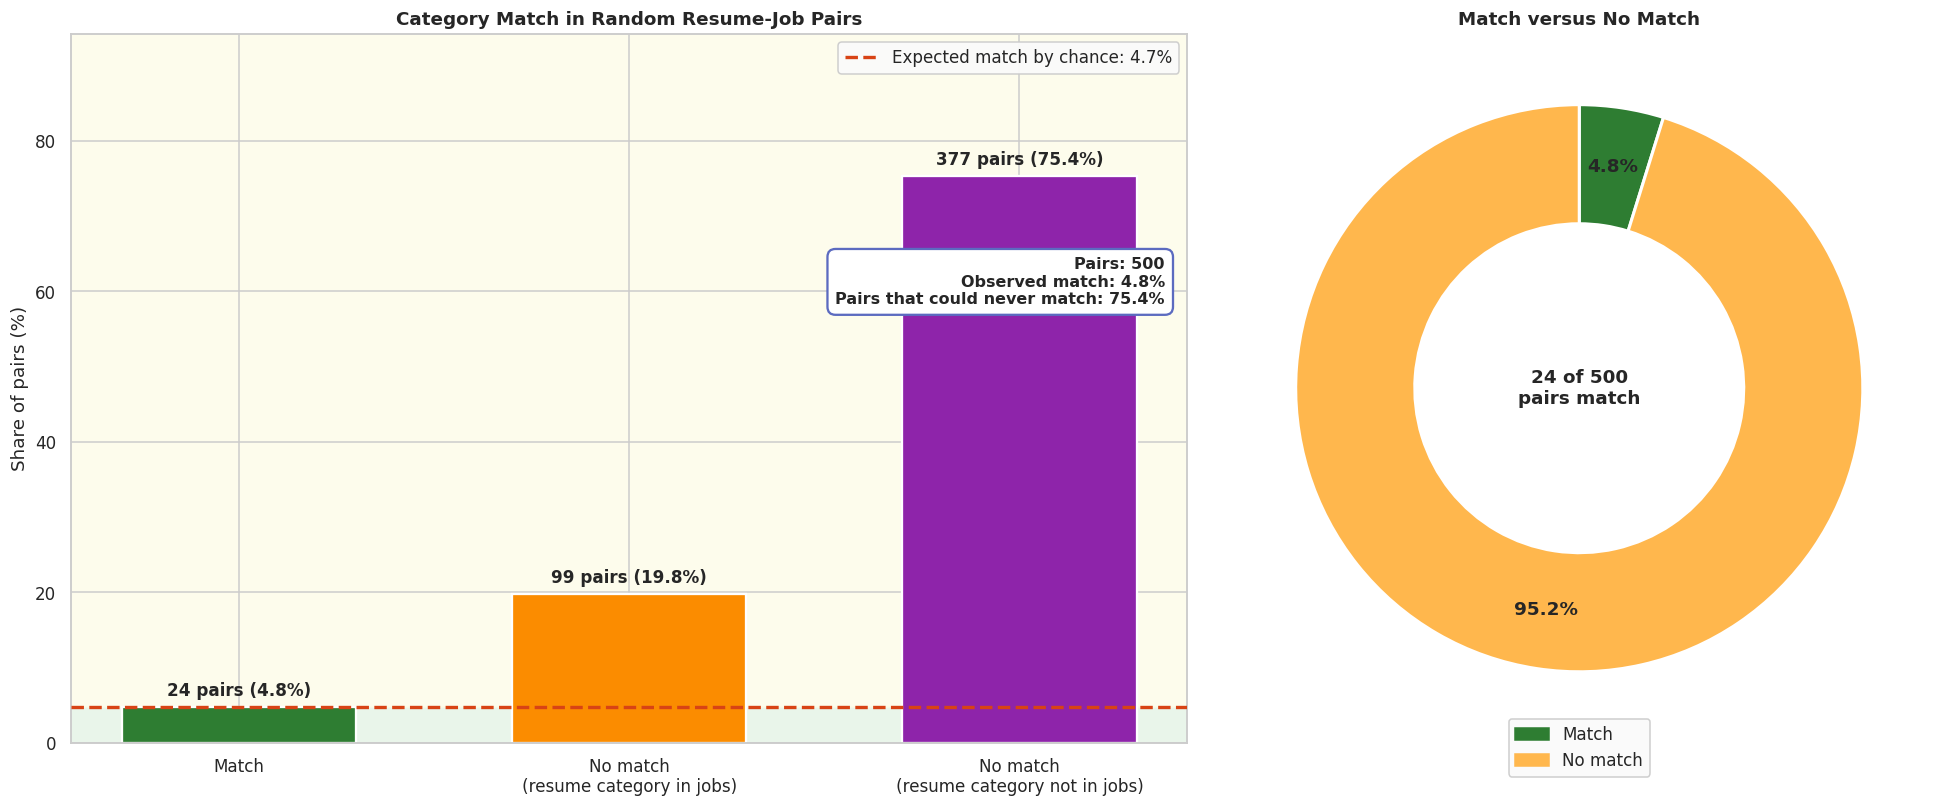

In [21]:
n = len(sample_pairs)
n_match = int(sample_pairs['match'].sum())
n_nm_possible = int(((sample_pairs['match'] == 0) & sample_pairs['resume_matchable']).sum())
n_nm_impossible = int((~sample_pairs['resume_matchable']).sum())
vals = np.array([n_match, n_nm_possible, n_nm_impossible])
pct = vals / n * 100
labels = ['Match', 'No match\n(resume category in jobs)', 'No match\n(resume category not in jobs)']
colors = ['#2e7d32', '#fb8c00', '#8e24aa']

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), gridspec_kw={'width_ratios': [1.5, 1]})
ax = axes[0]
ax.axhspan(0, expected_match * 100, color='#e8f5e9', alpha=0.9, zorder=0)
ax.axhspan(expected_match * 100, 100, color='#fffde7', alpha=0.7, zorder=0)
bars = ax.bar(labels, pct, color=colors, edgecolor='white', linewidth=1.5, width=0.6, zorder=2)
ax.axhline(expected_match * 100, color='#d84315', linestyle='--', linewidth=2.2, zorder=3,
           label=f'Expected match by chance: {expected_match * 100:.1f}%')
for b, v, p in zip(bars, vals, pct):
    ax.text(b.get_x() + b.get_width() / 2, p + 1.5, f'{v} pairs ({p:.1f}%)', ha='center', fontsize=11, fontweight='bold')
ax.set_ylim(0, pct.max() * 1.25)
ax.set_ylabel('Share of pairs (%)')
ax.set_title('Category Match in Random Resume-Job Pairs')
kpi = f'Pairs: {n}\nObserved match: {n_match / n * 100:.1f}%\nPairs that could never match: {n_nm_impossible / n * 100:.1f}%'
ax.text(0.98, 0.65, kpi, transform=ax.transAxes, ha='right', va='center', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
ax.legend(loc='upper right', framealpha=0.95)

ax2 = axes[1]
ax2.pie([n_match, n - n_match], colors=['#2e7d32', '#ffb74d'], startangle=90, counterclock=False,
        wedgeprops=dict(width=0.42, edgecolor='white', linewidth=2),
        autopct=lambda p: f'{p:.1f}%', pctdistance=0.79, textprops=dict(fontweight='bold', fontsize=12))
ax2.text(0, 0, f'{n_match} of {n}\npairs match', ha='center', va='center', fontsize=12, fontweight='bold')
ax2.legend(handles=[Patch(color='#2e7d32', label='Match'), Patch(color='#ffb74d', label='No match')],
           loc='lower center', bbox_to_anchor=(0.5, -0.06), framealpha=0.95)
ax2.set_title('Match versus No Match')
plt.tight_layout()
plt.show()

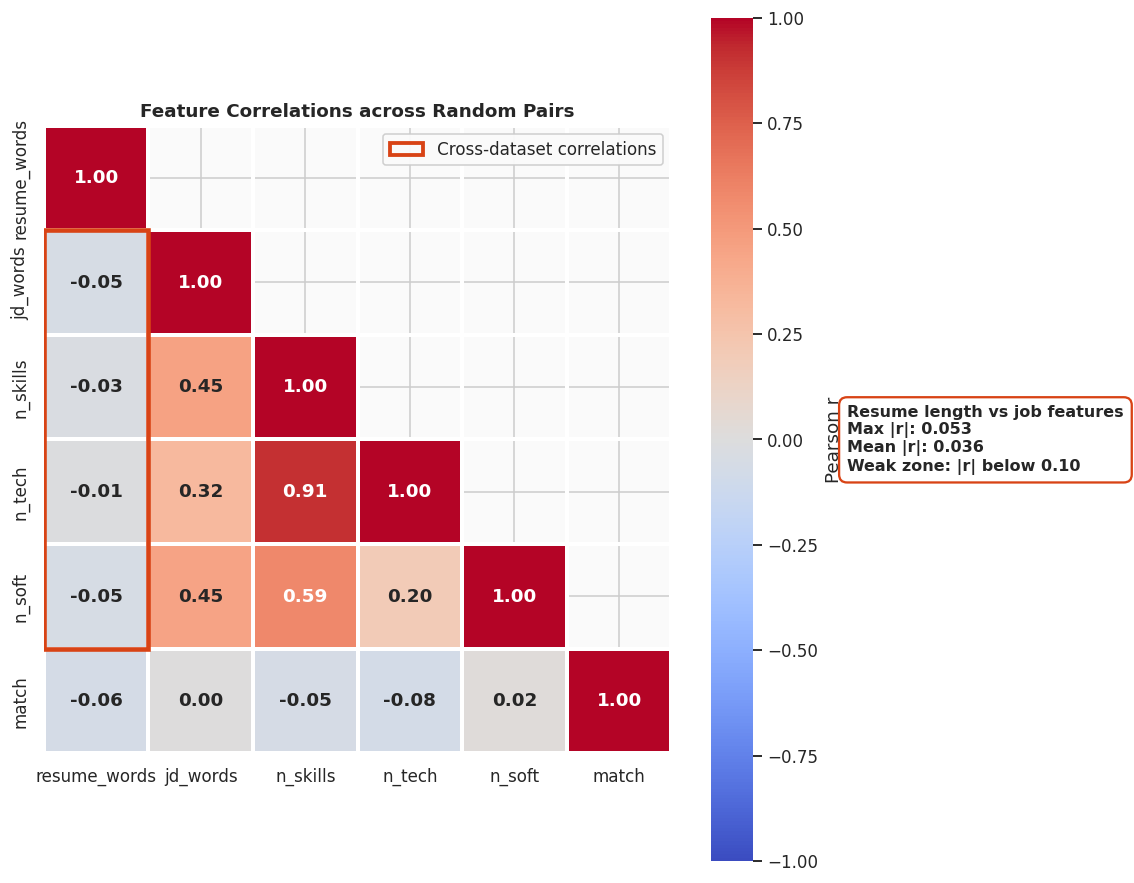

jd_words   -0.052
n_skills   -0.030
n_tech     -0.010
n_soft     -0.053
Name: resume_words, dtype: float64


In [22]:
from matplotlib.patches import Rectangle

corr_cols = ['resume_words', 'jd_words', 'n_skills', 'n_tech', 'n_soft', 'match']
corr = sample_pairs[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
cross = corr.loc[['jd_words', 'n_skills', 'n_tech', 'n_soft'], 'resume_words']

fig, ax = plt.subplots(figsize=(10.5, 8.5))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=1.5,
            linecolor='white', square=True, cbar_kws={'label': 'Pearson r'},
            annot_kws={'fontsize': 12, 'fontweight': 'bold'}, ax=ax)
ax.add_patch(Rectangle((0, 1), 1, 4, fill=False, edgecolor='#d84315', linewidth=3))
ax.set_title('Feature Correlations across Random Pairs')
kpi = (f'Resume length vs job features\nMax |r|: {cross.abs().max():.3f}\nMean |r|: {cross.abs().mean():.3f}\n'
       f'Weak zone: |r| below 0.10')
ax.text(1.28, 0.5, kpi, transform=ax.transAxes, ha='left', va='center', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#d84315', linewidth=1.5))
ax.legend(handles=[Patch(fill=False, edgecolor='#d84315', linewidth=2.5, label='Cross-dataset correlations')],
          loc='upper right', framealpha=0.95)
plt.tight_layout()
plt.show()
print(cross.round(3))

In [23]:
def strip_boiler(t):
    return ' '.join(w for w in t.split() if w not in BOILERPLATE)

def strip_boiler_phrases(t):
    t = re.sub(r'\bcompany name\b|\bcity state\b', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

resumes['resume_model'] = resumes['resume_nostop'].apply(strip_boiler)
resumes['resume_embed'] = resumes['resume_clean'].apply(strip_boiler_phrases)
resumes['model_words'] = resumes['resume_model'].str.split().str.len()

removed_pct = (1 - resumes['resume_embed'].str.split().str.len().sum() / resumes['resume_words'].sum()) * 100
print('words removed from embedding text (%):', round(removed_pct, 2))
print('average words for TF-IDF text:', round(resumes['model_words'].mean(), 1))

eda_summary = {
    'resumes_final': int(len(resumes)),
    'jobs_final': int(len(jobs)),
    'resume_categories': int(resumes[RESUME_CAT].nunique()),
    'imbalance_ratio': round(float(cat_counts_all.max() / cat_counts_all.min()), 2),
    'resumes_with_job_counterpart_pct': round(float(resumes[RESUME_CAT].isin(JOB_MATCHABLE).mean() * 100), 2),
    'resume_words_mean': round(float(resumes['resume_words'].mean()), 1),
    'resume_words_median': float(resumes['resume_words'].median()),
    'jd_words_mean': round(float(jobs['jd_words'].mean()), 1),
    'skills_per_job_mean': round(float(jobs['n_skills'].mean()), 2),
    'soft_skill_share_pct': round(float(soft_share), 2),
    'vocabulary_size': int(len(skills_vocab)),
    'vocabulary_mention_coverage_pct': round(float(vocab_mention_cov), 2),
    'pair_length_skill_pearson': round(float(pr), 3),
    'random_pair_match_rate_pct': round(float(sample_pairs['match'].mean() * 100), 2),
    'expected_match_rate_pct': round(float(expected_match * 100), 2),
    'parsing_success': parsing_success
}
print(json.dumps(eda_summary, indent=2))

words removed from embedding text (%): 2.54
average words for TF-IDF text: 596.9
{
  "resumes_final": 2481,
  "jobs_final": 1167,
  "resume_categories": 24,
  "imbalance_ratio": 5.45,
  "resumes_with_job_counterpart_pct": 23.46,
  "resume_words_mean": 814.4,
  "resume_words_median": 759.0,
  "jd_words_mean": 530.0,
  "skills_per_job_mean": 17.78,
  "soft_skill_share_pct": 34.86,
  "vocabulary_size": 874,
  "vocabulary_mention_coverage_pct": 78.02,
  "pair_length_skill_pearson": -0.03,
  "random_pair_match_rate_pct": 4.8,
  "expected_match_rate_pct": 4.7,
  "parsing_success": {
    "resume_parsing_success_pct": 99.96,
    "job_description_parsing_success_pct": 100.0
  }
}


# **Model 1, Resume Category Classifier**

In [24]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix)

le = LabelEncoder()
y_all = le.fit_transform(resumes[RESUME_CAT])
X_all = resumes['resume_model']

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)

TFIDF_PARAMS = dict(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True, max_features=60000)
tfidf_check = TfidfVectorizer(**TFIDF_PARAMS).fit(X_train)

dist = pd.DataFrame({
    'train_pct': pd.Series(le.inverse_transform(y_train)).value_counts(normalize=True) * 100,
    'test_pct': pd.Series(le.inverse_transform(y_test)).value_counts(normalize=True) * 100
}).round(2)
dist['gap'] = (dist['train_pct'] - dist['test_pct']).abs().round(2)

print('train:', len(X_train), '| test:', len(X_test))
print('TF-IDF vocabulary size (train only):', len(tfidf_check.vocabulary_))
print('largest train/test share gap (pct points):', dist['gap'].max())
display(dist.sort_values('gap', ascending=False).head(5))

train: 1984 | test: 497
TF-IDF vocabulary size (train only): 60000
largest train/test share gap (pct points): 0.14


,train_pct,test_pct,gap
FINANCE,4.69,4.83,0.14
FITNESS,4.69,4.83,0.14
APPAREL,3.93,3.82,0.11
BPO,0.91,0.80,0.11
CONSTRUCTION,4.54,4.43,0.11


,accuracy,accuracy_sd,f1_macro,f1_sd,fit_sec
model,,,,,
Logistic Regression,0.6477,0.0241,0.5868,0.0224,23.1862
Linear SVM,0.6623,0.0199,0.6066,0.0243,6.6544
Complement NB,0.5771,0.0187,0.5004,0.0229,5.1671


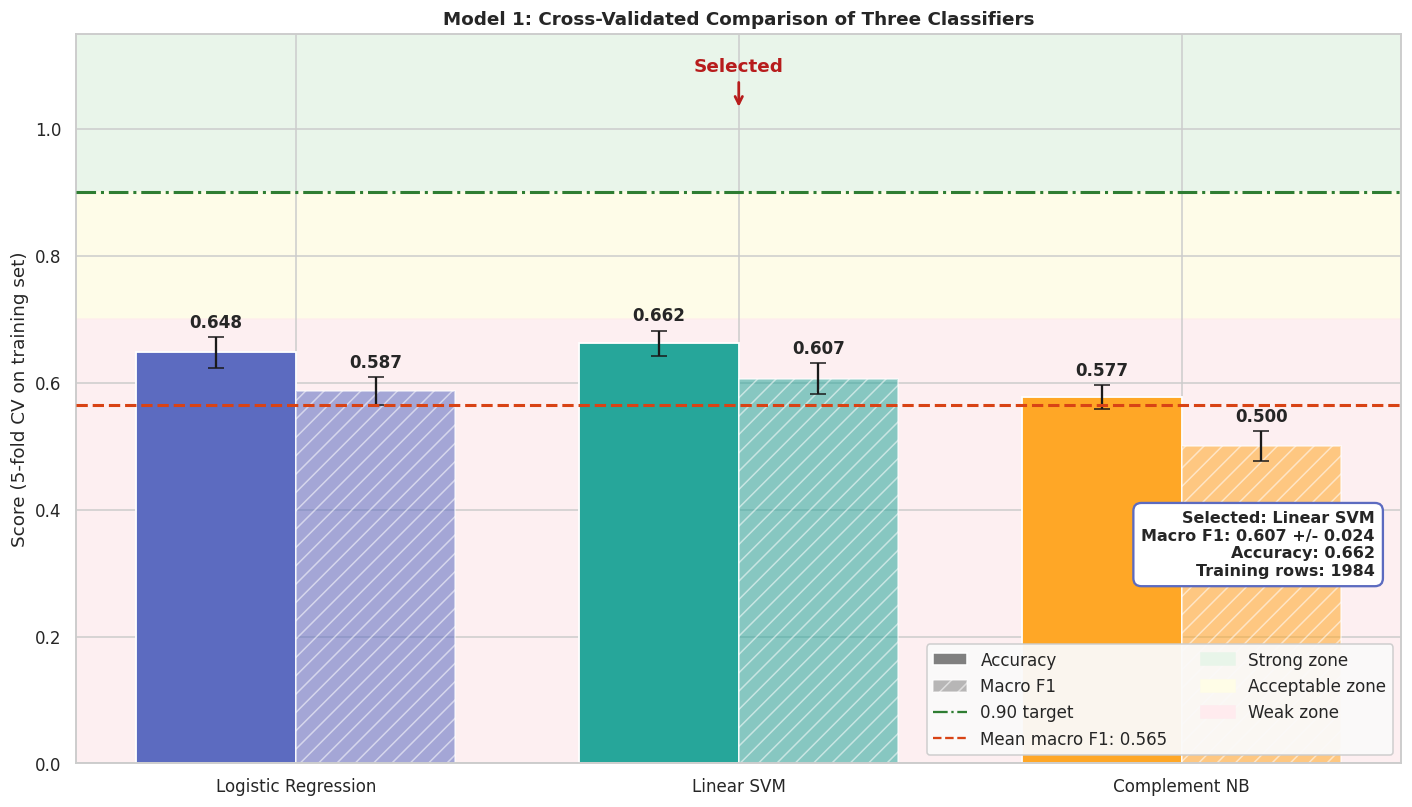

In [25]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
candidates = {
    'Logistic Regression': LogisticRegression(C=10, class_weight='balanced', max_iter=2000),
    'Linear SVM': LinearSVC(C=0.5, class_weight='balanced'),
    'Complement NB': ComplementNB(alpha=0.3)
}

rows = []
for name, clf in candidates.items():
    pipe = Pipeline([('tfidf', TfidfVectorizer(**TFIDF_PARAMS)), ('clf', clone(clf))])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['accuracy', 'f1_macro'], n_jobs=-1)
    rows.append({'model': name,
                 'accuracy': res['test_accuracy'].mean(), 'accuracy_sd': res['test_accuracy'].std(),
                 'f1_macro': res['test_f1_macro'].mean(), 'f1_sd': res['test_f1_macro'].std(),
                 'fit_sec': res['fit_time'].mean()})
cv_df = pd.DataFrame(rows).set_index('model')
BEST_NAME = cv_df['f1_macro'].idxmax()
display(cv_df.round(4))

x = np.arange(len(cv_df))
bw = 0.36
mcol = ['#5c6bc0', '#26a69a', '#ffa726']

fig, ax = plt.subplots(figsize=(13, 7.5))
ax.axhspan(0.9, 1.15, color='#e8f5e9', alpha=0.9, zorder=0)
ax.axhspan(0.7, 0.9, color='#fffde7', alpha=0.9, zorder=0)
ax.axhspan(0, 0.7, color='#ffebee', alpha=0.7, zorder=0)
b1 = ax.bar(x - bw / 2, cv_df['accuracy'], bw, yerr=cv_df['accuracy_sd'], capsize=5, color=mcol,
            edgecolor='white', linewidth=1.2, zorder=2)
b2 = ax.bar(x + bw / 2, cv_df['f1_macro'], bw, yerr=cv_df['f1_sd'], capsize=5, color=mcol, alpha=0.55,
            hatch='//', edgecolor='white', linewidth=1.2, zorder=2)
ax.axhline(0.9, color='#2e7d32', linestyle='-.', linewidth=2, zorder=3)
ax.axhline(cv_df['f1_macro'].mean(), color='#d84315', linestyle='--', linewidth=2, zorder=3)
for bars, col, sd in ((b1, 'accuracy', 'accuracy_sd'), (b2, 'f1_macro', 'f1_sd')):
    for b, (_, r) in zip(bars, cv_df.iterrows()):
        ax.text(b.get_x() + b.get_width() / 2, r[col] + r[sd] + 0.015, f'{r[col]:.3f}', ha='center',
                fontsize=11, fontweight='bold')
bi = list(cv_df.index).index(BEST_NAME)
ax.annotate('Selected', xy=(bi, 1.03), xytext=(bi, 1.09), ha='center', fontweight='bold', color='#b71c1c',
            arrowprops=dict(arrowstyle='->', color='#b71c1c', linewidth=1.8))
ax.set_xticks(x)
ax.set_xticklabels(cv_df.index)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score (5-fold CV on training set)')
ax.set_title('Model 1: Cross-Validated Comparison of Three Classifiers')
kpi = (f'Selected: {BEST_NAME}\nMacro F1: {cv_df.loc[BEST_NAME, "f1_macro"]:.3f} +/- {cv_df.loc[BEST_NAME, "f1_sd"]:.3f}\n'
       f'Accuracy: {cv_df.loc[BEST_NAME, "accuracy"]:.3f}\nTraining rows: {len(X_train)}')
ax.text(0.98, 0.3, kpi, transform=ax.transAxes, ha='right', va='center', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
handles = [Patch(facecolor='grey', label='Accuracy'), Patch(facecolor='grey', alpha=0.55, hatch='//', label='Macro F1'),
           plt.Line2D([0], [0], color='#2e7d32', linestyle='-.', label='0.90 target'),
           plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Mean macro F1: {cv_df["f1_macro"].mean():.3f}'),
           Patch(color='#e8f5e9', label='Strong zone'), Patch(color='#fffde7', label='Acceptable zone'),
           Patch(color='#ffebee', label='Weak zone')]
ax.legend(handles=handles, loc='lower right', ncol=2, framealpha=0.95)
plt.tight_layout()
plt.show()

In [26]:
final_pipe = Pipeline([('tfidf', TfidfVectorizer(**TFIDF_PARAMS)), ('clf', clone(candidates[BEST_NAME]))])
final_pipe.fit(X_train, y_train)
y_pred = final_pipe.predict(X_test)

acc = accuracy_score(y_test, y_pred)
p_m, r_m, f_m, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
f_w = f1_score(y_test, y_pred, average='weighted')

model1_metrics = {
    'model': BEST_NAME,
    'test_accuracy': round(float(acc), 4),
    'macro_precision': round(float(p_m), 4),
    'macro_recall': round(float(r_m), 4),
    'macro_f1': round(float(f_m), 4),
    'weighted_f1': round(float(f_w), 4),
    'cv_macro_f1': round(float(cv_df.loc[BEST_NAME, 'f1_macro']), 4),
    'n_train': int(len(X_train)),
    'n_test': int(len(X_test))
}

report = pd.DataFrame(classification_report(y_test, y_pred, target_names=le.classes_,
                                            output_dict=True, zero_division=0)).T
display(report.round(3))
print(json.dumps(model1_metrics, indent=2))

,precision,recall,f1-score,support
ACCOUNTANT,0.568,0.875,0.689,24.000
ADVOCATE,0.538,0.583,0.560,24.000
AGRICULTURE,0.889,0.615,0.727,13.000
APPAREL,0.444,0.211,0.286,19.000
ARTS,0.727,0.381,0.500,21.000
AUTOMOBILE,1.000,0.429,0.600,7.000
AVIATION,0.864,0.826,0.844,23.000
BANKING,0.842,0.696,0.762,23.000
BPO,0.000,0.000,0.000,4.000
BUSINESS-DEVELOPMENT,0.556,0.833,0.667,24.000


{
  "model": "Linear SVM",
  "test_accuracy": 0.6781,
  "macro_precision": 0.6779,
  "macro_recall": 0.6436,
  "macro_f1": 0.6325,
  "weighted_f1": 0.6579,
  "cv_macro_f1": 0.6066,
  "n_train": 1984,
  "n_test": 497
}


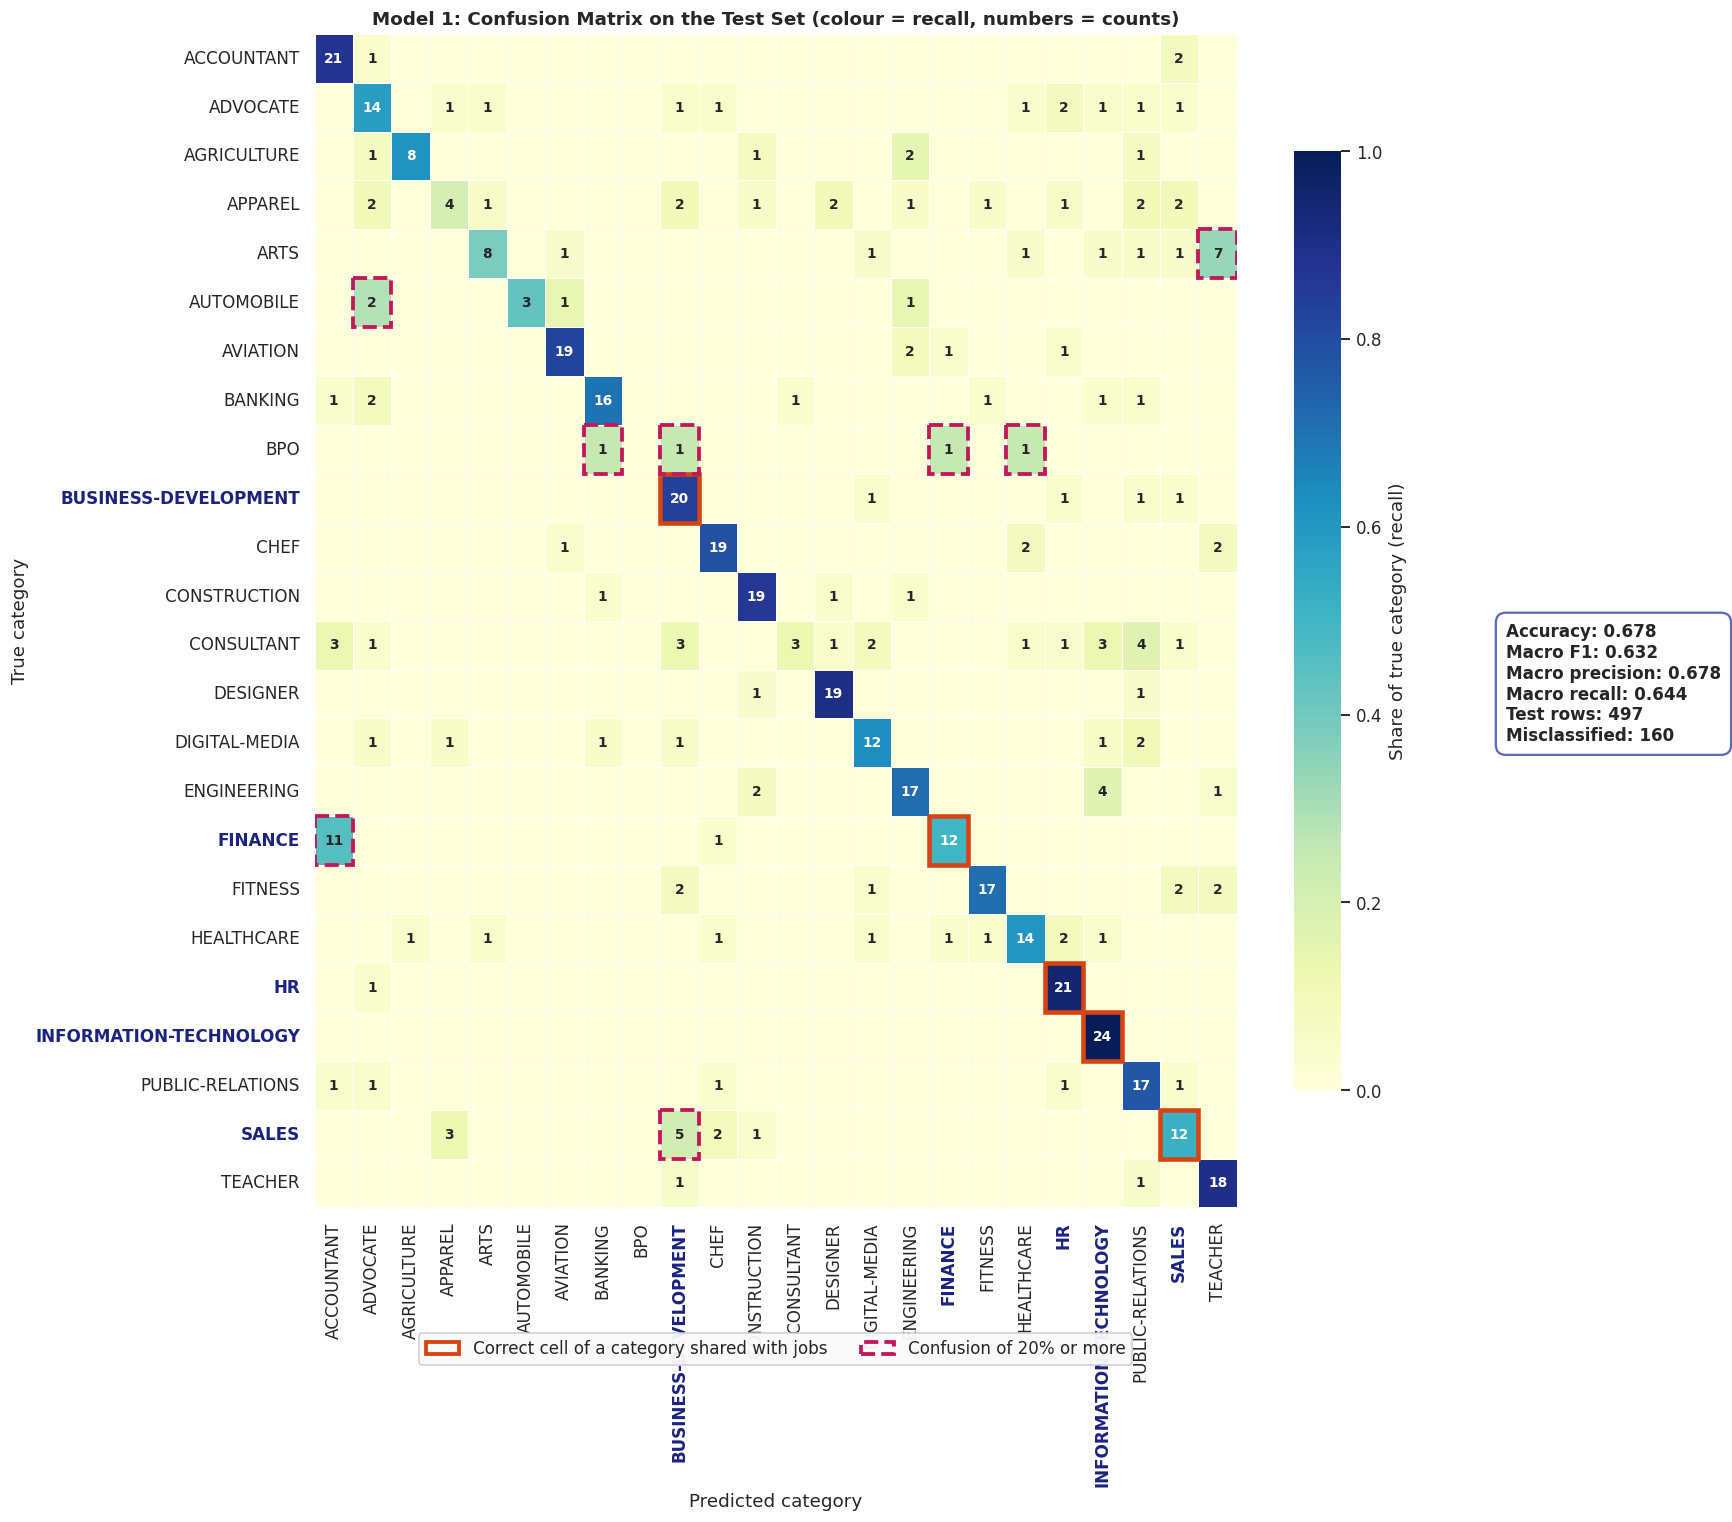

[('FINANCE', 'ACCOUNTANT', 11), ('ARTS', 'TEACHER', 7), ('SALES', 'BUSINESS-DEVELOPMENT', 5), ('CONSULTANT', 'PUBLIC-RELATIONS', 4), ('ENGINEERING', 'INFORMATION-TECHNOLOGY', 4), ('CONSULTANT', 'ACCOUNTANT', 3), ('CONSULTANT', 'BUSINESS-DEVELOPMENT', 3), ('CONSULTANT', 'INFORMATION-TECHNOLOGY', 3)]


In [27]:
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
names = le.classes_
annot = np.where(cm > 0, cm.astype(str), '')

fig, ax = plt.subplots(figsize=(17, 14))
sns.heatmap(cm_norm, annot=annot, fmt='', cmap='YlGnBu', vmin=0, vmax=1, xticklabels=names, yticklabels=names,
            linewidths=0.6, linecolor='white', cbar_kws={'label': 'Share of true category (recall)', 'shrink': 0.8},
            annot_kws={'fontsize': 9, 'fontweight': 'bold'}, ax=ax)
for i, c in enumerate(names):
    if c in JOB_MATCHABLE:
        ax.add_patch(Rectangle((i, i), 1, 1, fill=False, edgecolor='#d84315', linewidth=3))
for i in range(len(names)):
    for j in range(len(names)):
        if i != j and cm_norm[i, j] >= 0.2:
            ax.add_patch(Rectangle((j, i), 1, 1, fill=False, edgecolor='#c2185b', linewidth=2.5, linestyle='--'))
for lbl in list(ax.get_xticklabels()) + list(ax.get_yticklabels()):
    if lbl.get_text() in JOB_MATCHABLE:
        lbl.set_fontweight('bold')
        lbl.set_color('#1a237e')
ax.set_xlabel('Predicted category')
ax.set_ylabel('True category')
ax.set_title('Model 1: Confusion Matrix on the Test Set (colour = recall, numbers = counts)')
handles = [Patch(fill=False, edgecolor='#d84315', linewidth=2.5, label='Correct cell of a category shared with jobs'),
           Patch(fill=False, edgecolor='#c2185b', linewidth=2.5, linestyle='--', label='Confusion of 20% or more')]
ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2, framealpha=0.95)
plt.tight_layout(rect=[0, 0, 0.8, 1])
kpi = (f'Accuracy: {acc:.3f}\nMacro F1: {f_m:.3f}\nMacro precision: {p_m:.3f}\nMacro recall: {r_m:.3f}\n'
       f'Test rows: {len(y_test)}\nMisclassified: {int((y_test != y_pred).sum())}')
fig.text(0.81, 0.55, kpi, fontsize=11, fontweight='bold', va='center',
         bbox=dict(boxstyle='round,pad=0.6', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
plt.show()

pairs = [(names[i], names[j], int(cm[i, j])) for i in range(len(names)) for j in range(len(names)) if i != j and cm[i, j] > 0]
print(sorted(pairs, key=lambda t: -t[2])[:8])

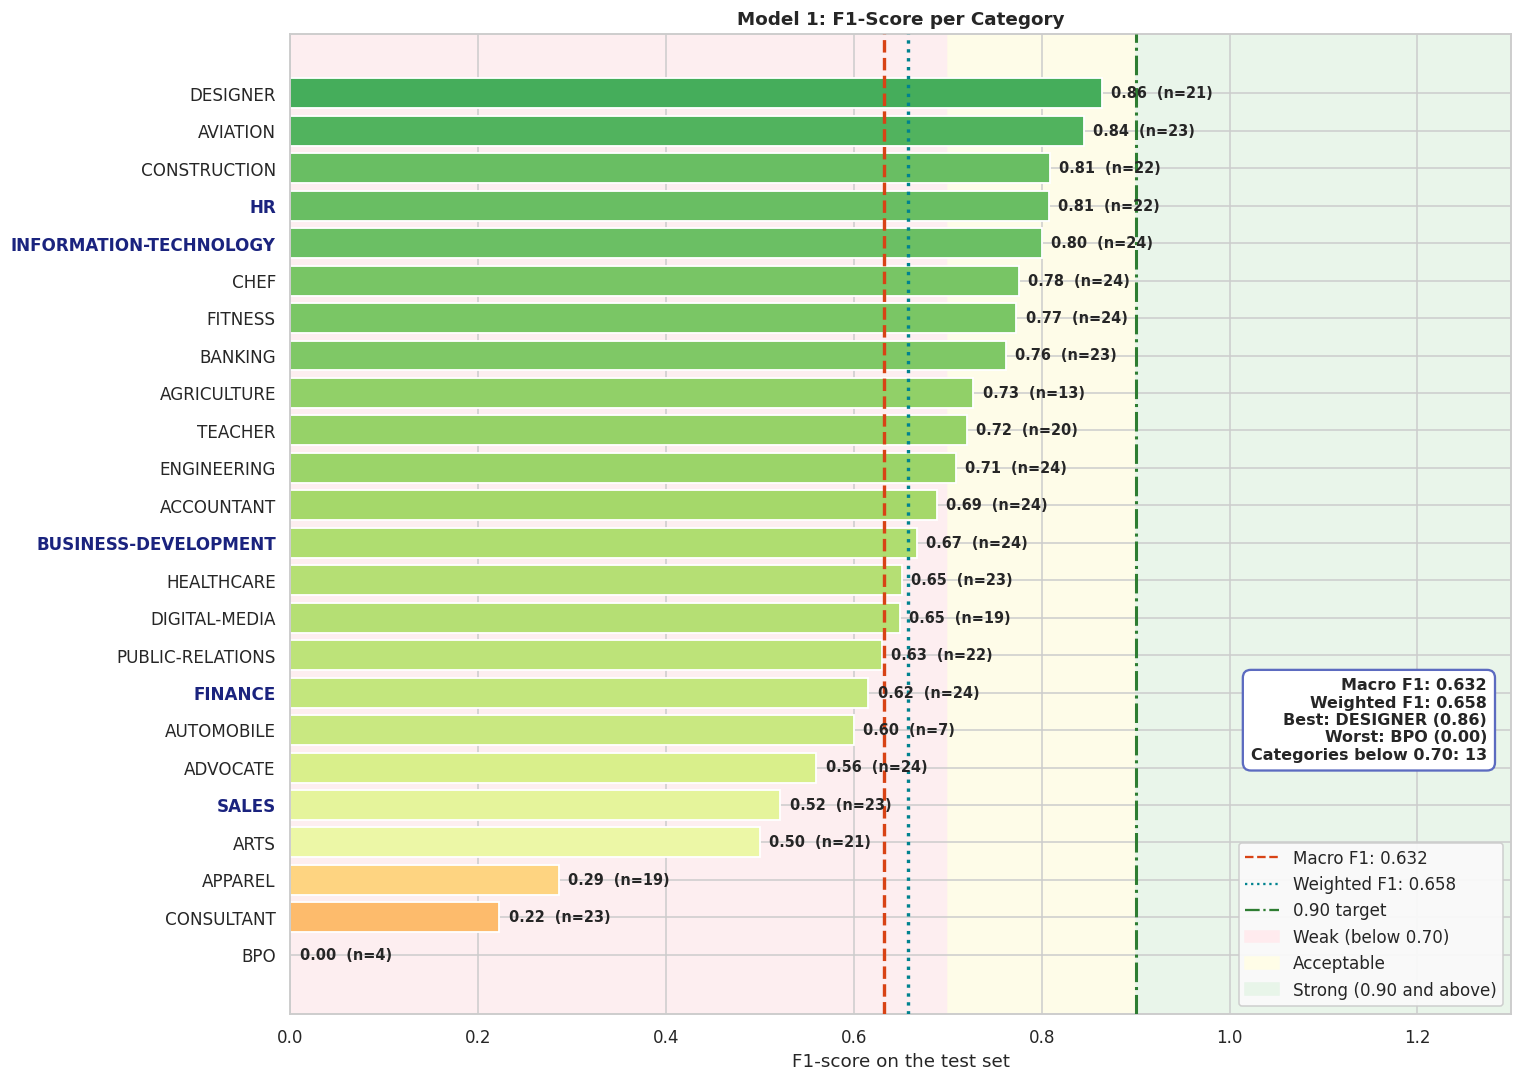

In [28]:
prf = precision_recall_fscore_support(y_test, y_pred, zero_division=0)
cat_df = pd.DataFrame({'precision': prf[0], 'recall': prf[1], 'f1': prf[2], 'support': prf[3]},
                      index=le.classes_).sort_values('f1')
n_low = int((cat_df['f1'] < 0.7).sum())

fig, ax = plt.subplots(figsize=(14, 10))
ax.axvspan(0, 0.7, color='#ffebee', alpha=0.8, zorder=0)
ax.axvspan(0.7, 0.9, color='#fffde7', alpha=0.9, zorder=0)
ax.axvspan(0.9, 1.3, color='#e8f5e9', alpha=0.9, zorder=0)
bars = ax.barh(cat_df.index, cat_df['f1'], color=plt.cm.RdYlGn(0.15 + 0.8 * cat_df['f1'].values),
               edgecolor='white', linewidth=1.2, zorder=2)
ax.axvline(f_m, color='#d84315', linestyle='--', linewidth=2.2, zorder=3)
ax.axvline(f_w, color='#00838f', linestyle=':', linewidth=2.2, zorder=3)
ax.axvline(0.9, color='#2e7d32', linestyle='-.', linewidth=2, zorder=3)
for b, (c, r) in zip(bars, cat_df.iterrows()):
    ax.text(r['f1'] + 0.01, b.get_y() + b.get_height() / 2, f"{r['f1']:.2f}  (n={int(r['support'])})",
            va='center', fontsize=9.5, fontweight='bold')
for lbl in ax.get_yticklabels():
    if lbl.get_text() in JOB_MATCHABLE:
        lbl.set_fontweight('bold')
        lbl.set_color('#1a237e')
ax.set_xlim(0, 1.3)
ax.set_xlabel('F1-score on the test set')
ax.set_title('Model 1: F1-Score per Category')
kpi = (f'Macro F1: {f_m:.3f}\nWeighted F1: {f_w:.3f}\nBest: {cat_df["f1"].idxmax()} ({cat_df["f1"].max():.2f})\n'
       f'Worst: {cat_df["f1"].idxmin()} ({cat_df["f1"].min():.2f})\nCategories below 0.70: {n_low}')
ax.text(0.98, 0.3, kpi, transform=ax.transAxes, ha='right', va='center', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
handles = [plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Macro F1: {f_m:.3f}'),
           plt.Line2D([0], [0], color='#00838f', linestyle=':', label=f'Weighted F1: {f_w:.3f}'),
           plt.Line2D([0], [0], color='#2e7d32', linestyle='-.', label='0.90 target'),
           Patch(color='#ffebee', label='Weak (below 0.70)'), Patch(color='#fffde7', label='Acceptable'),
           Patch(color='#e8f5e9', label='Strong (0.90 and above)')]
ax.legend(handles=handles, loc='lower right', framealpha=0.95)
plt.tight_layout()
plt.show()

{'accuracy_full': 0.6781, 'accuracy_no_head': 0.6298, 'macro_f1_full': 0.6325, 'macro_f1_no_head': 0.5764}


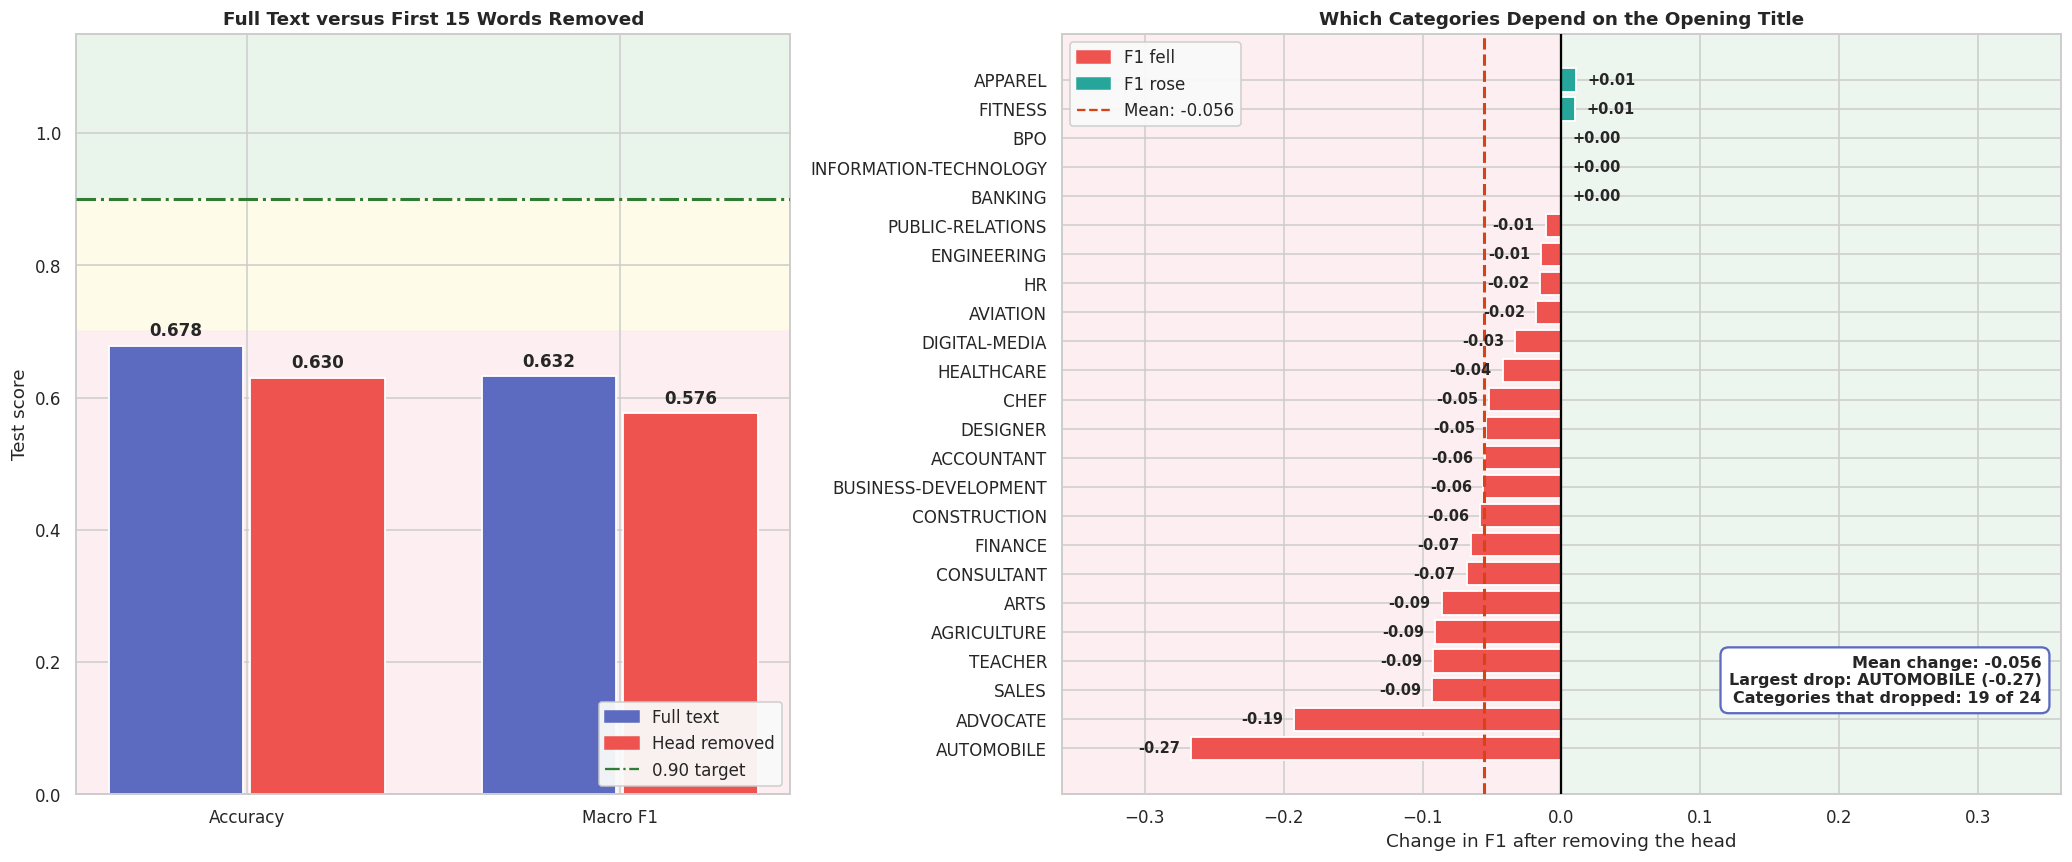

In [29]:
def drop_head(t, n=15):
    return ' '.join(t.split()[n:])

X_train_nh = X_train.apply(drop_head)
X_test_nh = X_test.apply(drop_head)
abl_pipe = Pipeline([('tfidf', TfidfVectorizer(**TFIDF_PARAMS)), ('clf', clone(candidates[BEST_NAME]))])
abl_pipe.fit(X_train_nh, y_train)
y_pred_nh = abl_pipe.predict(X_test_nh)

acc_nh = accuracy_score(y_test, y_pred_nh)
f_nh = f1_score(y_test, y_pred_nh, average='macro')
f1_full = f1_score(y_test, y_pred, average=None)
f1_nh = f1_score(y_test, y_pred_nh, average=None)
delta = pd.Series(f1_nh - f1_full, index=le.classes_).sort_values()

model1_ablation = {'accuracy_full': round(float(acc), 4), 'accuracy_no_head': round(float(acc_nh), 4),
                   'macro_f1_full': round(float(f_m), 4), 'macro_f1_no_head': round(float(f_nh), 4)}
print(model1_ablation)

fig, axes = plt.subplots(1, 2, figsize=(19, 8), gridspec_kw={'width_ratios': [1, 1.4]})
ax = axes[0]
vals = np.array([[acc, acc_nh], [f_m, f_nh]])
xx = np.arange(2)
ax.axhspan(0.9, 1.15, color='#e8f5e9', alpha=0.9, zorder=0)
ax.axhspan(0.7, 0.9, color='#fffde7', alpha=0.9, zorder=0)
ax.axhspan(0, 0.7, color='#ffebee', alpha=0.7, zorder=0)
ba = ax.bar(xx - 0.19, vals[:, 0], 0.36, color='#5c6bc0', edgecolor='white', linewidth=1.2, zorder=2)
bb = ax.bar(xx + 0.19, vals[:, 1], 0.36, color='#ef5350', edgecolor='white', linewidth=1.2, zorder=2)
for bars in (ba, bb):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.015, f'{b.get_height():.3f}', ha='center',
                fontsize=11, fontweight='bold')
ax.axhline(0.9, color='#2e7d32', linestyle='-.', linewidth=2, zorder=3)
ax.set_xticks(xx)
ax.set_xticklabels(['Accuracy', 'Macro F1'])
ax.set_ylim(0, 1.15)
ax.set_ylabel('Test score')
ax.set_title('Full Text versus First 15 Words Removed')
ax.legend(handles=[Patch(color='#5c6bc0', label='Full text'), Patch(color='#ef5350', label='Head removed'),
                   plt.Line2D([0], [0], color='#2e7d32', linestyle='-.', label='0.90 target')],
          loc='lower right', framealpha=0.95)

ax2 = axes[1]
ax2.axvspan(-1, 0, color='#ffebee', alpha=0.7, zorder=0)
ax2.axvspan(0, 1, color='#e8f5e9', alpha=0.7, zorder=0)
bars = ax2.barh(delta.index, delta.values, color=np.where(delta.values < 0, '#ef5350', '#26a69a'),
                edgecolor='white', linewidth=1.2, zorder=2)
ax2.axvline(0, color='black', linewidth=1.5, zorder=3)
ax2.axvline(delta.mean(), color='#d84315', linestyle='--', linewidth=2, zorder=3)
for b, v in zip(bars, delta.values):
    ax2.text(v + (0.008 if v >= 0 else -0.008), b.get_y() + b.get_height() / 2, f'{v:+.2f}', va='center',
             ha='left' if v >= 0 else 'right', fontsize=9.5, fontweight='bold')
lim = max(0.15, delta.abs().max() * 1.35)
ax2.set_xlim(-lim, lim)
ax2.set_xlabel('Change in F1 after removing the head')
ax2.set_title('Which Categories Depend on the Opening Title')
kpi = (f'Mean change: {delta.mean():+.3f}\nLargest drop: {delta.idxmin()} ({delta.min():+.2f})\n'
       f'Categories that dropped: {int((delta < 0).sum())} of {len(delta)}')
ax2.text(0.98, 0.15, kpi, transform=ax2.transAxes, ha='right', va='center', fontsize=10.5, fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
ax2.legend(handles=[Patch(color='#ef5350', label='F1 fell'), Patch(color='#26a69a', label='F1 rose'),
                    plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Mean: {delta.mean():+.3f}')],
           loc='upper left', framealpha=0.95)
plt.tight_layout()
plt.show()

# **Model 2, Compatibility Score**

In [30]:
dec = final_pipe.decision_function(X_test)
top3 = np.argsort(dec, axis=1)[:, -3:]
top3_acc = float(np.mean([y_test[i] in top3[i] for i in range(len(y_test))]))
model1_metrics['top3_accuracy'] = round(top3_acc, 4)
print('top-1 accuracy:', round(float(acc), 4), '| top-3 accuracy:', round(top3_acc, 4))

BASE_COLS = ['resume_idx', 'job_idx', 'pair_type', 'resume_cat', 'job_cat', 'match']
rng = np.random.default_rng(SEED)
res_by_cat = {c: np.where(resumes[RESUME_CAT].values == c)[0] for c in resumes[RESUME_CAT].unique()}
job_by_cat = {c: np.where(jobs[JOB_CAT].values == c)[0] for c in JOB_MATCHABLE}
unrelated = np.where(~resumes[RESUME_CAT].isin(JOB_MATCHABLE).values)[0]

PER_CAT = 60
rows = []
for c in JOB_MATCHABLE:
    r_same = rng.choice(res_by_cat[c], PER_CAT, replace=False)
    j_same = rng.choice(job_by_cat[c], PER_CAT, replace=False)
    rows += [(int(r), int(j), 'same') for r, j in zip(r_same, j_same)]
    others = [k for k in JOB_MATCHABLE if k != c]
    for r in rng.choice(res_by_cat[c], PER_CAT // 2, replace=False):
        oc = others[int(rng.integers(len(others)))]
        rows.append((int(r), int(rng.choice(job_by_cat[oc])), 'hard_neg'))
for r in rng.choice(unrelated, 150, replace=False):
    rows.append((int(r), int(rng.integers(len(jobs))), 'easy_neg'))

pairs = pd.DataFrame(rows, columns=['resume_idx', 'job_idx', 'pair_type'])
pairs['resume_cat'] = resumes[RESUME_CAT].values[pairs['resume_idx']]
pairs['job_cat'] = jobs[JOB_CAT].values[pairs['job_idx']]
pairs['match'] = (pairs['resume_cat'] == pairs['job_cat']).astype(int)
pairs = pairs.sample(frac=1, random_state=SEED).reset_index(drop=True)

print('pairs:', len(pairs), '| matches:', int(pairs['match'].sum()))
print('unique resumes:', pairs['resume_idx'].nunique(), '| unique jobs:', pairs['job_idx'].nunique())
display(pd.crosstab(pairs['pair_type'], pairs['job_cat']))

top-1 accuracy: 0.6781 | top-3 accuracy: 0.9195
pairs: 600 | matches: 300
unique resumes: 529 | unique jobs: 500


job_cat,BUSINESS-DEVELOPMENT,FINANCE,HR,INFORMATION-TECHNOLOGY,SALES
pair_type,,,,,
easy_neg,36,34,22,34,24
hard_neg,29,33,24,31,33
same,60,60,60,60,60


In [31]:
!pip install -q sentence-transformers
import time
import torch
from sentence_transformers import SentenceTransformer

EMBED_MODEL = 'sentence-transformers/all-MiniLM-L6-v2'
CHUNK_WORDS = 150
embedder = SentenceTransformer(EMBED_MODEL, device='cuda' if torch.cuda.is_available() else 'cpu')

def chunk_text(t, size=CHUNK_WORDS):
    w = t.split()
    return [' '.join(w[i:i + size]) for i in range(0, max(len(w), 1), size)]

def embed_docs(texts, batch_size=64):
    chunks, owner = [], []
    for k, t in enumerate(texts):
        cs = chunk_text(t)
        chunks += cs
        owner += [k] * len(cs)
    emb = embedder.encode(chunks, batch_size=batch_size, normalize_embeddings=True, show_progress_bar=False)
    owner = np.array(owner)
    out = np.zeros((len(texts), emb.shape[1]), dtype=np.float32)
    np.add.at(out, owner, emb)
    out = out / np.clip(np.linalg.norm(out, axis=1, keepdims=True), 1e-9, None)
    return out, np.bincount(owner, minlength=len(texts))

t0 = time.time()
uniq_r = np.sort(pairs['resume_idx'].unique())
r_pos = {int(r): i for i, r in enumerate(uniq_r)}
R_emb, R_nch = embed_docs(resumes['resume_embed'].values[uniq_r].tolist())
J_emb, J_nch = embed_docs(jobs['jd_clean'].tolist())

print('device:', embedder.device, '| max sequence length:', embedder.max_seq_length, '| dimension:', R_emb.shape[1])
print('resumes embedded:', R_emb.shape[0], '| jobs embedded:', J_emb.shape[0])
print('avg chunks per resume:', round(R_nch.mean(), 2), '| per job:', round(J_nch.mean(), 2))
print('seconds:', round(time.time() - t0, 1))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

device: cuda:0 | max sequence length: 256 | dimension: 384
resumes embedded: 529 | jobs embedded: 1167
avg chunks per resume: 5.76 | per job: 4.03
seconds: 15.7


In [32]:
ALIASES = {k: v for k, v in SYNONYMS.items() if len(k) >= 3 and v in vocab_set}
term_map = {}
for s in skills_vocab:
    term_map.setdefault(clean_text(s), s)
for a, canon in ALIASES.items():
    term_map.setdefault(clean_text(a), canon)
term_map.pop('', None)
MAX_N = max(len(t.split()) for t in term_map)

def extract_skills(clean):
    tok = clean.split()
    found, i, n_tok = set(), 0, len(tok)
    while i < n_tok:
        step = 1
        for n in range(min(MAX_N, n_tok - i), 0, -1):
            g = ' '.join(tok[i:i + n])
            if g in term_map:
                found.add(term_map[g])
                step = n
                break
        i += step
    return sorted(found)

t0 = time.time()
jobs['ext_skills'] = jobs['jd_clean'].apply(extract_skills)
jobs['n_ext'] = jobs['ext_skills'].str.len()
jobs['n_ext_tech'] = jobs['ext_skills'].apply(lambda l: sum(s not in SOFT_SKILLS for s in l))

print('terms:', len(term_map), '| max n-gram length:', MAX_N, '| aliases used:', len(ALIASES))
print('short terms (3 characters or fewer):', sorted(t for t in term_map if len(t) <= 3))
print('extraction seconds:', round(time.time() - t0, 1))
print('avg extracted per job:', round(jobs['n_ext'].mean(), 2), '| avg listed per job:', round(jobs['n_skills'].mean(), 2))
print('jobs with no technical skill extracted (%):', round((jobs['n_ext_tech'] == 0).mean() * 100, 2))
display(jobs[['n_ext', 'n_ext_tech']].describe().round(2))
ex = jobs.iloc[0]
print(ex[JOB_TITLE])
print('listed:', ex['skills_list'][:10])
print('extracted:', ex['ext_skills'][:10])

terms: 872 | max n-gram length: 7 | aliases used: 4
short terms (3 characters or fewer): ['ada', 'ats', 'aws', 'c#', 'cpa', 'crm', 'css', 'dns', 'etl', 'ios', 'kwi', 'mba', 'rpa', 'sap', 'sql', 'vba', 'vpn']
extraction seconds: 1.9
avg extracted per job: 18.11 | avg listed per job: 17.78
jobs with no technical skill extracted (%): 0.17


,n_ext,n_ext_tech
count,1167.00,1167.00
mean,18.11,14.70
std,9.40,7.74
min,0.00,0.00
25%,11.00,9.00
50%,17.00,13.00
75%,24.00,19.50
max,52.00,44.00


Sr Human Resource Generalist
listed: ['employee relations', 'talent acquisition', 'performance management', 'compensation and benefits', 'employment laws and regulations', 'analytical skills', 'employee benefits administration', 'hr policies and procedures', 'recruitment strategies', 'fmla']
extracted: ['ada', 'analytical skills', 'communication', 'compensation and benefits', 'compliance', 'decision making', 'discretion', 'drive', 'employee benefits administration', 'employee development']


In [33]:
res_skills = {int(r): set(extract_skills(resumes['resume_clean'].iat[int(r)])) for r in uniq_r}

def ratio(a, b):
    return len(a) / len(b) if b else np.nan

recs = []
for r, j in zip(pairs['resume_idx'], pairs['job_idx']):
    js = set(jobs['ext_skills'].iat[j])
    rs = res_skills[int(r)]
    jt = {s for s in js if s not in SOFT_SKILLS}
    jsf = js - jt
    gs = set(jobs['skills_list'].iat[j])
    recs.append({
        'sim': float(R_emb[r_pos[int(r)]] @ J_emb[j]),
        'cov_all': ratio(js & rs, js),
        'cov_tech': ratio(jt & rs, jt),
        'cov_soft': ratio(jsf & rs, jsf),
        'cov_gt': ratio(gs & rs, gs),
        'gap_all': len(js - rs),
        'gap_tech': len(jt - rs),
        'n_job_ext': len(js),
        'n_res_ext': len(rs),
        'resume_words': int(resumes['resume_words'].iat[int(r)]),
        'jd_words': int(jobs['jd_words'].iat[j])
    })
feat = pd.DataFrame(recs)
nan_report = feat[['cov_all', 'cov_tech', 'cov_soft', 'cov_gt']].isna().sum()
feat['cov_all'] = feat['cov_all'].fillna(0)
feat['cov_tech'] = feat['cov_tech'].fillna(feat['cov_all'])
feat['cov_soft'] = feat['cov_soft'].fillna(feat['cov_all'])
feat['cov_gt'] = feat['cov_gt'].fillna(0)
feat['len_ratio'] = np.log1p(feat['resume_words']) - np.log1p(feat['jd_words'])
pairs = pd.concat([pairs[BASE_COLS], feat], axis=1)

print('empty denominators filled:')
print(nan_report)
display(pairs.groupby('pair_type')[['sim', 'cov_all', 'cov_tech', 'cov_soft', 'cov_gt', 'gap_tech', 'n_res_ext']].mean().round(3))

empty denominators filled:
cov_all      1
cov_tech     2
cov_soft    69
cov_gt       0
dtype: int64


,sim,cov_all,cov_tech,cov_soft,cov_gt,gap_tech,n_res_ext
pair_type,,,,,,,
easy_neg,0.435,0.139,0.131,0.178,0.077,12.493,19.540
hard_neg,0.461,0.166,0.154,0.221,0.088,12.493,25.593
same,0.573,0.258,0.265,0.241,0.125,10.787,27.273


In [38]:
from sklearn.metrics import roc_auc_score, roc_curve
from scipy import stats
from matplotlib.patches import Patch

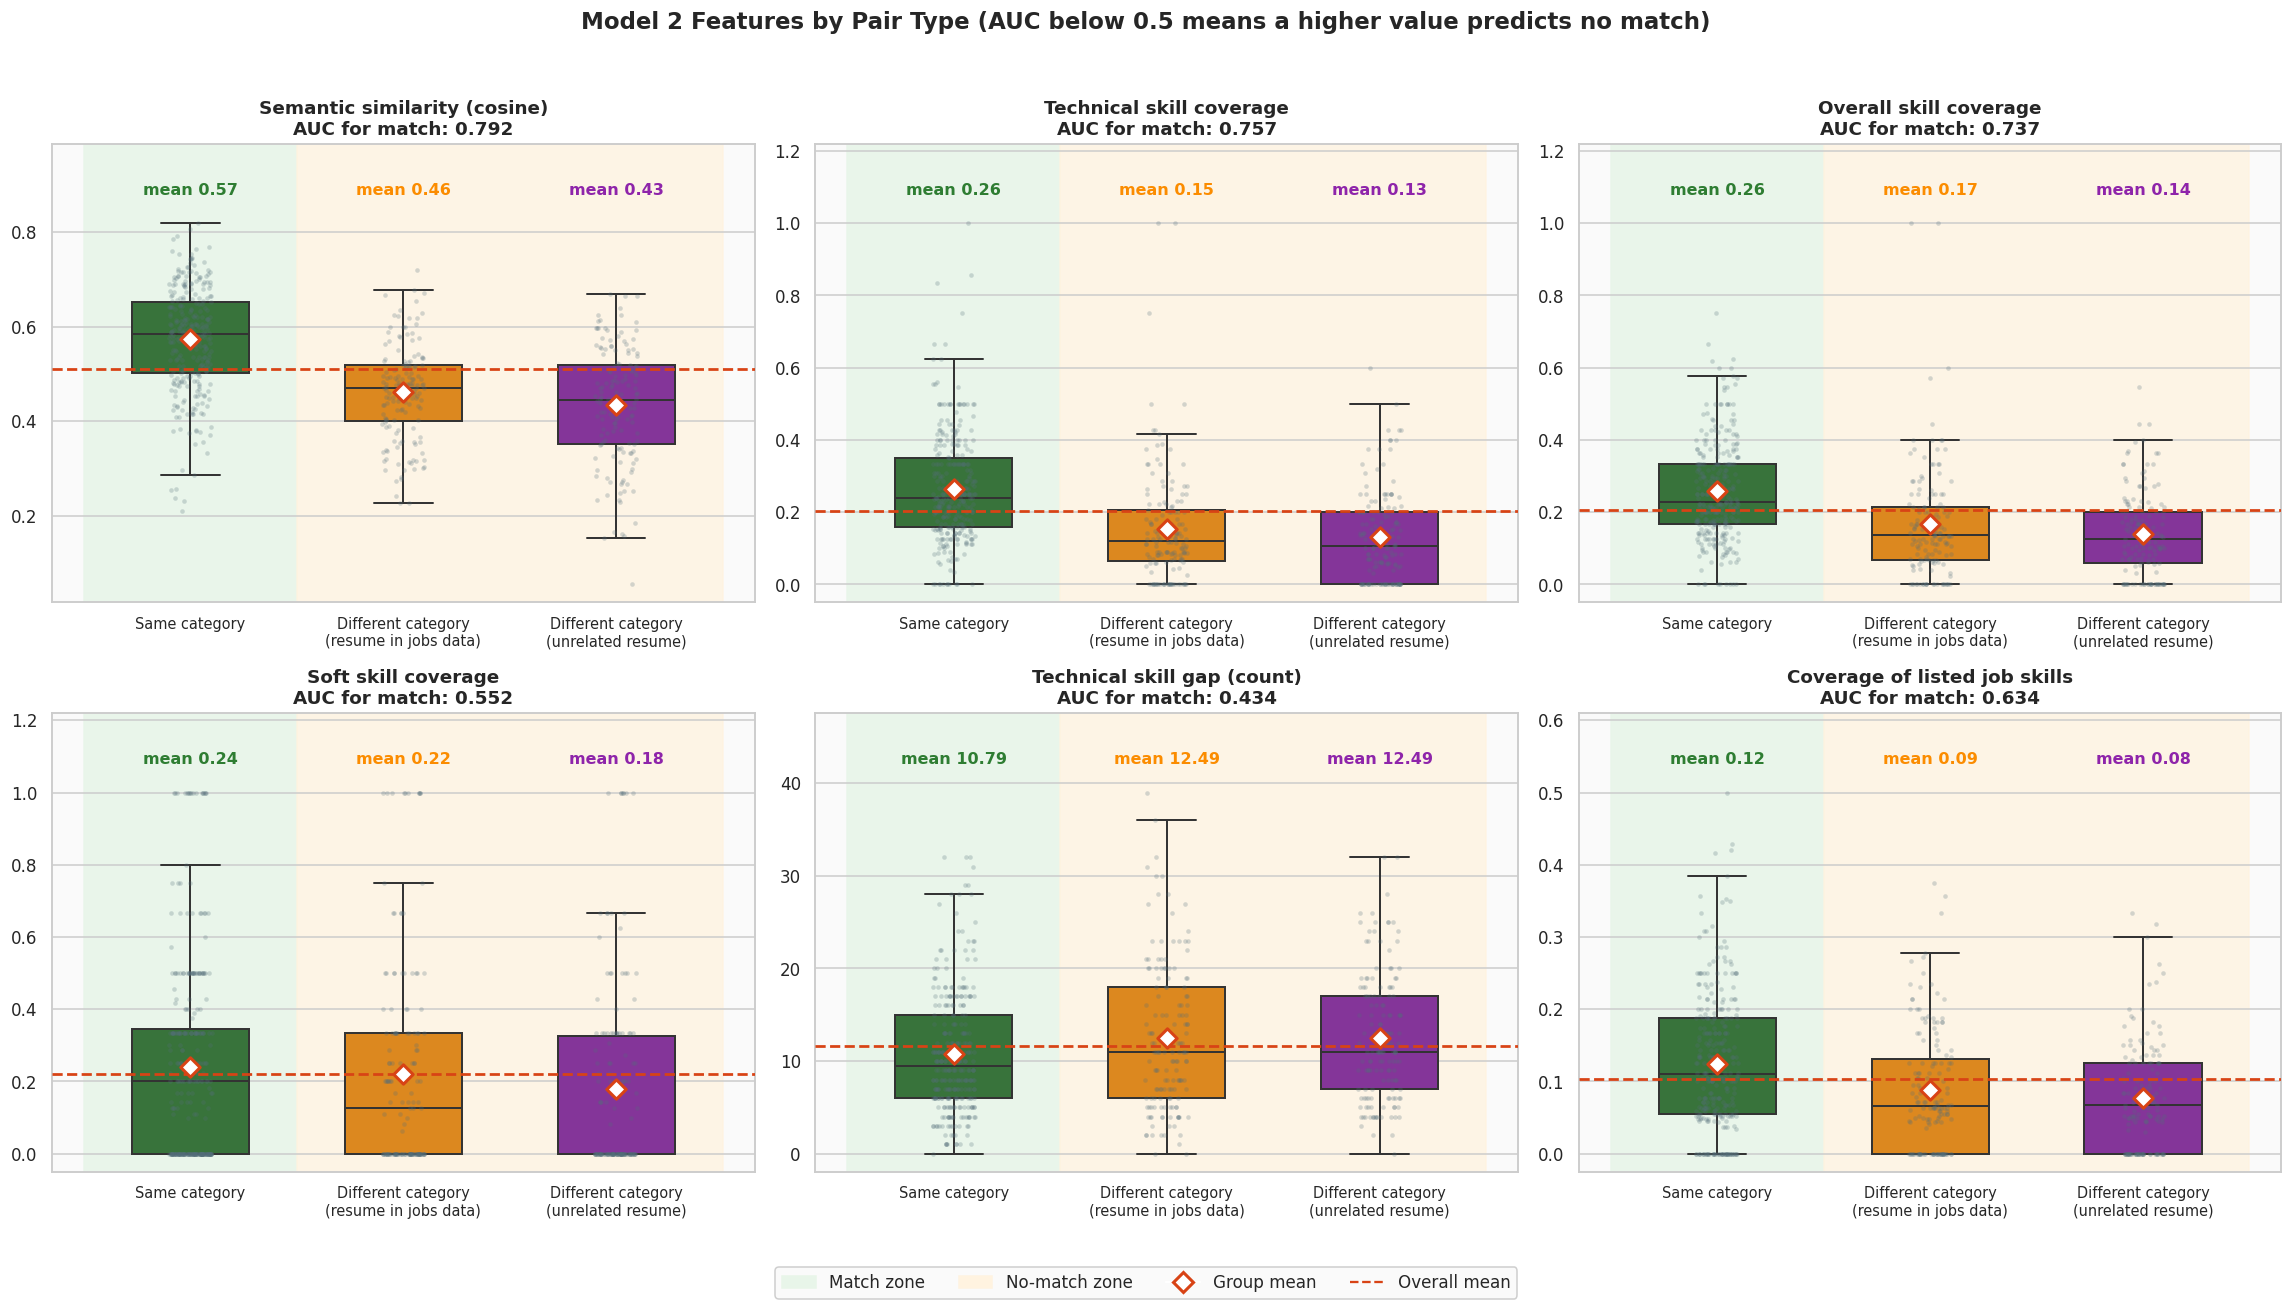

{'sim': np.float64(0.792), 'cov_tech': np.float64(0.757), 'cov_all': np.float64(0.737), 'cov_soft': np.float64(0.552), 'gap_tech': np.float64(0.434), 'cov_gt': np.float64(0.634)}


In [39]:
FEATS = ['sim', 'cov_tech', 'cov_all', 'cov_soft', 'gap_tech', 'cov_gt']
FTITLE = {'sim': 'Semantic similarity (cosine)', 'cov_tech': 'Technical skill coverage',
          'cov_all': 'Overall skill coverage', 'cov_soft': 'Soft skill coverage',
          'gap_tech': 'Technical skill gap (count)', 'cov_gt': 'Coverage of listed job skills'}
ORDER = ['same', 'hard_neg', 'easy_neg']
PTCOL = {'same': '#2e7d32', 'hard_neg': '#fb8c00', 'easy_neg': '#8e24aa'}
XL = ['Same category', 'Different category\n(resume in jobs data)', 'Different category\n(unrelated resume)']
auc_tab = {f: roc_auc_score(pairs['match'], pairs[f]) for f in FEATS}

fig, axes = plt.subplots(2, 3, figsize=(21, 12))
for ax, f in zip(axes.ravel(), FEATS):
    v = pairs[f]
    span = v.max() - v.min()
    ax.axvspan(-0.5, 0.5, color='#e8f5e9', alpha=0.9, zorder=0)
    ax.axvspan(0.5, 2.5, color='#fff3e0', alpha=0.8, zorder=0)
    sns.boxplot(data=pairs, x='pair_type', y=f, order=ORDER, hue='pair_type', palette=PTCOL, legend=False,
                width=0.55, linewidth=1.3, showfliers=False, ax=ax)
    sns.stripplot(data=pairs, x='pair_type', y=f, order=ORDER, color='#546e7a', alpha=0.25, size=3, ax=ax)
    mu = pairs.groupby('pair_type')[f].mean()
    ax.scatter(range(3), [mu[o] for o in ORDER], marker='D', s=80, color='white', edgecolor='#d84315', linewidth=2, zorder=6)
    ax.axhline(v.mean(), color='#d84315', linestyle='--', linewidth=1.8, zorder=4)
    ax.set_ylim(v.min() - 0.05 * span, v.max() + 0.22 * span)
    for i, o in enumerate(ORDER):
        ax.text(i, v.max() + 0.08 * span, f'mean {mu[o]:.2f}', ha='center', fontsize=10.5, fontweight='bold', color=PTCOL[o])
    ax.set_xticks(range(3))
    ax.set_xticklabels(XL, fontsize=9.5)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_title(f'{FTITLE[f]}\nAUC for match: {auc_tab[f]:.3f}')

handles = [Patch(color='#e8f5e9', label='Match zone'), Patch(color='#fff3e0', label='No-match zone'),
           plt.Line2D([0], [0], marker='D', color='w', markerfacecolor='white', markeredgecolor='#d84315',
                      markeredgewidth=2, markersize=9, label='Group mean'),
           plt.Line2D([0], [0], color='#d84315', linestyle='--', label='Overall mean')]
fig.legend(handles=handles, loc='lower center', ncol=4, framealpha=0.95)
fig.suptitle('Model 2 Features by Pair Type (AUC below 0.5 means a higher value predicts no match)', fontsize=15, fontweight='bold')
plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.show()
print({k: round(v, 3) for k, v in auc_tab.items()})

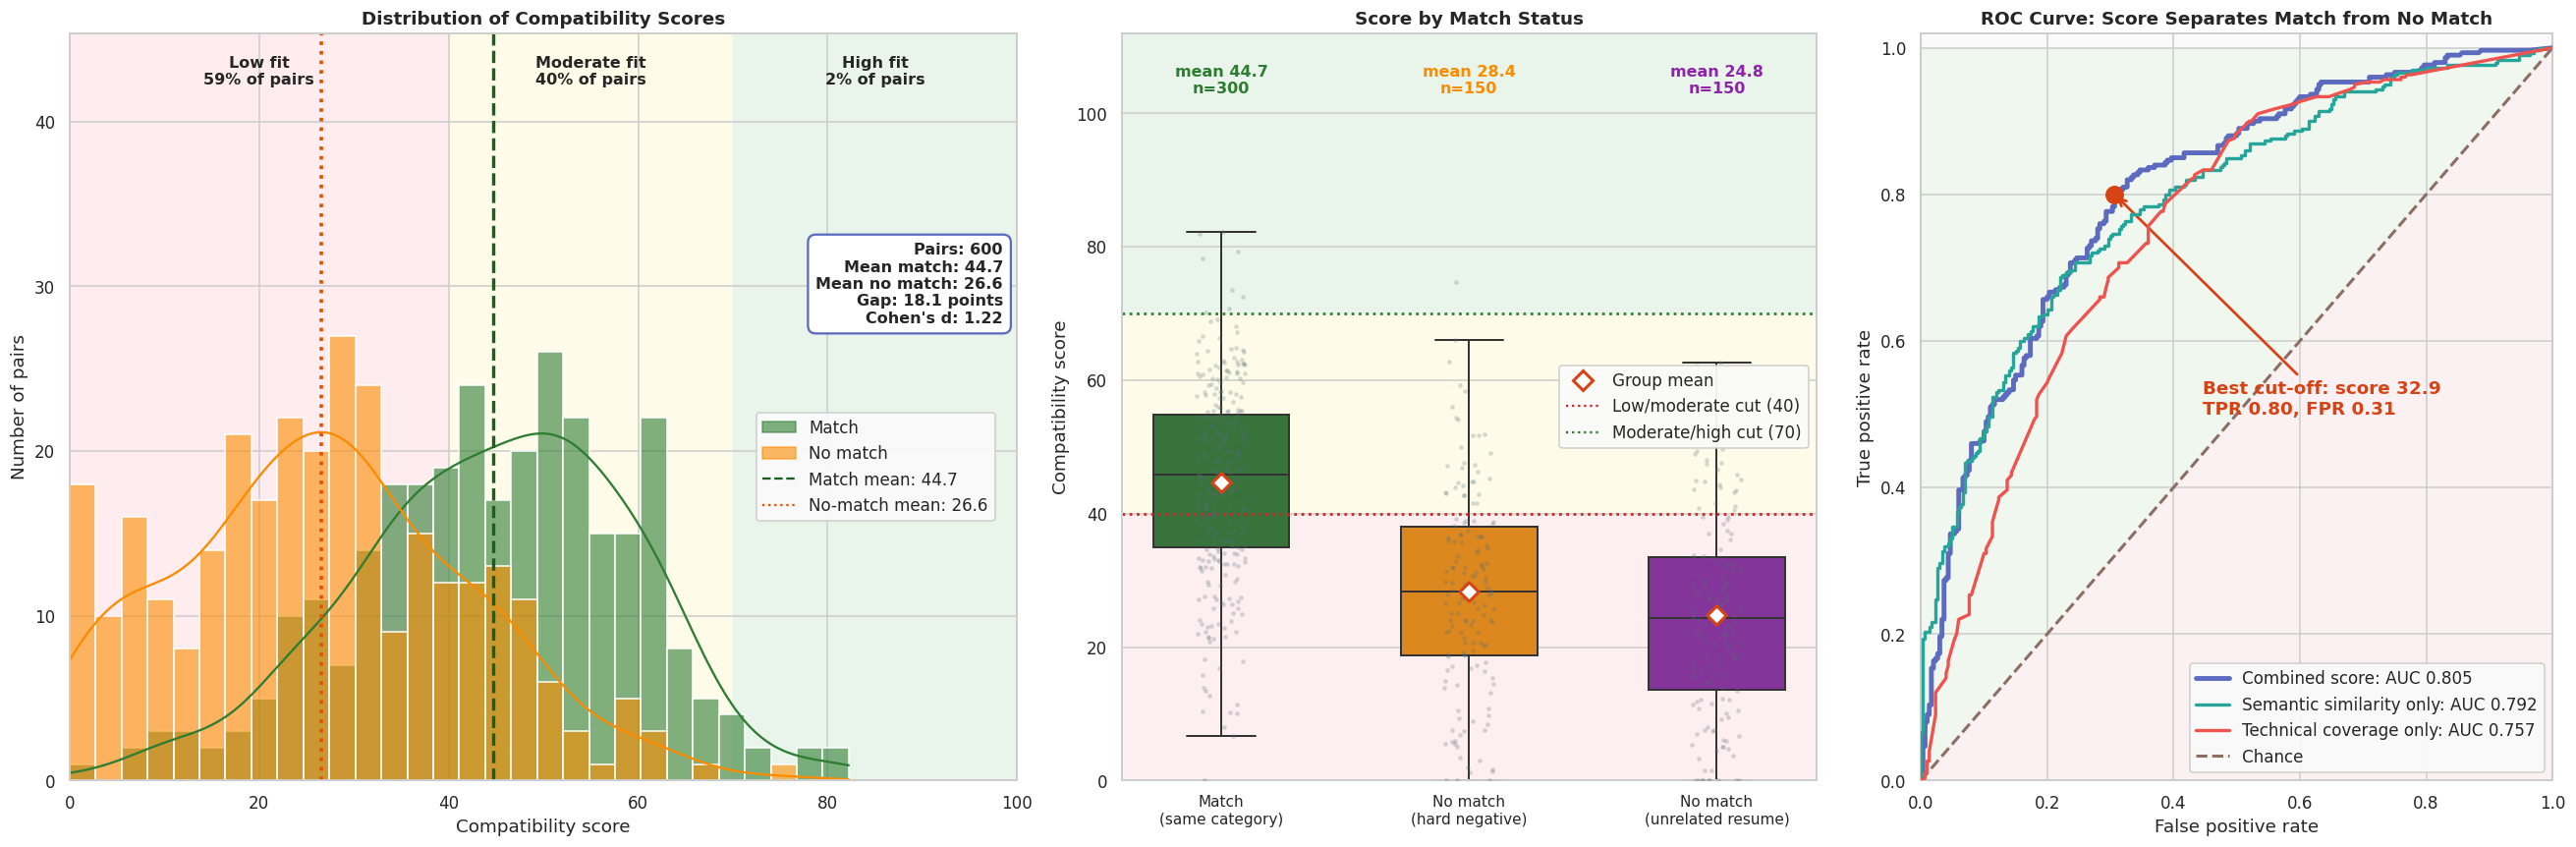

,mean,median,std,count
pair_type,,,,
same,44.71,45.78,14.56,300
hard_neg,28.40,28.26,15.11,150
easy_neg,24.77,24.30,15.20,150


{'Low fit': 58.7, 'Moderate fit': 39.8, 'High fit': 1.5}
{
  "weights": {
    "semantic": 0.45,
    "tech": 0.4,
    "soft": 0.15
  },
  "sim_lo": 0.2844,
  "sim_hi": 0.7066,
  "mean_score_match": 44.71,
  "mean_score_no_match": 26.58,
  "cohens_d": 1.216,
  "roc_auc": 0.8053,
  "point_biserial_r": 0.5202,
  "point_biserial_p": 6.567828086015666e-43
}


In [40]:
from sklearn.metrics import roc_curve

W = {'semantic': 0.45, 'tech': 0.40, 'soft': 0.15}
SIM_LO, SIM_HI = [float(q) for q in pairs['sim'].quantile([0.05, 0.95])]

def score_fn(sim, cov_tech, cov_soft):
    s = np.clip((sim - SIM_LO) / (SIM_HI - SIM_LO), 0, 1)
    return 100 * (W['semantic'] * s + W['tech'] * cov_tech + W['soft'] * cov_soft)

pairs['score'] = score_fn(pairs['sim'], pairs['cov_tech'], pairs['cov_soft'])
m1 = pairs.loc[pairs['match'] == 1, 'score']
m0 = pairs.loc[pairs['match'] == 0, 'score']
pooled = np.sqrt(((len(m1) - 1) * m1.var() + (len(m0) - 1) * m0.var()) / (len(m1) + len(m0) - 2))
cohen_d = (m1.mean() - m0.mean()) / pooled
auc_score = roc_auc_score(pairs['match'], pairs['score'])
pb_r, pb_p = stats.pointbiserialr(pairs['match'], pairs['score'])
by_type = pairs.groupby('pair_type')['score'].agg(['mean', 'median', 'std', 'count']).reindex(ORDER)
BAND_NAMES = ['Low fit', 'Moderate fit', 'High fit']
bands = pd.cut(pairs['score'], [-0.01, 40, 70, 100.01], labels=BAND_NAMES)
band_pct = bands.value_counts(normalize=True).reindex(BAND_NAMES) * 100

model2_rule_metrics = {
    'weights': W, 'sim_lo': round(SIM_LO, 4), 'sim_hi': round(SIM_HI, 4),
    'mean_score_match': round(float(m1.mean()), 2), 'mean_score_no_match': round(float(m0.mean()), 2),
    'cohens_d': round(float(cohen_d), 3), 'roc_auc': round(float(auc_score), 4),
    'point_biserial_r': round(float(pb_r), 4), 'point_biserial_p': float(pb_p)
}

fig, axes = plt.subplots(1, 3, figsize=(24, 8), gridspec_kw={'width_ratios': [1.5, 1.1, 1]})
ax = axes[0]
sns.histplot(data=pairs, x='score', hue='match', hue_order=[0, 1], palette={0: '#fb8c00', 1: '#2e7d32'},
             bins=30, alpha=0.6, kde=True, ax=ax, legend=False)
ymax = ax.get_ylim()[1] * 1.6
ax.set_ylim(0, ymax)
for lo_, hi_, col, name in [(0, 40, '#ffebee', 'Low fit'), (40, 70, '#fffde7', 'Moderate fit'), (70, 100, '#e8f5e9', 'High fit')]:
    ax.axvspan(lo_, hi_, color=col, alpha=0.9, zorder=0)
    ax.text((lo_ + hi_) / 2, ymax * 0.97, f'{name}\n{band_pct[name]:.0f}% of pairs', ha='center', va='top',
            fontsize=10.5, fontweight='bold')
ax.axvline(m1.mean(), color='#1b5e20', linestyle='--', linewidth=2.2)
ax.axvline(m0.mean(), color='#e65100', linestyle=':', linewidth=2.4)
ax.set_xlim(0, 100)
ax.set_xlabel('Compatibility score')
ax.set_ylabel('Number of pairs')
ax.set_title('Distribution of Compatibility Scores')
kpi = (f'Pairs: {len(pairs)}\nMean match: {m1.mean():.1f}\nMean no match: {m0.mean():.1f}\n'
       f"Gap: {m1.mean() - m0.mean():.1f} points\nCohen's d: {cohen_d:.2f}")
ax.text(0.985, 0.72, kpi, transform=ax.transAxes, ha='right', va='top', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
ax.legend(handles=[Patch(color='#2e7d32', alpha=0.6, label='Match'), Patch(color='#fb8c00', alpha=0.6, label='No match'),
                   plt.Line2D([0], [0], color='#1b5e20', linestyle='--', label=f'Match mean: {m1.mean():.1f}'),
                   plt.Line2D([0], [0], color='#e65100', linestyle=':', label=f'No-match mean: {m0.mean():.1f}')],
          loc='center right', bbox_to_anchor=(0.985, 0.42), framealpha=0.95)

ax2 = axes[1]
ax2.axhspan(0, 40, color='#ffebee', alpha=0.8, zorder=0)
ax2.axhspan(40, 70, color='#fffde7', alpha=0.9, zorder=0)
ax2.axhspan(70, 112, color='#e8f5e9', alpha=0.9, zorder=0)
sns.boxplot(data=pairs, x='pair_type', y='score', order=ORDER, hue='pair_type', palette=PTCOL, legend=False,
            width=0.55, linewidth=1.3, showfliers=False, ax=ax2)
sns.stripplot(data=pairs, x='pair_type', y='score', order=ORDER, color='#546e7a', alpha=0.25, size=3, ax=ax2)
ax2.scatter(range(3), by_type['mean'].values, marker='D', s=80, color='white', edgecolor='#d84315', linewidth=2, zorder=6)
ax2.axhline(40, color='#c62828', linestyle=':', linewidth=1.8)
ax2.axhline(70, color='#2e7d32', linestyle=':', linewidth=1.8)
for i, o in enumerate(ORDER):
    ax2.text(i, 105, f"mean {by_type.loc[o, 'mean']:.1f}\nn={int(by_type.loc[o, 'count'])}", ha='center', va='center',
             fontsize=10.5, fontweight='bold', color=PTCOL[o])
ax2.set_ylim(0, 112)
ax2.set_xticks(range(3))
ax2.set_xticklabels(['Match\n(same category)', 'No match\n(hard negative)', 'No match\n(unrelated resume)'], fontsize=10)
ax2.set_xlabel('')
ax2.set_ylabel('Compatibility score')
ax2.set_title('Score by Match Status')
ax2.legend(handles=[plt.Line2D([0], [0], marker='D', color='w', markerfacecolor='white', markeredgecolor='#d84315',
                               markeredgewidth=2, markersize=9, label='Group mean'),
                    plt.Line2D([0], [0], color='#c62828', linestyle=':', label='Low/moderate cut (40)'),
                    plt.Line2D([0], [0], color='#2e7d32', linestyle=':', label='Moderate/high cut (70)')],
           loc='center right', framealpha=0.95)

ax3 = axes[2]
ax3.fill_between([0, 1], [0, 1], [1, 1], color='#e8f5e9', alpha=0.6, zorder=0)
ax3.fill_between([0, 1], [0, 0], [0, 1], color='#ffebee', alpha=0.6, zorder=0)
curves = [('Combined score', pairs['score'], '#5c6bc0', 3.2), ('Semantic similarity only', pairs['sim'], '#26a69a', 2.2),
          ('Technical coverage only', pairs['cov_tech'], '#ef5350', 2.2)]
for name, s_, col, lw in curves:
    fpr, tpr, thr = roc_curve(pairs['match'], s_)
    a = roc_auc_score(pairs['match'], s_)
    ax3.plot(fpr, tpr, color=col, linewidth=lw, label=f'{name}: AUC {a:.3f}', zorder=3)
    if name == 'Combined score':
        k = int(np.argmax(tpr - fpr))
        ax3.scatter(fpr[k], tpr[k], s=130, color='#d84315', zorder=5)
        ax3.annotate(f'Best cut-off: score {thr[k]:.1f}\nTPR {tpr[k]:.2f}, FPR {fpr[k]:.2f}', xy=(fpr[k], tpr[k]),
                     xytext=(fpr[k] + 0.14, max(tpr[k] - 0.3, 0.05)), fontweight='bold', color='#d84315',
                     arrowprops=dict(arrowstyle='->', color='#d84315', linewidth=1.8))
ax3.plot([0, 1], [0, 1], color='#8d6e63', linestyle='--', linewidth=2, label='Chance')
ax3.set_xlim(0, 1)
ax3.set_ylim(0, 1.02)
ax3.set_xlabel('False positive rate')
ax3.set_ylabel('True positive rate')
ax3.set_title('ROC Curve: Score Separates Match from No Match')
ax3.legend(loc='lower right', framealpha=0.95)
plt.tight_layout()
plt.show()

display(by_type.round(2))
print(band_pct.round(1).to_dict())
print(json.dumps(model2_rule_metrics, indent=2))

In [41]:
from sklearn.metrics import (roc_auc_score, roc_curve, precision_score, recall_score,
                             accuracy_score, f1_score, confusion_matrix)
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance

gap_check = pairs.groupby('pair_type')['gap_tech'].agg(['sum', 'mean', 'std']).reindex(ORDER)
display(gap_check.round(3))

recomputed = [len({s for s in jobs['ext_skills'].iat[j] if s not in SOFT_SKILLS} - res_skills[int(r)])
              for r, j in zip(pairs['resume_idx'], pairs['job_idx'])]
print('gap_tech recompute matches:', bool(np.array_equal(recomputed, pairs['gap_tech'].values)))

sub_h = pairs[pairs['pair_type'].isin(['same', 'hard_neg'])]
hard_auc = {f: round(roc_auc_score(sub_h['match'], sub_h[f]), 3) for f in FEATS + ['score']}
print('AUC, same vs hard negatives only:', hard_auc)
print('max pairs per resume:', pairs['resume_idx'].value_counts().max(),
      '| max pairs per job:', pairs['job_idx'].value_counts().max())

,sum,mean,std
pair_type,,,
same,3236,10.787,6.493
hard_neg,1874,12.493,7.956
easy_neg,1874,12.493,6.753


gap_tech recompute matches: True
AUC, same vs hard negatives only: {'sim': np.float64(0.78), 'cov_tech': np.float64(0.745), 'cov_all': np.float64(0.719), 'cov_soft': np.float64(0.528), 'gap_tech': np.float64(0.446), 'cov_gt': np.float64(0.616), 'score': np.float64(0.785)}
max pairs per resume: 2 | max pairs per job: 3


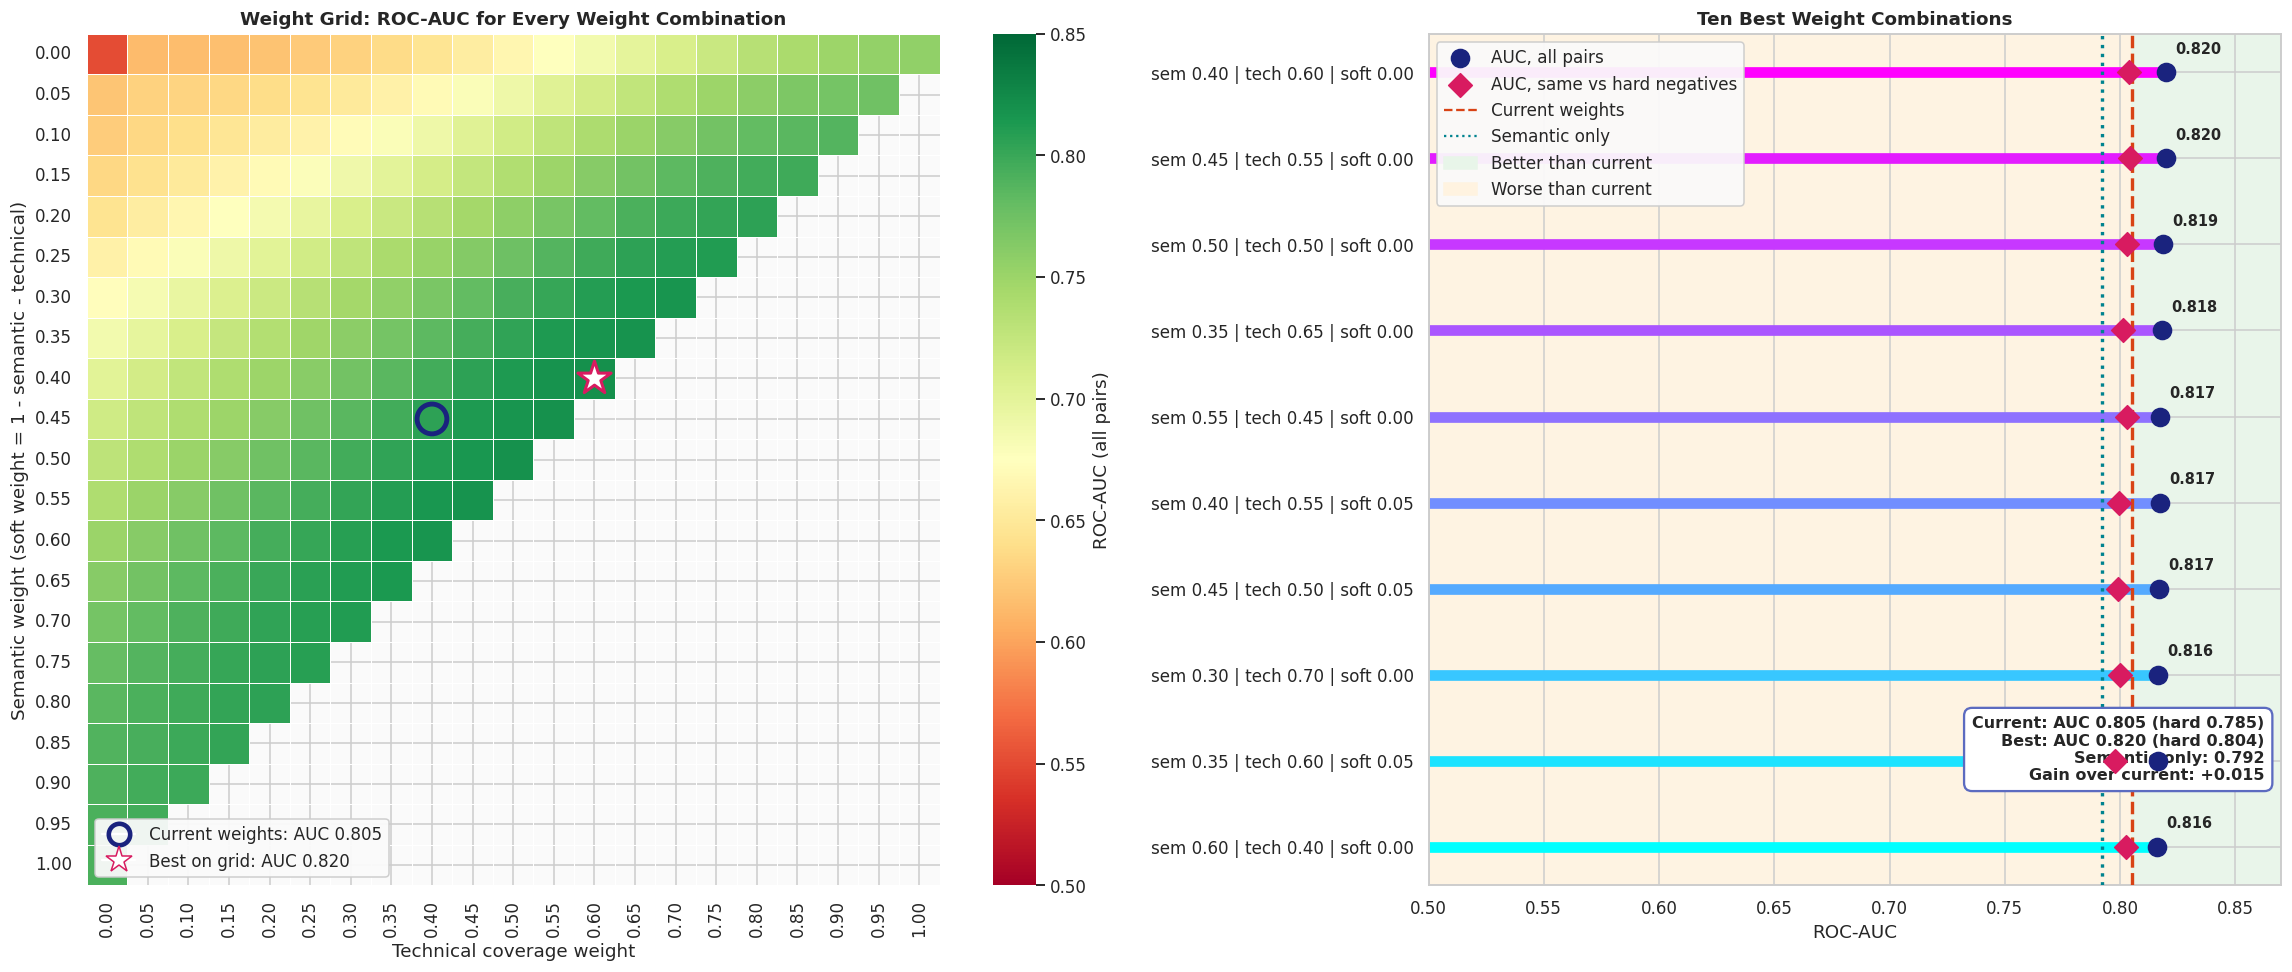

{'semantic': 0.4, 'tech': 0.6, 'soft': 0.0, 'auc_all': 0.82, 'auc_hard': 0.804}
current 0.8053 hard 0.7845


In [42]:
s_norm = np.clip((pairs['sim'] - SIM_LO) / (SIM_HI - SIM_LO), 0, 1).values
ct, cs = pairs['cov_tech'].values, pairs['cov_soft'].values
y_m = pairs['match'].values
hard_idx = pairs['pair_type'].isin(['same', 'hard_neg']).values

rows = []
for ia in range(21):
    for ib in range(21 - ia):
        a, b, c = ia / 20, ib / 20, (20 - ia - ib) / 20
        sc = a * s_norm + b * ct + c * cs
        rows.append({'semantic': a, 'tech': b, 'soft': c,
                     'auc_all': roc_auc_score(y_m, sc),
                     'auc_hard': roc_auc_score(y_m[hard_idx], sc[hard_idx])})
wgrid = pd.DataFrame(rows)

cur_sc = W['semantic'] * s_norm + W['tech'] * ct + W['soft'] * cs
cur_auc = roc_auc_score(y_m, cur_sc)
cur_hard = roc_auc_score(y_m[hard_idx], cur_sc[hard_idx])
best = wgrid.loc[wgrid['auc_all'].idxmax()]
sem_only = float(wgrid[wgrid['semantic'] == 1.0]['auc_all'].iloc[0])

fig, axes = plt.subplots(1, 2, figsize=(21, 9), gridspec_kw={'width_ratios': [1.25, 1]})
ax = axes[0]
piv = wgrid.pivot(index='semantic', columns='tech', values='auc_all')
sns.heatmap(piv, cmap='RdYlGn', vmin=0.5, vmax=max(0.85, float(best['auc_all'])), linewidths=0.4,
            linecolor='white', cbar_kws={'label': 'ROC-AUC (all pairs)'},
            xticklabels=[f'{v:.2f}' for v in piv.columns], yticklabels=[f'{v:.2f}' for v in piv.index], ax=ax)
ax.scatter(W['tech'] * 20 + 0.5, W['semantic'] * 20 + 0.5, s=380, facecolor='none', edgecolor='#1a237e', linewidth=3.2, zorder=5)
ax.scatter(best['tech'] * 20 + 0.5, best['semantic'] * 20 + 0.5, s=520, marker='*', color='#ffffff', edgecolor='#d81b60', linewidth=2, zorder=6)
ax.set_xlabel('Technical coverage weight')
ax.set_ylabel('Semantic weight (soft weight = 1 - semantic - technical)')
ax.set_title('Weight Grid: ROC-AUC for Every Weight Combination')
ax.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='none', markeredgecolor='#1a237e', markeredgewidth=3, markersize=14, label=f'Current weights: AUC {cur_auc:.3f}'),
                   plt.Line2D([0], [0], marker='*', color='w', markerfacecolor='white', markeredgecolor='#d81b60', markersize=18, label=f'Best on grid: AUC {best["auc_all"]:.3f}')],
          loc='lower left', framealpha=0.95)

ax2 = axes[1]
top10 = wgrid.nlargest(10, 'auc_all').iloc[::-1].reset_index(drop=True)
yy = np.arange(len(top10))
xmax = float(top10['auc_all'].max()) + 0.05
ax2.axvspan(0.5, cur_auc, color='#fff3e0', alpha=0.9, zorder=0)
ax2.axvspan(cur_auc, xmax, color='#e8f5e9', alpha=0.9, zorder=0)
ax2.hlines(yy, 0.5, top10['auc_all'], colors=plt.cm.cool(np.linspace(0, 1, len(top10))), linewidth=7, zorder=2)
ax2.scatter(top10['auc_all'], yy, s=140, color='#1a237e', zorder=4, label='AUC, all pairs')
ax2.scatter(top10['auc_hard'], yy, s=120, marker='D', color='#d81b60', zorder=4, label='AUC, same vs hard negatives')
for i, r in top10.iterrows():
    ax2.text(r['auc_all'] + 0.004, i + 0.22, f"{r['auc_all']:.3f}", fontsize=9.5, fontweight='bold')
ax2.axvline(cur_auc, color='#d84315', linestyle='--', linewidth=2.2, zorder=3)
ax2.axvline(sem_only, color='#00838f', linestyle=':', linewidth=2.2, zorder=3)
ax2.set_yticks(yy)
ax2.set_yticklabels([f"sem {r.semantic:.2f} | tech {r.tech:.2f} | soft {r.soft:.2f}" for r in top10.itertuples()])
ax2.set_xlim(0.5, xmax)
ax2.set_xlabel('ROC-AUC')
ax2.set_title('Ten Best Weight Combinations')
kpi = (f'Current: AUC {cur_auc:.3f} (hard {cur_hard:.3f})\nBest: AUC {best["auc_all"]:.3f} (hard {best["auc_hard"]:.3f})\n'
       f'Semantic only: {sem_only:.3f}\nGain over current: {best["auc_all"] - cur_auc:+.3f}')
ax2.text(0.98, 0.12, kpi, transform=ax2.transAxes, ha='right', va='bottom', fontsize=10.5, fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
handles, labels = ax2.get_legend_handles_labels()
handles += [plt.Line2D([0], [0], color='#d84315', linestyle='--'), plt.Line2D([0], [0], color='#00838f', linestyle=':'),
            Patch(color='#e8f5e9'), Patch(color='#fff3e0')]
labels += ['Current weights', 'Semantic only', 'Better than current', 'Worse than current']
ax2.legend(handles, labels, loc='upper left', framealpha=0.95)
plt.tight_layout()
plt.show()

print(best.round(3).to_dict())
print('current', round(cur_auc, 4), 'hard', round(cur_hard, 4))

In [43]:
SUP_FEATS = ['sim', 'cov_tech', 'cov_soft', 'cov_all', 'cov_gt', 'gap_tech', 'gap_all', 'n_job_ext', 'n_res_ext', 'len_ratio']
X_p = pairs[SUP_FEATS].values
y_p = pairs['match'].values
groups = pairs['resume_idx'].values
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X_p, y_p, groups))

sup_models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight='balanced', max_iter=2000)),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=SEED)
}
gcv = GroupKFold(n_splits=5)
sup_fit, sup_proba, rows = {}, {}, []
for name, mdl in sup_models.items():
    cvr = cross_validate(clone(mdl), X_p[tr], y_p[tr], groups=groups[tr], cv=gcv,
                         scoring=['accuracy', 'f1', 'roc_auc'], n_jobs=-1)
    m = clone(mdl).fit(X_p[tr], y_p[tr])
    p = m.predict_proba(X_p[te])[:, 1]
    pred = (p >= 0.5).astype(int)
    sup_fit[name], sup_proba[name] = m, p
    rows.append({'model': name, 'cv_acc': cvr['test_accuracy'].mean(), 'cv_f1': cvr['test_f1'].mean(),
                 'cv_auc': cvr['test_roc_auc'].mean(), 'test_acc': accuracy_score(y_p[te], pred),
                 'test_precision': precision_score(y_p[te], pred), 'test_recall': recall_score(y_p[te], pred),
                 'test_f1': f1_score(y_p[te], pred), 'test_auc': roc_auc_score(y_p[te], p)})

sc_all = pairs['score'].values
fpr_t, tpr_t, thr_t = roc_curve(y_p[tr], sc_all[tr])
cut_tr = float(thr_t[np.argmax(tpr_t - fpr_t)])
pred_r = (sc_all[te] >= cut_tr).astype(int)
rows.insert(0, {'model': 'Rule-based score', 'cv_acc': np.nan, 'cv_f1': np.nan, 'cv_auc': np.nan,
                'test_acc': accuracy_score(y_p[te], pred_r), 'test_precision': precision_score(y_p[te], pred_r),
                'test_recall': recall_score(y_p[te], pred_r), 'test_f1': f1_score(y_p[te], pred_r),
                'test_auc': roc_auc_score(y_p[te], sc_all[te])})

sup_df = pd.DataFrame(rows).set_index('model')
BEST_SUP = sup_df.loc[['Logistic Regression', 'Gradient Boosting'], 'test_auc'].idxmax()
display(sup_df.round(3))
print('train:', len(tr), '| test:', len(te), '| test match share:', round(float(y_p[te].mean()), 3))
print('resumes shared between train and test:', len(set(groups[tr]) & set(groups[te])))
print('rule-based cut-off chosen on train only:', round(cut_tr, 2), '| best supervised model:', BEST_SUP)

,cv_acc,cv_f1,cv_auc,test_acc,test_precision,test_recall,test_f1,test_auc
model,,,,,,,,
Rule-based score,NaN,NaN,NaN,0.718,0.682,0.789,0.732,0.815
Logistic Regression,0.748,0.744,0.800,0.761,0.730,0.807,0.767,0.823
Gradient Boosting,0.698,0.708,0.789,0.761,0.738,0.789,0.763,0.813


train: 483 | test: 117 | test match share: 0.487
resumes shared between train and test: 0
rule-based cut-off chosen on train only: 32.87 | best supervised model: Logistic Regression


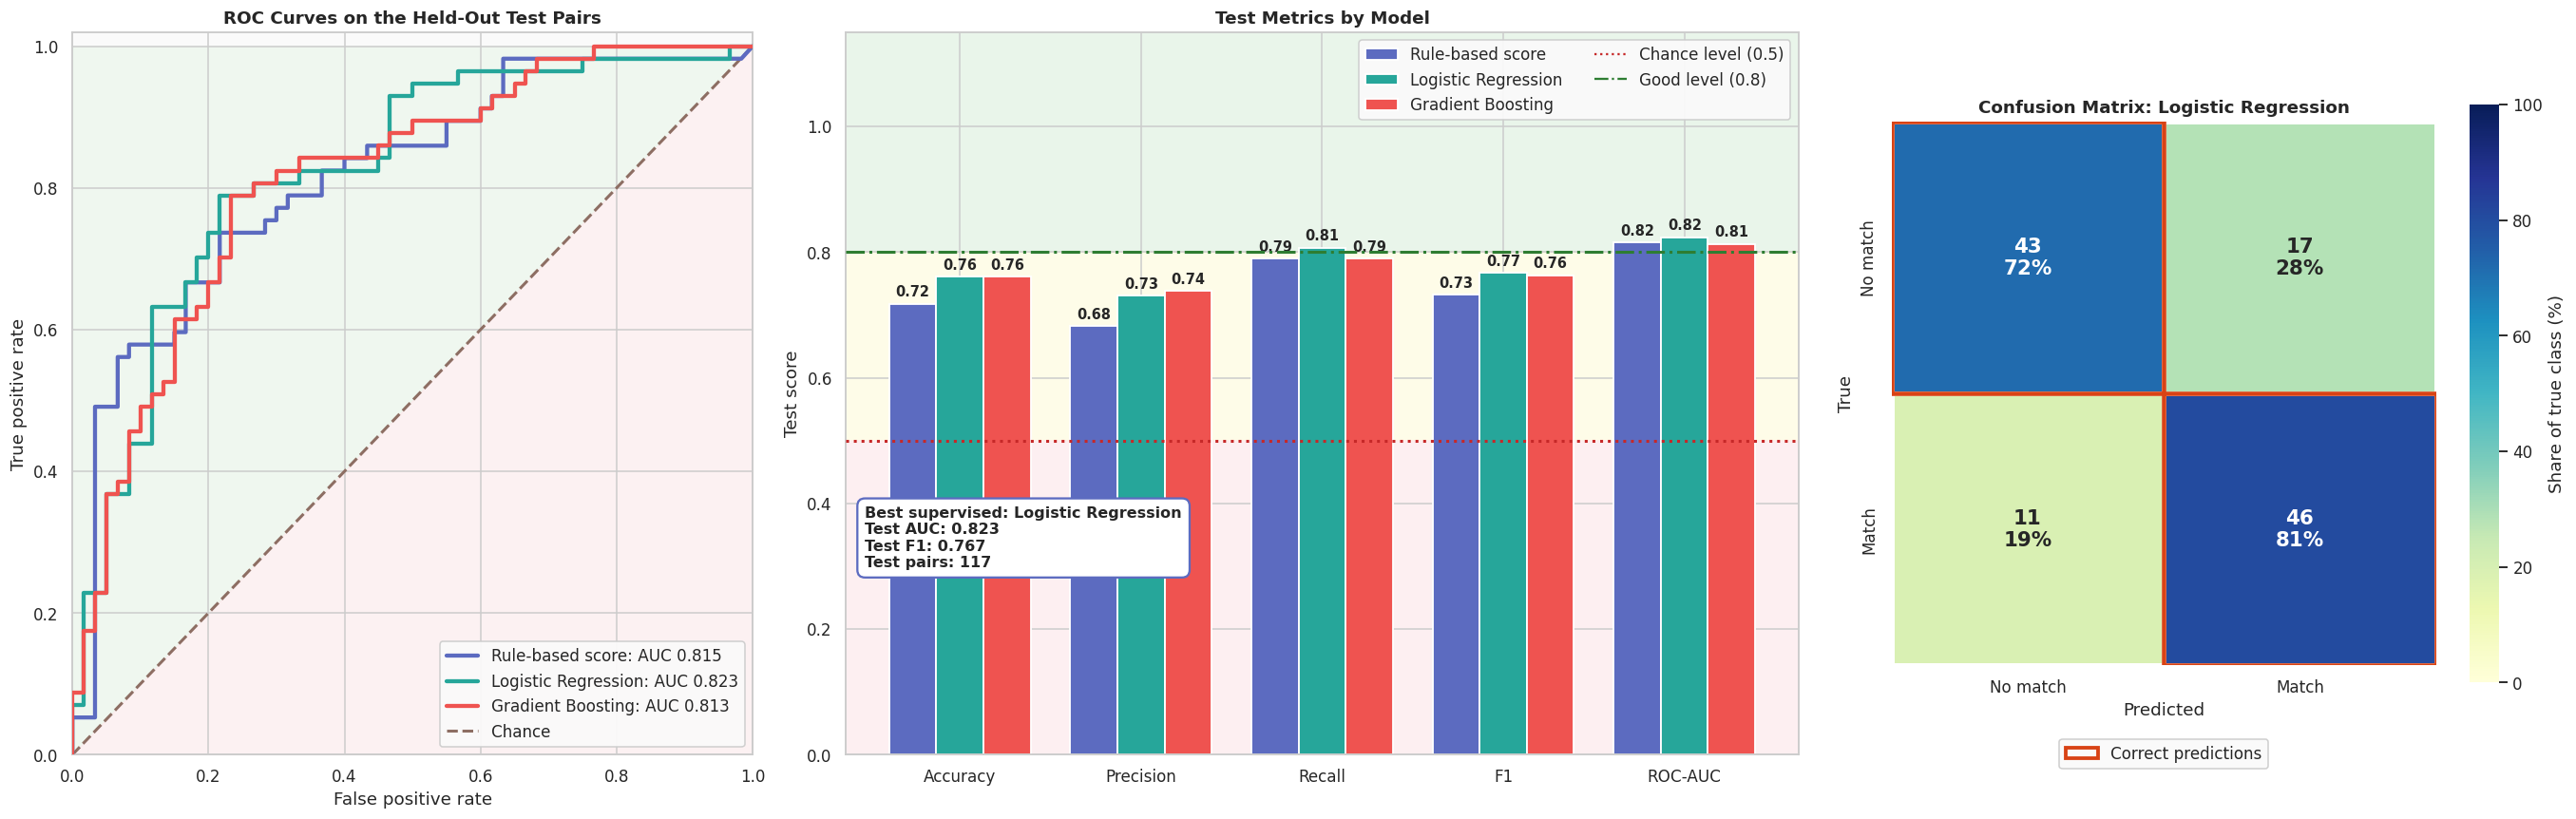

In [44]:
names3 = ['Rule-based score', 'Logistic Regression', 'Gradient Boosting']
cols3 = {'Rule-based score': '#5c6bc0', 'Logistic Regression': '#26a69a', 'Gradient Boosting': '#ef5350'}
score_te = {'Rule-based score': sc_all[te], 'Logistic Regression': sup_proba['Logistic Regression'],
            'Gradient Boosting': sup_proba['Gradient Boosting']}
mets = ['test_acc', 'test_precision', 'test_recall', 'test_f1', 'test_auc']
mlab = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']

fig, axes = plt.subplots(1, 3, figsize=(25, 8), gridspec_kw={'width_ratios': [1, 1.4, 1]})
ax = axes[0]
ax.fill_between([0, 1], [0, 1], [1, 1], color='#e8f5e9', alpha=0.6, zorder=0)
ax.fill_between([0, 1], [0, 0], [0, 1], color='#ffebee', alpha=0.6, zorder=0)
for n in names3:
    fpr, tpr, _ = roc_curve(y_p[te], score_te[n])
    ax.plot(fpr, tpr, color=cols3[n], linewidth=2.8, label=f'{n}: AUC {roc_auc_score(y_p[te], score_te[n]):.3f}', zorder=3)
ax.plot([0, 1], [0, 1], color='#8d6e63', linestyle='--', linewidth=2, label='Chance')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('ROC Curves on the Held-Out Test Pairs')
ax.legend(loc='lower right', framealpha=0.95)

ax2 = axes[1]
xx = np.arange(len(mets))
bw = 0.26
ax2.axhspan(0.8, 1.15, color='#e8f5e9', alpha=0.9, zorder=0)
ax2.axhspan(0.5, 0.8, color='#fffde7', alpha=0.9, zorder=0)
ax2.axhspan(0, 0.5, color='#ffebee', alpha=0.7, zorder=0)
for k, n in enumerate(names3):
    vals = sup_df.loc[n, mets].values.astype(float)
    bars = ax2.bar(xx + (k - 1) * bw, vals, bw, color=cols3[n], edgecolor='white', linewidth=1.2, zorder=2, label=n)
    for b, v in zip(bars, vals):
        ax2.text(b.get_x() + b.get_width() / 2, v + 0.012, f'{v:.2f}', ha='center', fontsize=9.5, fontweight='bold')
ax2.axhline(0.5, color='#c62828', linestyle=':', linewidth=2, zorder=3)
ax2.axhline(0.8, color='#2e7d32', linestyle='-.', linewidth=2, zorder=3)
ax2.set_xticks(xx)
ax2.set_xticklabels(mlab)
ax2.set_ylim(0, 1.15)
ax2.set_ylabel('Test score')
ax2.set_title('Test Metrics by Model')
kpi = f'Best supervised: {BEST_SUP}\nTest AUC: {sup_df.loc[BEST_SUP, "test_auc"]:.3f}\nTest F1: {sup_df.loc[BEST_SUP, "test_f1"]:.3f}\nTest pairs: {len(te)}'
ax2.text(0.02, 0.3, kpi, transform=ax2.transAxes, va='center', fontsize=10.5, fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
handles, labels = ax2.get_legend_handles_labels()
handles += [plt.Line2D([0], [0], color='#c62828', linestyle=':'), plt.Line2D([0], [0], color='#2e7d32', linestyle='-.')]
labels += ['Chance level (0.5)', 'Good level (0.8)']
ax2.legend(handles, labels, loc='upper right', ncol=2, framealpha=0.95)

ax3 = axes[2]
cmx = confusion_matrix(y_p[te], (sup_proba[BEST_SUP] >= 0.5).astype(int))
cmx_pct = cmx / cmx.sum(axis=1, keepdims=True) * 100
annot = np.array([[f'{cmx[i, j]}\n{cmx_pct[i, j]:.0f}%' for j in range(2)] for i in range(2)])
sns.heatmap(cmx_pct, annot=annot, fmt='', cmap='YlGnBu', vmin=0, vmax=100, linewidths=2, linecolor='white',
            xticklabels=['No match', 'Match'], yticklabels=['No match', 'Match'], square=True,
            cbar_kws={'label': 'Share of true class (%)', 'shrink': 0.8}, annot_kws={'fontsize': 14, 'fontweight': 'bold'}, ax=ax3)
for i in range(2):
    ax3.add_patch(Rectangle((i, i), 1, 1, fill=False, edgecolor='#d84315', linewidth=3))
ax3.set_xlabel('Predicted')
ax3.set_ylabel('True')
ax3.set_title(f'Confusion Matrix: {BEST_SUP}')
ax3.legend(handles=[Patch(fill=False, edgecolor='#d84315', linewidth=2.5, label='Correct predictions')],
           loc='upper center', bbox_to_anchor=(0.5, -0.12), framealpha=0.95)
plt.tight_layout()
plt.show()

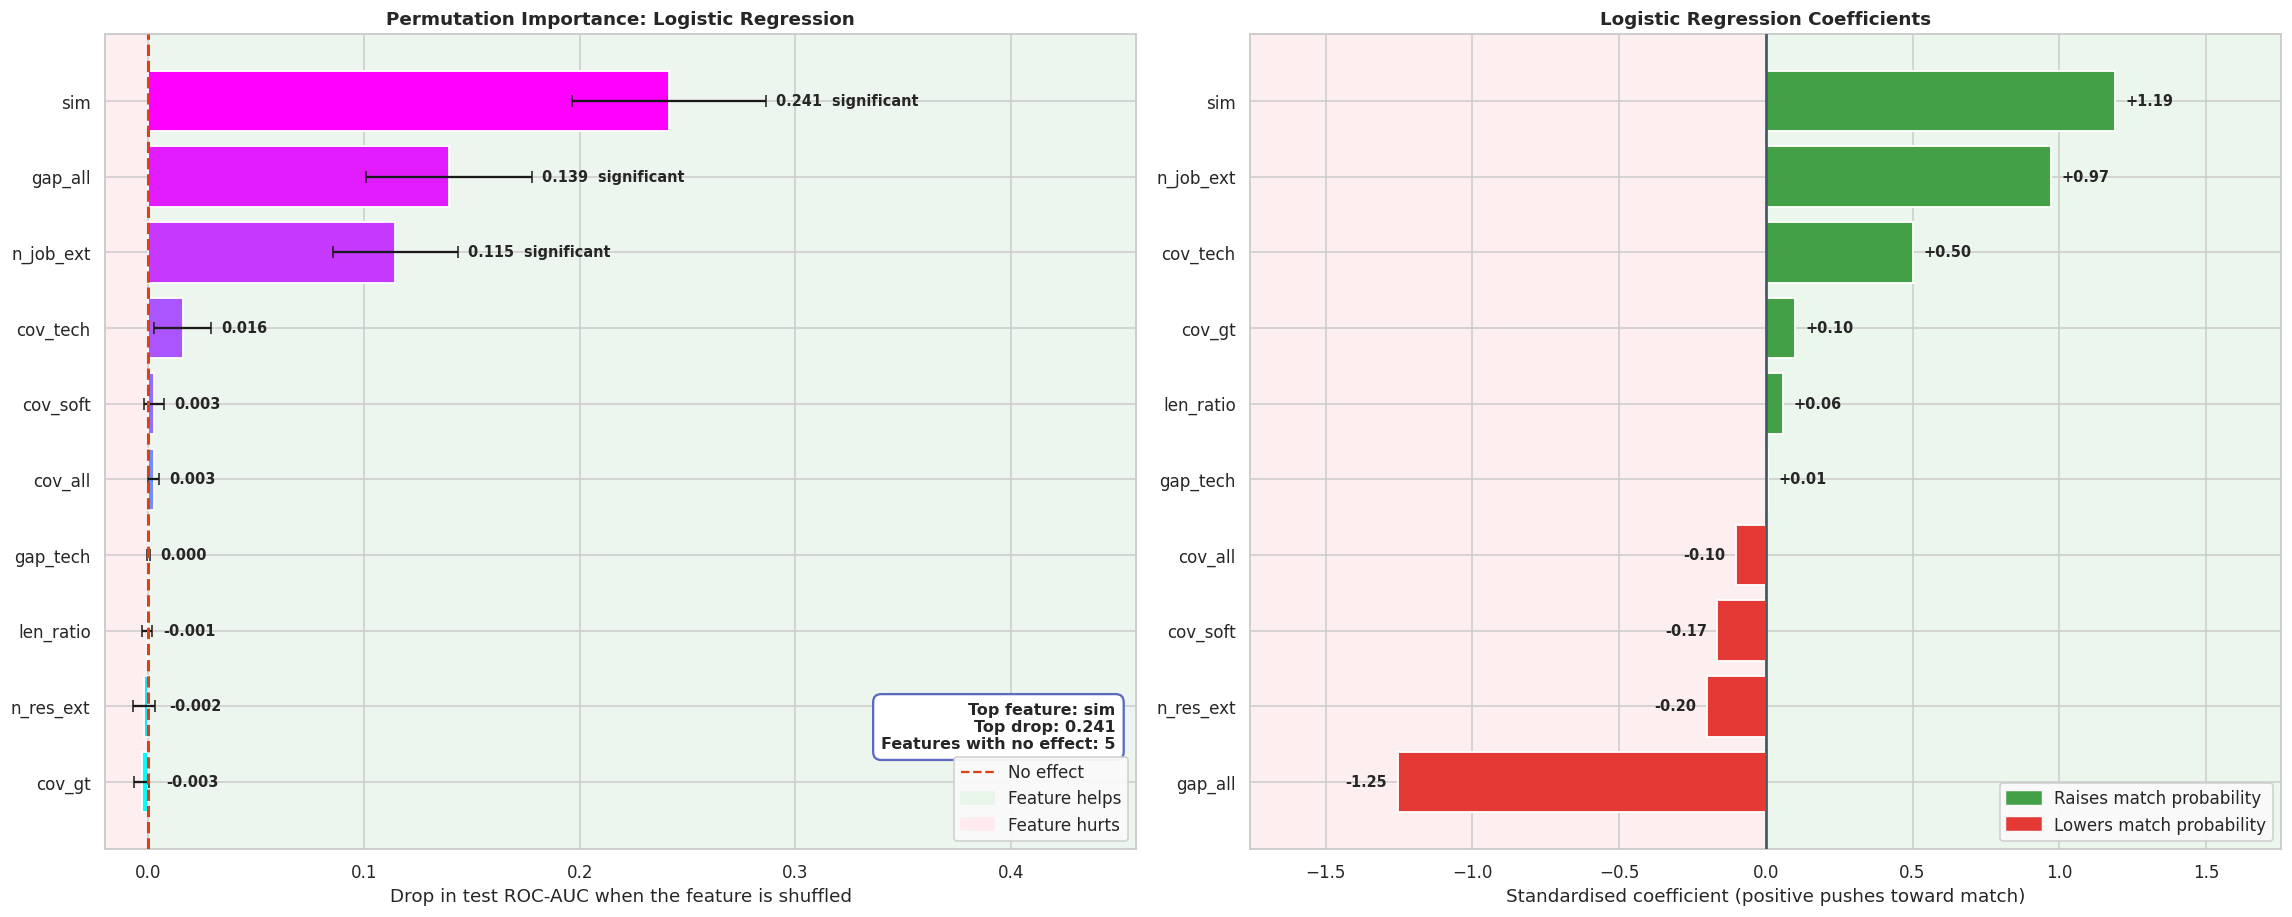

             mean     std
sim        0.2414  0.0448
gap_all    0.1395  0.0385
n_job_ext  0.1146  0.0289
cov_tech   0.0159  0.0131
cov_soft   0.0027  0.0047
cov_all    0.0026  0.0026
gap_tech   0.0000  0.0008
len_ratio -0.0006  0.0024
n_res_ext -0.0019  0.0050
cov_gt    -0.0031  0.0036


In [45]:
best_model = sup_fit[BEST_SUP]
pi = permutation_importance(best_model, X_p[te], y_p[te], scoring='roc_auc', n_repeats=30,
                            random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({'mean': pi.importances_mean, 'std': pi.importances_std}, index=SUP_FEATS).sort_values('mean')
lr_coef = pd.Series(sup_fit['Logistic Regression'][-1].coef_[0], index=SUP_FEATS).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(21, 8.5))
ax = axes[0]
lim = float((imp['mean'] + imp['std']).max()) * 1.6
ax.axvspan(-0.02, 0, color='#ffebee', alpha=0.8, zorder=0)
ax.axvspan(0, lim, color='#e8f5e9', alpha=0.7, zorder=0)
bars = ax.barh(imp.index, imp['mean'], xerr=imp['std'], capsize=4, color=plt.cm.cool(np.linspace(0, 1, len(imp))),
               edgecolor='white', linewidth=1.2, zorder=2)
for b, (f, r) in zip(bars, imp.iterrows()):
    flag = '  significant' if r['mean'] > 2 * r['std'] else ''
    ax.text(max(r['mean'], 0) + r['std'] + lim * 0.01, b.get_y() + b.get_height() / 2, f"{r['mean']:.3f}{flag}",
            va='center', fontsize=9.5, fontweight='bold')
ax.axvline(0, color='#d84315', linestyle='--', linewidth=2, zorder=3)
ax.set_xlim(-0.02, lim)
ax.set_xlabel('Drop in test ROC-AUC when the feature is shuffled')
ax.set_title(f'Permutation Importance: {BEST_SUP}')
kpi = f'Top feature: {imp["mean"].idxmax()}\nTop drop: {imp["mean"].max():.3f}\nFeatures with no effect: {int((imp["mean"] <= imp["std"]).sum())}'
ax.text(0.98, 0.15, kpi, transform=ax.transAxes, ha='right', va='center', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
ax.legend(handles=[plt.Line2D([0], [0], color='#d84315', linestyle='--', label='No effect'),
                   Patch(color='#e8f5e9', label='Feature helps'), Patch(color='#ffebee', label='Feature hurts')],
          loc='lower right', framealpha=0.95)

ax2 = axes[1]
cl = float(lr_coef.abs().max()) * 1.4
ax2.axvspan(-cl, 0, color='#ffebee', alpha=0.8, zorder=0)
ax2.axvspan(0, cl, color='#e8f5e9', alpha=0.8, zorder=0)
bars2 = ax2.barh(lr_coef.index, lr_coef.values, color=np.where(lr_coef.values >= 0, '#43a047', '#e53935'),
                 edgecolor='white', linewidth=1.2, zorder=2)
for b, v in zip(bars2, lr_coef.values):
    ax2.text(v + (cl * 0.02 if v >= 0 else -cl * 0.02), b.get_y() + b.get_height() / 2, f'{v:+.2f}', va='center',
             ha='left' if v >= 0 else 'right', fontsize=9.5, fontweight='bold')
ax2.axvline(0, color='#455a64', linewidth=1.8, zorder=3)
ax2.set_xlim(-cl, cl)
ax2.set_xlabel('Standardised coefficient (positive pushes toward match)')
ax2.set_title('Logistic Regression Coefficients')
ax2.legend(handles=[Patch(color='#43a047', label='Raises match probability'), Patch(color='#e53935', label='Lowers match probability')],
           loc='lower right', framealpha=0.95)
plt.tight_layout()
plt.show()
print(imp.sort_values('mean', ascending=False).round(4))

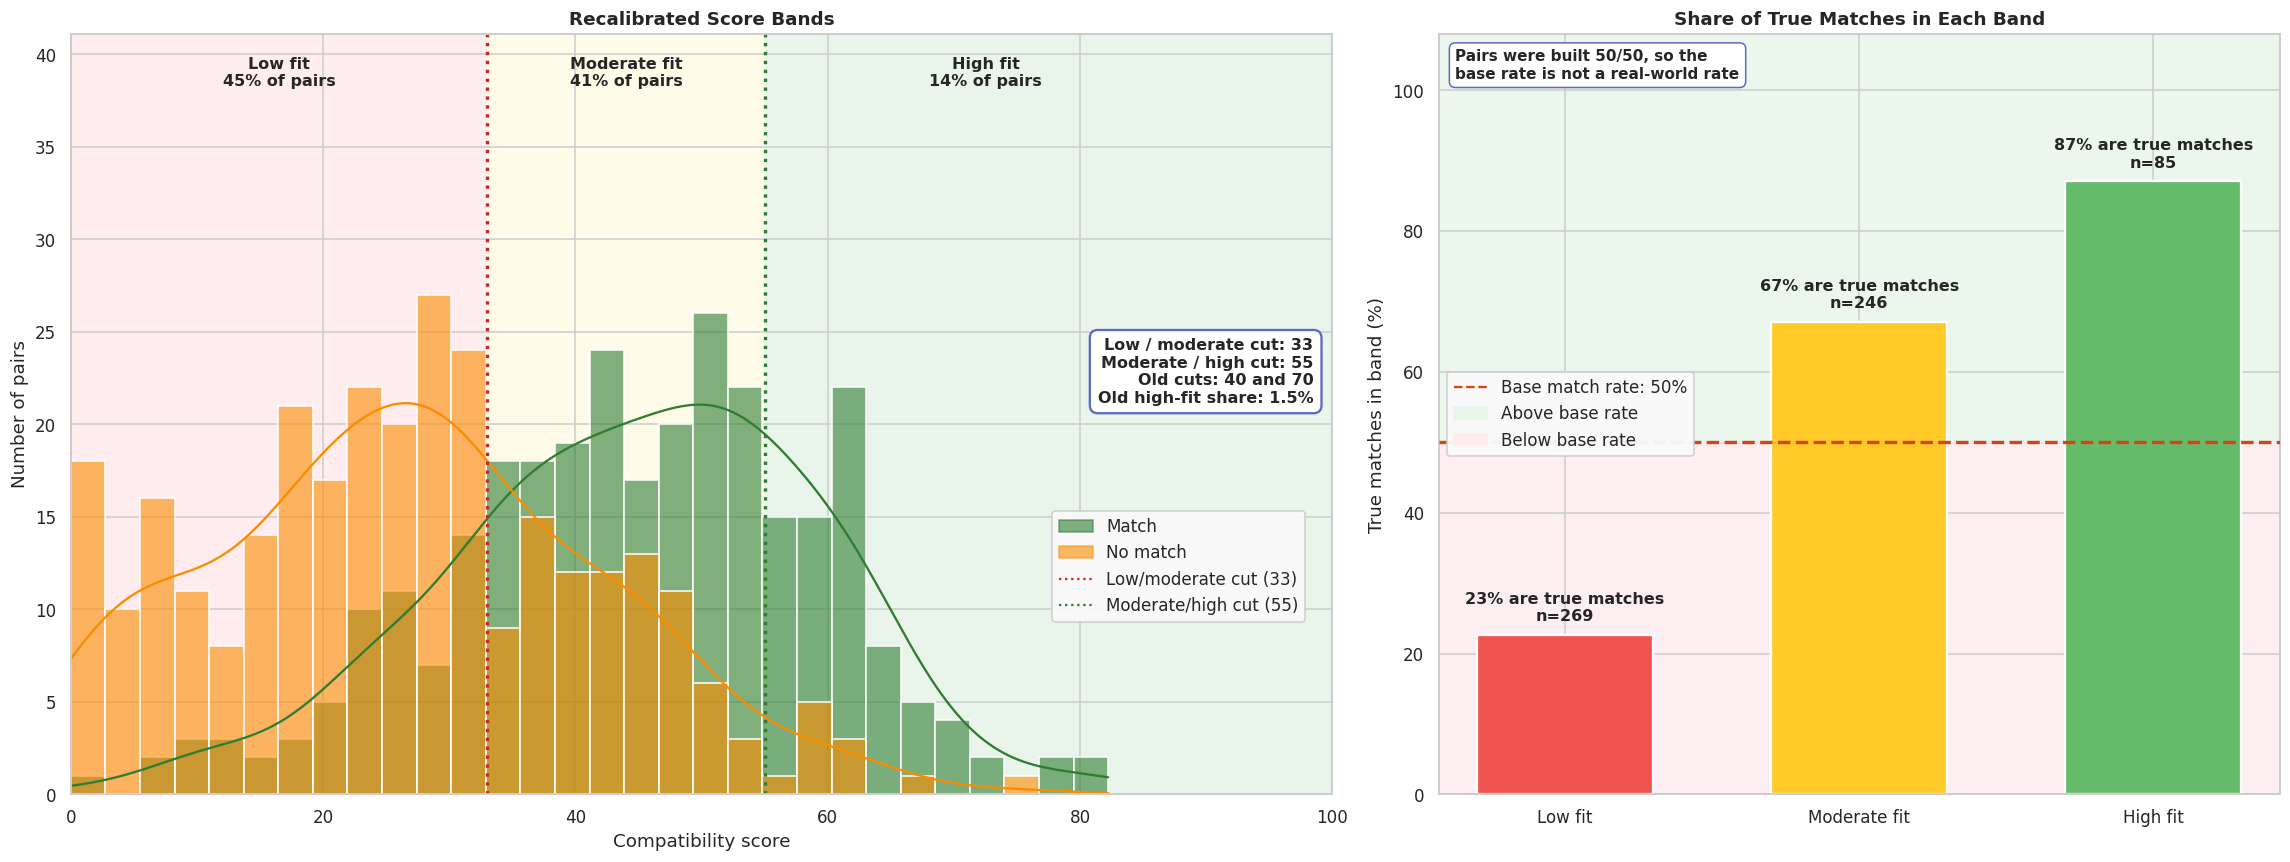

,n,match_rate,share_pct,match_rate_pct
band,,,,
Low fit,269,0.23,44.83,22.68
Moderate fit,246,0.67,41.00,67.07
High fit,85,0.87,14.17,87.06


{'low_max': 33, 'high_min': 55}


In [46]:
fpr_b, tpr_b, thr_b = roc_curve(pairs['match'], pairs['score'])
cut_low = int(round(float(thr_b[np.argmax(tpr_b - fpr_b)])))
cut_high = int(round(float(pairs.loc[pairs['match'] == 1, 'score'].quantile(0.75))))
SCORE_BANDS = {'low_max': cut_low, 'high_min': cut_high}

pairs['band'] = pd.cut(pairs['score'], [-0.01, cut_low, cut_high, 100.01], labels=BAND_NAMES, right=False)
band_tab = pairs.groupby('band', observed=False).agg(n=('match', 'size'), match_rate=('match', 'mean'))
band_tab['share_pct'] = band_tab['n'] / len(pairs) * 100
band_tab['match_rate_pct'] = band_tab['match_rate'] * 100
base_rate = pairs['match'].mean() * 100
bcol = {'Low fit': '#ef5350', 'Moderate fit': '#ffca28', 'High fit': '#66bb6a'}

fig, axes = plt.subplots(1, 2, figsize=(21, 8), gridspec_kw={'width_ratios': [1.5, 1]})
ax = axes[0]
sns.histplot(data=pairs, x='score', hue='match', hue_order=[0, 1], palette={0: '#fb8c00', 1: '#2e7d32'},
             bins=30, alpha=0.6, kde=True, ax=ax, legend=False)
ymax = ax.get_ylim()[1] * 1.45
ax.set_ylim(0, ymax)
edges = [0, cut_low, cut_high, 100]
for k, name in enumerate(BAND_NAMES):
    ax.axvspan(edges[k], edges[k + 1], color=['#ffebee', '#fffde7', '#e8f5e9'][k], alpha=0.9, zorder=0)
    ax.text((edges[k] + min(edges[k + 1], 90)) / 2, ymax * 0.97, f'{name}\n{band_tab.loc[name, "share_pct"]:.0f}% of pairs',
            ha='center', va='top', fontsize=10.5, fontweight='bold')
ax.axvline(cut_low, color='#c62828', linestyle=':', linewidth=2.2)
ax.axvline(cut_high, color='#2e7d32', linestyle=':', linewidth=2.2)
ax.set_xlim(0, 100)
ax.set_xlabel('Compatibility score')
ax.set_ylabel('Number of pairs')
ax.set_title('Recalibrated Score Bands')
kpi = f'Low / moderate cut: {cut_low}\nModerate / high cut: {cut_high}\nOld cuts: 40 and 70\nOld high-fit share: 1.5%'
ax.text(0.985, 0.6, kpi, transform=ax.transAxes, ha='right', va='top', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
ax.legend(handles=[Patch(color='#2e7d32', alpha=0.6, label='Match'), Patch(color='#fb8c00', alpha=0.6, label='No match'),
                   plt.Line2D([0], [0], color='#c62828', linestyle=':', label=f'Low/moderate cut ({cut_low})'),
                   plt.Line2D([0], [0], color='#2e7d32', linestyle=':', label=f'Moderate/high cut ({cut_high})')],
          loc='center right', bbox_to_anchor=(0.985, 0.3), framealpha=0.95)

ax2 = axes[1]
ax2.axhspan(base_rate, 108, color='#e8f5e9', alpha=0.8, zorder=0)
ax2.axhspan(0, base_rate, color='#ffebee', alpha=0.7, zorder=0)
bars = ax2.bar(BAND_NAMES, band_tab['match_rate_pct'], color=[bcol[b] for b in BAND_NAMES],
               edgecolor='white', linewidth=1.5, width=0.6, zorder=2)
for b, (n_, r) in zip(bars, band_tab.iterrows()):
    ax2.text(b.get_x() + b.get_width() / 2, r['match_rate_pct'] + 2, f"{r['match_rate_pct']:.0f}% are true matches\nn={int(r['n'])}",
             ha='center', fontsize=10.5, fontweight='bold')
ax2.axhline(base_rate, color='#d84315', linestyle='--', linewidth=2.2, zorder=3, label=f'Base match rate: {base_rate:.0f}%')
ax2.set_ylim(0, 108)
ax2.set_ylabel('True matches in band (%)')
ax2.set_title('Share of True Matches in Each Band')
ax2.text(0.02, 0.98, 'Pairs were built 50/50, so the\nbase rate is not a real-world rate', transform=ax2.transAxes, va='top',
         fontsize=10, fontweight='bold', bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='#5c6bc0'))
ax2.legend(handles=[plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Base match rate: {base_rate:.0f}%'),
                    Patch(color='#e8f5e9', label='Above base rate'), Patch(color='#ffebee', label='Below base rate')],
          loc='center left', framealpha=0.95)
plt.tight_layout()
plt.show()

model2_rule_metrics['score_bands'] = SCORE_BANDS
display(band_tab.round(2))
print(SCORE_BANDS)

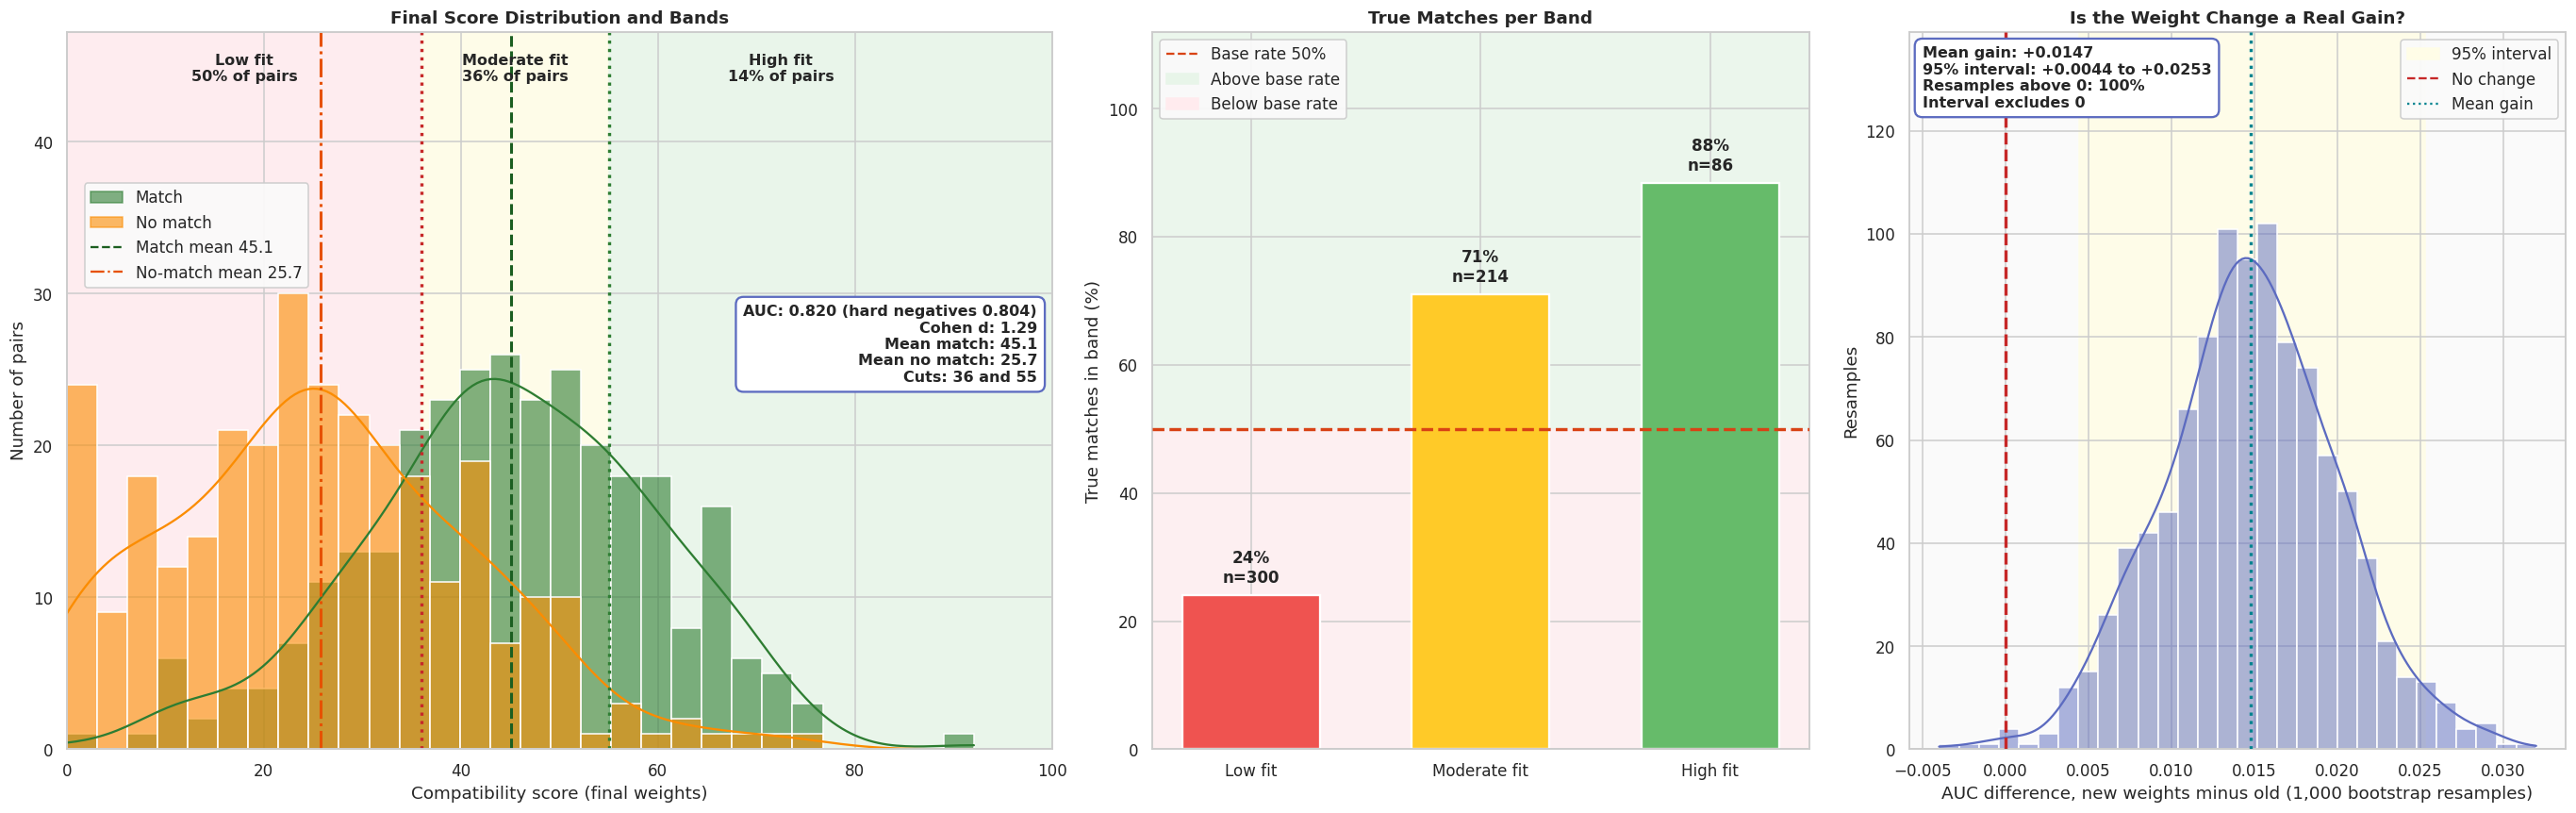

,n,match_rate,share_pct,match_rate_pct
band,,,,
Low fit,300,0.24,50.00,24.00
Moderate fit,214,0.71,35.67,71.03
High fit,86,0.88,14.33,88.37


{
  "weights": {
    "semantic": 0.45,
    "tech": 0.55,
    "soft": 0.0
  },
  "sim_lo": 0.2844,
  "sim_hi": 0.7066,
  "mean_score_match": 45.06,
  "mean_score_no_match": 25.73,
  "cohens_d": 1.286,
  "roc_auc": 0.8199,
  "point_biserial_r": 0.5415,
  "point_biserial_p": 6.567828086015666e-43,
  "score_bands": {
    "low_max": 36,
    "high_min": 55
  },
  "roc_auc_hard_negatives": 0.8041,
  "auc_gain_over_old_weights_ci95": [
    0.0044,
    0.0253
  ]
}


In [47]:
W = {'semantic': 0.45, 'tech': 0.55, 'soft': 0.0}
pairs['score_old'] = pairs['score']
pairs['score'] = score_fn(pairs['sim'], pairs['cov_tech'], pairs['cov_soft'])

y_m = pairs['match'].values
sc_new, sc_old = pairs['score'].values, pairs['score_old'].values
hard = pairs['pair_type'].isin(['same', 'hard_neg']).values
m1 = pairs.loc[pairs['match'] == 1, 'score']
m0 = pairs.loc[pairs['match'] == 0, 'score']
pooled = np.sqrt(((len(m1) - 1) * m1.var() + (len(m0) - 1) * m0.var()) / (len(m1) + len(m0) - 2))
cohen_d = (m1.mean() - m0.mean()) / pooled
auc_new, auc_old = roc_auc_score(y_m, sc_new), roc_auc_score(y_m, sc_old)
auc_hard_new = roc_auc_score(y_m[hard], sc_new[hard])
pb_r, pb_p = stats.pointbiserialr(y_m, sc_new)

rng = np.random.default_rng(SEED)
diffs = []
for _ in range(1000):
    i = rng.integers(0, len(pairs), len(pairs))
    if y_m[i].min() == y_m[i].max():
        continue
    diffs.append(roc_auc_score(y_m[i], sc_new[i]) - roc_auc_score(y_m[i], sc_old[i]))
diffs = np.array(diffs)
ci_lo, ci_hi = np.percentile(diffs, [2.5, 97.5])

fpr_b, tpr_b, thr_b = roc_curve(y_m, sc_new)
cut_low = int(round(float(thr_b[np.argmax(tpr_b - fpr_b)])))
cut_high = int(round(float(m1.quantile(0.75))))
SCORE_BANDS = {'low_max': cut_low, 'high_min': cut_high}
pairs['band'] = pd.cut(pairs['score'], [-0.01, cut_low, cut_high, 100.01], labels=BAND_NAMES, right=False)
band_tab = pairs.groupby('band', observed=False).agg(n=('match', 'size'), match_rate=('match', 'mean'))
band_tab['share_pct'] = band_tab['n'] / len(pairs) * 100
band_tab['match_rate_pct'] = band_tab['match_rate'] * 100
base_rate = float(y_m.mean() * 100)
bcol = {'Low fit': '#ef5350', 'Moderate fit': '#ffca28', 'High fit': '#66bb6a'}

fig, axes = plt.subplots(1, 3, figsize=(25, 8), gridspec_kw={'width_ratios': [1.5, 1, 1]})
ax = axes[0]
sns.histplot(data=pairs, x='score', hue='match', hue_order=[0, 1], palette={0: '#fb8c00', 1: '#2e7d32'},
             bins=30, alpha=0.6, kde=True, ax=ax, legend=False)
ymax = ax.get_ylim()[1] * 1.5
ax.set_ylim(0, ymax)
edges = [0, cut_low, cut_high, 100]
for k, name in enumerate(BAND_NAMES):
    ax.axvspan(edges[k], edges[k + 1], color=['#ffebee', '#fffde7', '#e8f5e9'][k], alpha=0.9, zorder=0)
    ax.text((edges[k] + min(edges[k + 1], 90)) / 2, ymax * 0.97, f'{name}\n{band_tab.loc[name, "share_pct"]:.0f}% of pairs',
            ha='center', va='top', fontsize=10.5, fontweight='bold')
ax.axvline(cut_low, color='#c62828', linestyle=':', linewidth=2.2)
ax.axvline(cut_high, color='#2e7d32', linestyle=':', linewidth=2.2)
ax.axvline(m1.mean(), color='#1b5e20', linestyle='--', linewidth=2)
ax.axvline(m0.mean(), color='#e65100', linestyle='-.', linewidth=2)
ax.set_xlim(0, 100)
ax.set_xlabel('Compatibility score (final weights)')
ax.set_ylabel('Number of pairs')
ax.set_title('Final Score Distribution and Bands')
kpi = (f'AUC: {auc_new:.3f} (hard negatives {auc_hard_new:.3f})\nCohen d: {cohen_d:.2f}\n'
       f'Mean match: {m1.mean():.1f}\nMean no match: {m0.mean():.1f}\nCuts: {cut_low} and {cut_high}')
ax.text(0.985, 0.62, kpi, transform=ax.transAxes, ha='right', va='top', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
ax.legend(handles=[Patch(color='#2e7d32', alpha=0.6, label='Match'), Patch(color='#fb8c00', alpha=0.6, label='No match'),
                   plt.Line2D([0], [0], color='#1b5e20', linestyle='--', label=f'Match mean {m1.mean():.1f}'),
                   plt.Line2D([0], [0], color='#e65100', linestyle='-.', label=f'No-match mean {m0.mean():.1f}')],
          loc='upper left', bbox_to_anchor=(0.01, 0.8), framealpha=0.95)

ax2 = axes[1]
ax2.axhspan(base_rate, 112, color='#e8f5e9', alpha=0.8, zorder=0)
ax2.axhspan(0, base_rate, color='#ffebee', alpha=0.7, zorder=0)
bars = ax2.bar(BAND_NAMES, band_tab['match_rate_pct'], color=[bcol[b] for b in BAND_NAMES], edgecolor='white',
               linewidth=1.5, width=0.6, zorder=2)
for b, (_, r) in zip(bars, band_tab.iterrows()):
    ax2.text(b.get_x() + b.get_width() / 2, r['match_rate_pct'] + 2, f"{r['match_rate_pct']:.0f}%\nn={int(r['n'])}",
             ha='center', fontsize=11, fontweight='bold')
ax2.axhline(base_rate, color='#d84315', linestyle='--', linewidth=2.2, zorder=3)
ax2.set_ylim(0, 112)
ax2.set_ylabel('True matches in band (%)')
ax2.set_title('True Matches per Band')
ax2.legend(handles=[plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Base rate {base_rate:.0f}%'),
                    Patch(color='#e8f5e9', label='Above base rate'), Patch(color='#ffebee', label='Below base rate')],
           loc='upper left', framealpha=0.95)

ax3 = axes[2]
ax3.axvspan(ci_lo, ci_hi, color='#fffde7', alpha=0.9, zorder=0)
sns.histplot(diffs, bins=30, kde=True, color='#5c6bc0', edgecolor='white', ax=ax3, zorder=2)
ax3.axvline(0, color='#c62828', linestyle='--', linewidth=2.2, zorder=3)
ax3.axvline(diffs.mean(), color='#00838f', linestyle=':', linewidth=2.2, zorder=3)
ax3.set_ylim(0, ax3.get_ylim()[1] * 1.3)
ax3.set_xlabel('AUC difference, new weights minus old (1,000 bootstrap resamples)')
ax3.set_ylabel('Resamples')
ax3.set_title('Is the Weight Change a Real Gain?')
verdict = 'Interval excludes 0' if ci_lo > 0 else 'Interval includes 0'
ax3.text(0.02, 0.98, f'Mean gain: {diffs.mean():+.4f}\n95% interval: {ci_lo:+.4f} to {ci_hi:+.4f}\nResamples above 0: {(diffs > 0).mean() * 100:.0f}%\n{verdict}',
         transform=ax3.transAxes, va='top', fontsize=10.5, fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
ax3.legend(handles=[Patch(color='#fffde7', label='95% interval'), plt.Line2D([0], [0], color='#c62828', linestyle='--', label='No change'),
                    plt.Line2D([0], [0], color='#00838f', linestyle=':', label='Mean gain')], loc='upper right', framealpha=0.95)
plt.tight_layout()
plt.show()

sup_report = sup_df.loc[['Logistic Regression', 'Gradient Boosting']].round(4).to_dict('index')
model2_rule_metrics.update({
    'weights': W, 'mean_score_match': round(float(m1.mean()), 2), 'mean_score_no_match': round(float(m0.mean()), 2),
    'cohens_d': round(float(cohen_d), 3), 'roc_auc': round(float(auc_new), 4), 'roc_auc_hard_negatives': round(float(auc_hard_new), 4),
    'point_biserial_r': round(float(pb_r), 4), 'score_bands': SCORE_BANDS,
    'auc_gain_over_old_weights_ci95': [round(float(ci_lo), 4), round(float(ci_hi), 4)]})
model2_sup_metrics = {'best_supervised': BEST_SUP, 'test_metrics': sup_report}
display(band_tab.round(2))
print(json.dumps(model2_rule_metrics, indent=2))

In [48]:
from sklearn.model_selection import train_test_split

idx_all = np.arange(len(jobs))
m3_tr, m3_hold = train_test_split(idx_all, test_size=0.2, stratify=jobs[JOB_CAT].values, random_state=SEED)
m3_te = np.sort(np.random.default_rng(SEED).choice(m3_hold, 200, replace=False))

M3_MIN_FREQ = 3
train_counter = Counter(s for l in jobs['skills_list'].iloc[m3_tr] for s in l)
vocab_tr = sorted(s for s, c in train_counter.items() if c >= M3_MIN_FREQ)
vocab_tr_set = set(vocab_tr)

def build_extractor(vocab, aliases=SYNONYMS):
    vs = set(vocab)
    tmap = {}
    for s in vocab:
        tmap.setdefault(clean_text(s), s)
    for a, canon in aliases.items():
        if len(a) >= 3 and canon in vs:
            tmap.setdefault(clean_text(a), canon)
    tmap.pop('', None)
    max_n = max(len(t.split()) for t in tmap)
    def extract(clean):
        tok = clean.split()
        found, i, n_tok = set(), 0, len(tok)
        while i < n_tok:
            step = 1
            for n in range(min(max_n, n_tok - i), 0, -1):
                g = ' '.join(tok[i:i + n])
                if g in tmap:
                    found.add(tmap[g])
                    step = n
                    break
            i += step
        return sorted(found)
    return extract, tmap

extract_tr, tmap_tr = build_extractor(vocab_tr)

def prf(tp, fp, fn):
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)

def evaluate(pred_lists, true_lists, keep=lambda s: True):
    rows = []
    for pr, tr_ in zip(pred_lists, true_lists):
        P, T = {s for s in pr if keep(s)}, {s for s in tr_ if keep(s)}
        tp, fp, fn = len(P & T), len(P - T), len(T - P)
        p, r, f = prf(tp, fp, fn)
        rows.append({'tp': tp, 'fp': fp, 'fn': fn, 'precision': p, 'recall': r, 'f1': f, 'n_true': len(T), 'n_pred': len(P)})
    return pd.DataFrame(rows)

def summarize(df):
    v = df[df['n_true'] > 0]
    mp, mr, mf = prf(df['tp'].sum(), df['fp'].sum(), df['fn'].sum())
    return {'micro_precision': mp, 'micro_recall': mr, 'micro_f1': mf, 'macro_precision': v['precision'].mean(),
            'macro_recall': v['recall'].mean(), 'macro_f1': v['f1'].mean(), 'jobs': len(v)}

GROUPS = {'All skills': lambda s: True, 'Technical': lambda s: s not in SOFT_SKILLS, 'Soft': lambda s: s in SOFT_SKILLS}
test_true = [jobs['skills_list'].iat[k] for k in m3_te]
test_pred = [extract_tr(jobs['jd_clean'].iat[k]) for k in m3_te]
ceiling = {}
for g, f in GROUPS.items():
    tot = sum(f(s) for l in test_true for s in l)
    ceiling[g] = sum(f(s) and s in vocab_tr_set for l in test_true for s in l) / tot

print('train jobs:', len(m3_tr), '| held-out pool:', len(m3_hold), '| evaluated:', len(m3_te))
print('train-only vocabulary:', len(vocab_tr), '| full vocabulary from Cell 6:', len(skills_vocab))
print('recall ceiling (true skills inside vocabulary):', {g: round(v, 3) for g, v in ceiling.items()})
print('avg extracted per job:', round(np.mean([len(p) for p in test_pred]), 2),
      '| avg listed per job:', round(np.mean([len(t) for t in test_true]), 2))

train jobs: 933 | held-out pool: 234 | evaluated: 200
train-only vocabulary: 709 | full vocabulary from Cell 6: 874
recall ceiling (true skills inside vocabulary): {'All skills': 0.722, 'Technical': 0.574, 'Soft': 1.0}
avg extracted per job: 16.49 | avg listed per job: 17.98


,micro_precision,micro_recall,micro_f1,macro_precision,macro_recall,macro_f1,jobs
All skills,0.338,0.310,0.323,0.344,0.303,0.310,200.0
Technical,0.288,0.321,0.304,0.292,0.316,0.289,200.0
Soft,0.528,0.289,0.374,0.475,0.280,0.333,200.0


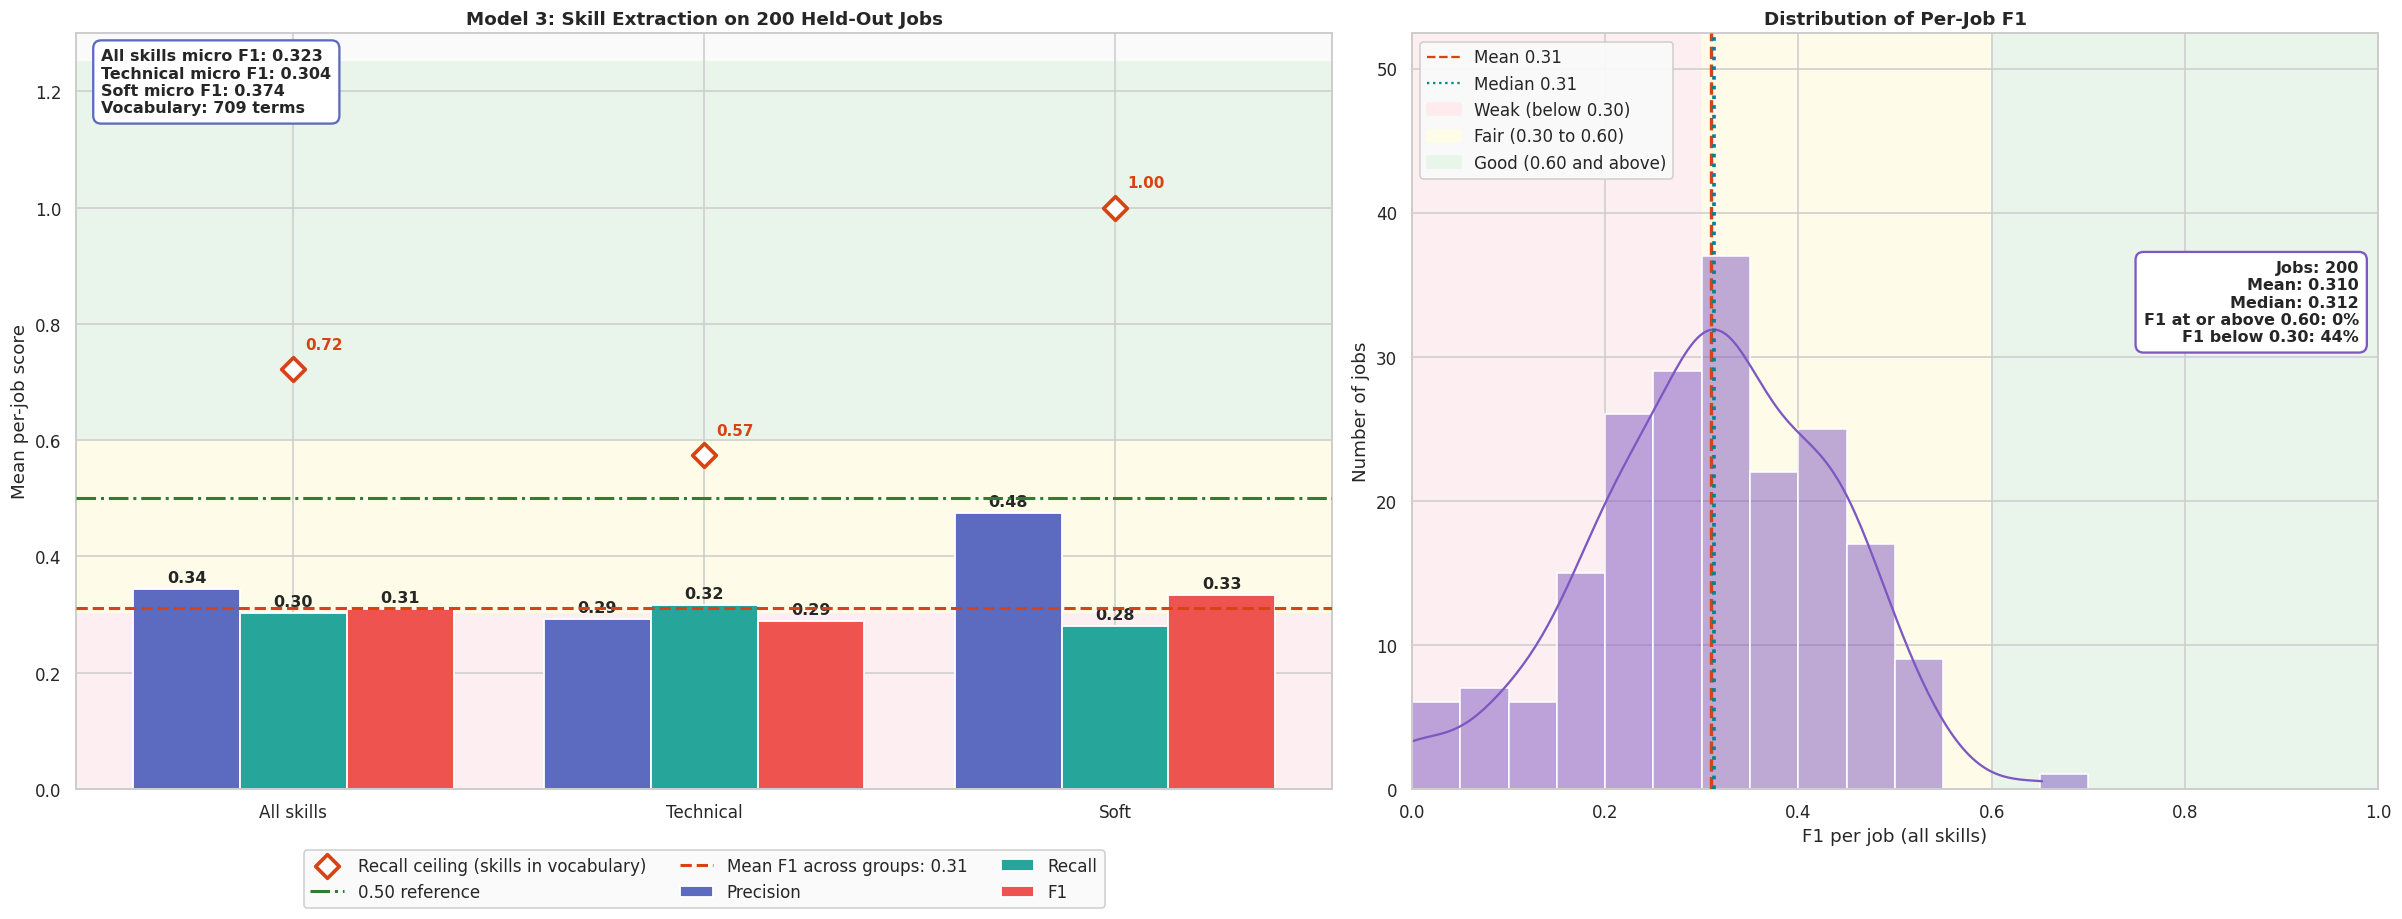

In [49]:
base = {g: summarize(evaluate(test_pred, test_true, f)) for g, f in GROUPS.items()}
display(pd.DataFrame(base).T.round(3))

gnames = list(GROUPS)
mkeys = ['macro_precision', 'macro_recall', 'macro_f1']
mlab = ['Precision', 'Recall', 'F1']
mcol = ['#5c6bc0', '#26a69a', '#ef5350']
df_all = evaluate(test_pred, test_true)
f1_job = df_all.loc[df_all['n_true'] > 0, 'f1']

fig, axes = plt.subplots(1, 2, figsize=(22, 8.5), gridspec_kw={'width_ratios': [1.3, 1]})
ax = axes[0]
ax.axhspan(0.6, 1.25, color='#e8f5e9', alpha=0.9, zorder=0)
ax.axhspan(0.3, 0.6, color='#fffde7', alpha=0.9, zorder=0)
ax.axhspan(0, 0.3, color='#ffebee', alpha=0.7, zorder=0)
xx = np.arange(len(gnames))
bw = 0.26
for k, (mk, ml, mc) in enumerate(zip(mkeys, mlab, mcol)):
    vals = [base[g][mk] for g in gnames]
    bars = ax.bar(xx + (k - 1) * bw, vals, bw, color=mc, edgecolor='white', linewidth=1.2, zorder=2, label=ml)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.012, f'{v:.2f}', ha='center', fontsize=10.5, fontweight='bold')
ax.scatter(xx, [ceiling[g] for g in gnames], marker='D', s=120, color='white', edgecolor='#d84315', linewidth=2.4,
           zorder=5, label='Recall ceiling (skills in vocabulary)')
for x_, g in zip(xx, gnames):
    ax.text(x_ + 0.03, ceiling[g] + 0.035, f'{ceiling[g]:.2f}', ha='left', fontsize=10, fontweight='bold', color='#d84315')
mean_f1 = np.mean([base[g]['macro_f1'] for g in gnames])
ax.axhline(0.5, color='#2e7d32', linestyle='-.', linewidth=2, zorder=3, label='0.50 reference')
ax.axhline(mean_f1, color='#d84315', linestyle='--', linewidth=2, zorder=3, label=f'Mean F1 across groups: {mean_f1:.2f}')
ax.set_xticks(xx)
ax.set_xticklabels(gnames)
ax.set_ylim(0, 1.3)
ax.set_ylabel('Mean per-job score')
ax.set_title(f'Model 3: Skill Extraction on {len(m3_te)} Held-Out Jobs')
kpi = (f"All skills micro F1: {base['All skills']['micro_f1']:.3f}\nTechnical micro F1: {base['Technical']['micro_f1']:.3f}\n"
       f"Soft micro F1: {base['Soft']['micro_f1']:.3f}\nVocabulary: {len(vocab_tr)} terms")
ax.text(0.02, 0.98, kpi, transform=ax.transAxes, va='top', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.07), ncol=3, framealpha=0.95)

ax2 = axes[1]
ax2.axvspan(0, 0.3, color='#ffebee', alpha=0.7, zorder=0)
ax2.axvspan(0.3, 0.6, color='#fffde7', alpha=0.9, zorder=0)
ax2.axvspan(0.6, 1, color='#e8f5e9', alpha=0.9, zorder=0)
sns.histplot(f1_job, bins=20, binrange=(0, 1), kde=True, color='#7e57c2', edgecolor='white', ax=ax2, zorder=2)
ax2.axvline(f1_job.mean(), color='#d84315', linestyle='--', linewidth=2.2, zorder=3)
ax2.axvline(f1_job.median(), color='#00838f', linestyle=':', linewidth=2.4, zorder=3)
ax2.set_xlim(0, 1)
ax2.set_ylim(0, ax2.get_ylim()[1] * 1.35)
ax2.set_xlabel('F1 per job (all skills)')
ax2.set_ylabel('Number of jobs')
ax2.set_title('Distribution of Per-Job F1')
kpi2 = (f'Jobs: {len(f1_job)}\nMean: {f1_job.mean():.3f}\nMedian: {f1_job.median():.3f}\n'
        f'F1 at or above 0.60: {(f1_job >= 0.6).mean() * 100:.0f}%\nF1 below 0.30: {(f1_job < 0.3).mean() * 100:.0f}%')
ax2.text(0.98, 0.7, kpi2, transform=ax2.transAxes, ha='right', va='top', fontsize=10.5, fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#7e57c2', linewidth=1.5))
ax2.legend(handles=[plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Mean {f1_job.mean():.2f}'),
                    plt.Line2D([0], [0], color='#00838f', linestyle=':', label=f'Median {f1_job.median():.2f}'),
                    Patch(color='#ffebee', label='Weak (below 0.30)'), Patch(color='#fffde7', label='Fair (0.30 to 0.60)'),
                    Patch(color='#e8f5e9', label='Good (0.60 and above)')], loc='upper left', framealpha=0.95)
plt.tight_layout()
plt.show()

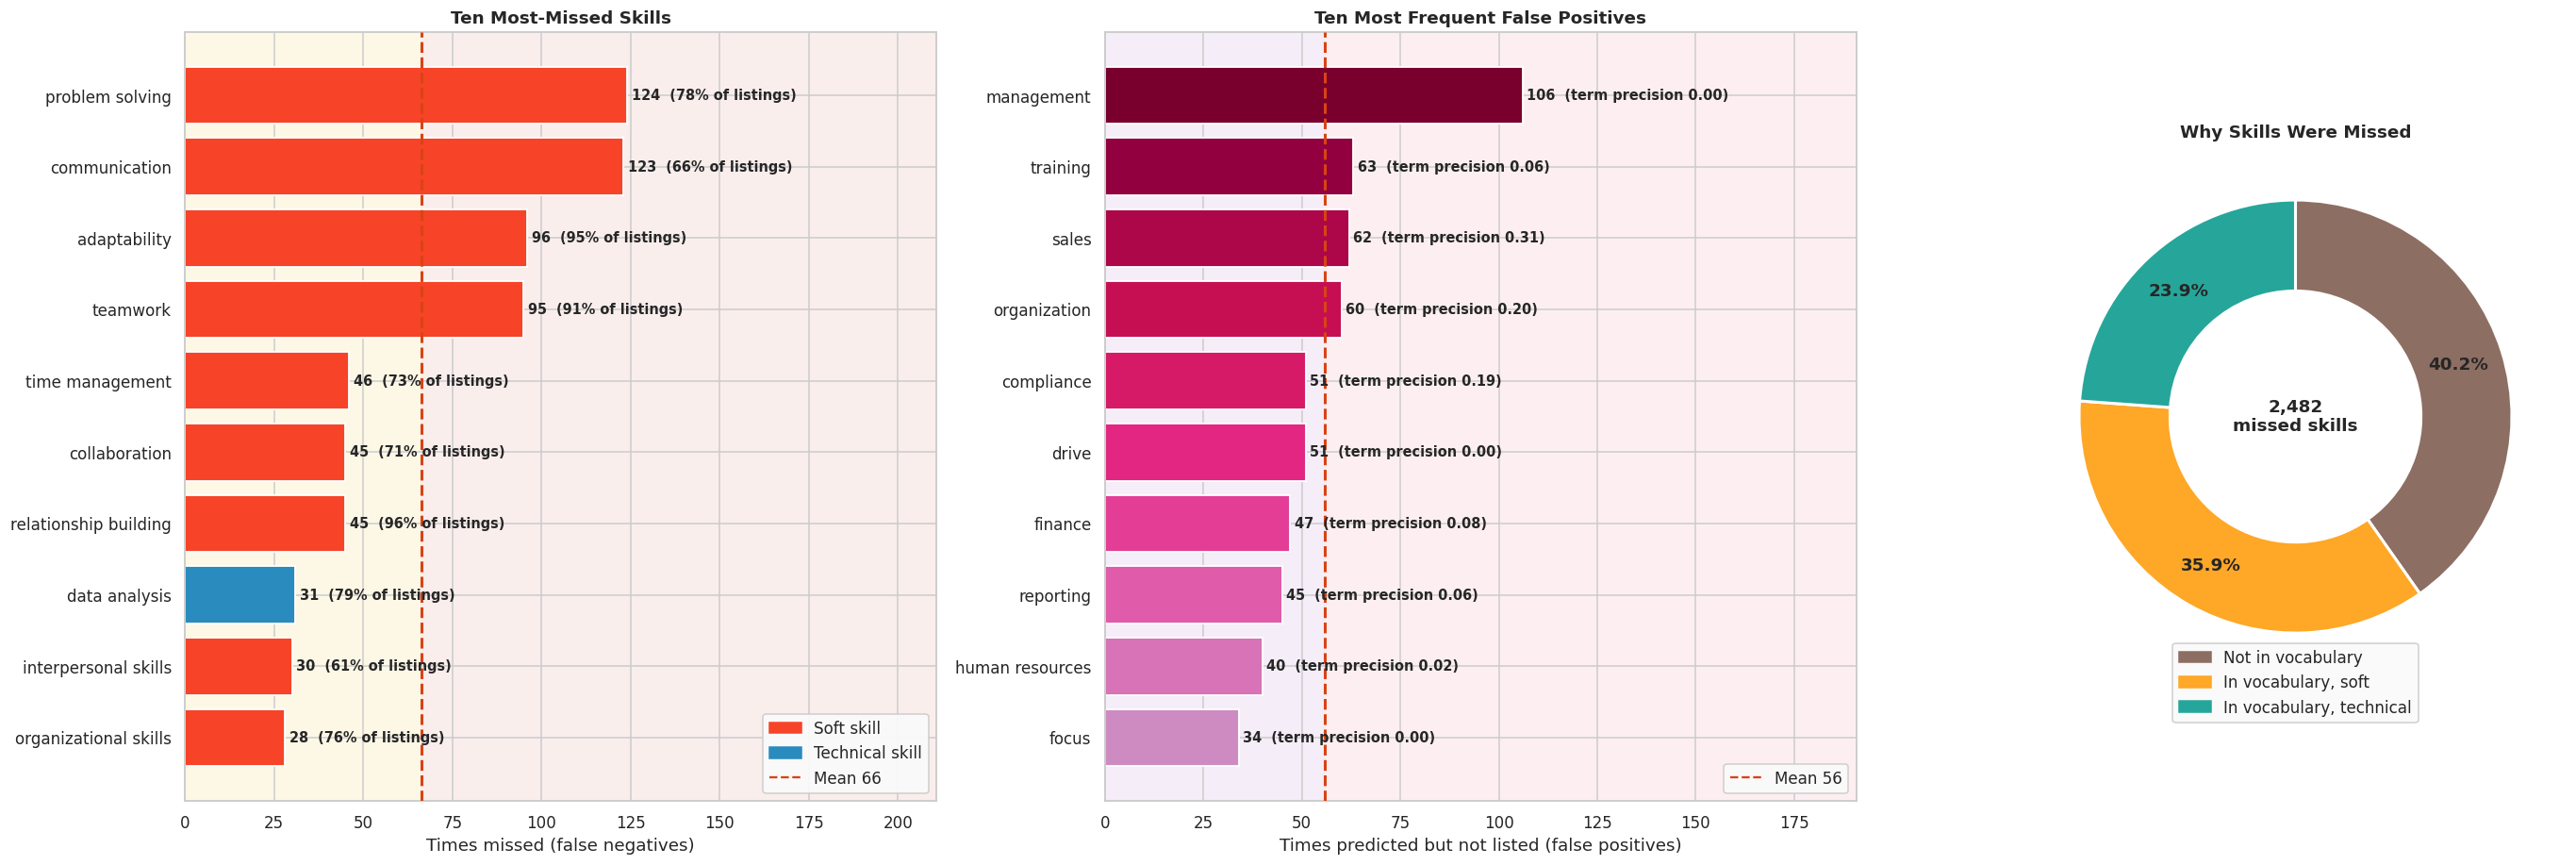

false negatives: 2482 | not in vocabulary: 999 | in vocabulary, missed: 1483
false positives: 2183 | true positives: 1115
lowest-precision frequent terms: [('planning', 0.0, 32), ('drive', 0.0, 51), ('communication skills', 0.0, 31), ('focus', 0.0, 34), ('management', 0.0, 106), ('coordination', 0.0, 8), ('commitment', 0.0, 25), ('responsibility', 0.0, 19), ('driving', 0.0, 28), ('verbal communication', 0.0, 10), ('written communication', 0.0, 29), ('computer skills', 0.0, 10)]


In [50]:
true_c, tp_c, fp_c, fn_c = Counter(), Counter(), Counter(), Counter()
for pr, tr_ in zip(test_pred, test_true):
    P, T = set(pr), set(tr_)
    true_c.update(T)
    tp_c.update(P & T)
    fp_c.update(P - T)
    fn_c.update(T - P)

fn_total = sum(fn_c.values())
fn_oov = sum(c for s, c in fn_c.items() if s not in vocab_tr_set)
fn_soft = sum(c for s, c in fn_c.items() if s in vocab_tr_set and s in SOFT_SKILLS)
fn_tech = fn_total - fn_oov - fn_soft
fp_total = sum(fp_c.values())

fig, axes = plt.subplots(1, 3, figsize=(25, 8.5), gridspec_kw={'width_ratios': [1.25, 1.25, 0.9]})
ax = axes[0]
miss = fn_c.most_common(10)[::-1]
mn, mv = [s for s, _ in miss], [c for _, c in miss]
ax.axvspan(0, np.mean(mv), color='#fff8e1', alpha=0.8, zorder=0)
ax.axvspan(np.mean(mv), max(mv) * 1.7, color='#fbe9e7', alpha=0.7, zorder=0)
bars = ax.barh(mn, mv, color=[plt.cm.YlOrRd(0.65) if s in SOFT_SKILLS else plt.cm.GnBu(0.75) for s in mn],
               edgecolor='white', linewidth=1.2, zorder=2)
ax.axvline(np.mean(mv), color='#d84315', linestyle='--', linewidth=2, zorder=3)
for b, s, c in zip(bars, mn, mv):
    ax.text(c + max(mv) * 0.01, b.get_y() + b.get_height() / 2, f'{c}  ({c / true_c[s] * 100:.0f}% of listings)',
            va='center', fontsize=9.5, fontweight='bold')
ax.set_xlim(0, max(mv) * 1.7)
ax.set_xlabel('Times missed (false negatives)')
ax.set_title('Ten Most-Missed Skills')
ax.legend(handles=[Patch(color=plt.cm.YlOrRd(0.65), label='Soft skill'), Patch(color=plt.cm.GnBu(0.75), label='Technical skill'),
                   plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Mean {np.mean(mv):.0f}')],
          loc='lower right', framealpha=0.95)

ax2 = axes[1]
fpl = fp_c.most_common(10)[::-1]
fn_, fv_ = [s for s, _ in fpl], [c for _, c in fpl]
ax2.axvspan(0, np.mean(fv_), color='#f3e5f5', alpha=0.6, zorder=0)
ax2.axvspan(np.mean(fv_), max(fv_) * 1.8, color='#ffebee', alpha=0.7, zorder=0)
bars2 = ax2.barh(fn_, fv_, color=plt.cm.PuRd(np.linspace(0.4, 0.95, len(fv_))), edgecolor='white', linewidth=1.2, zorder=2)
ax2.axvline(np.mean(fv_), color='#d84315', linestyle='--', linewidth=2, zorder=3)
for b, s, c in zip(bars2, fn_, fv_):
    ax2.text(c + max(fv_) * 0.01, b.get_y() + b.get_height() / 2, f'{c}  (term precision {tp_c[s] / (tp_c[s] + c):.2f})',
             va='center', fontsize=9.5, fontweight='bold')
ax2.set_xlim(0, max(fv_) * 1.8)
ax2.set_xlabel('Times predicted but not listed (false positives)')
ax2.set_title('Ten Most Frequent False Positives')
ax2.legend(handles=[plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Mean {np.mean(fv_):.0f}')],
           loc='lower right', framealpha=0.95)

ax3 = axes[2]
parts = [fn_oov, fn_soft, fn_tech]
ax3.pie(parts, colors=['#8d6e63', '#ffa726', '#26a69a'], startangle=90, counterclock=False,
        wedgeprops=dict(width=0.42, edgecolor='white', linewidth=2), autopct=lambda p: f'{p:.1f}%', pctdistance=0.79,
        textprops=dict(fontweight='bold', fontsize=12))
ax3.text(0, 0, f'{fn_total:,}\nmissed skills', ha='center', va='center', fontsize=12, fontweight='bold')
ax3.legend(handles=[Patch(color='#8d6e63', label='Not in vocabulary'), Patch(color='#ffa726', label='In vocabulary, soft'),
                    Patch(color='#26a69a', label='In vocabulary, technical')],
           loc='lower center', bbox_to_anchor=(0.5, -0.08), framealpha=0.95)
ax3.set_title('Why Skills Were Missed')
plt.tight_layout()
plt.show()

print('false negatives:', fn_total, '| not in vocabulary:', fn_oov, '| in vocabulary, missed:', fn_total - fn_oov)
print('false positives:', fp_total, '| true positives:', sum(tp_c.values()))
print('lowest-precision frequent terms:', sorted([(s, round(tp_c[s] / (tp_c[s] + c), 2), tp_c[s] + c) for s, c in fp_c.items() if tp_c[s] + c >= 8],
                                                 key=lambda t: t[1])[:12])

,thr,blocked,precision,recall,f1
0,0.00,0,0.361,0.318,0.322
1,0.05,26,0.416,0.313,0.339
2,0.10,50,0.489,0.305,0.358
3,0.15,78,0.538,0.294,0.361
4,0.20,104,0.563,0.282,0.357
5,0.25,130,0.583,0.270,0.352
6,0.30,160,0.597,0.258,0.343
7,0.35,176,0.635,0.245,0.335
8,0.40,187,0.647,0.239,0.331
9,0.45,227,0.664,0.222,0.316


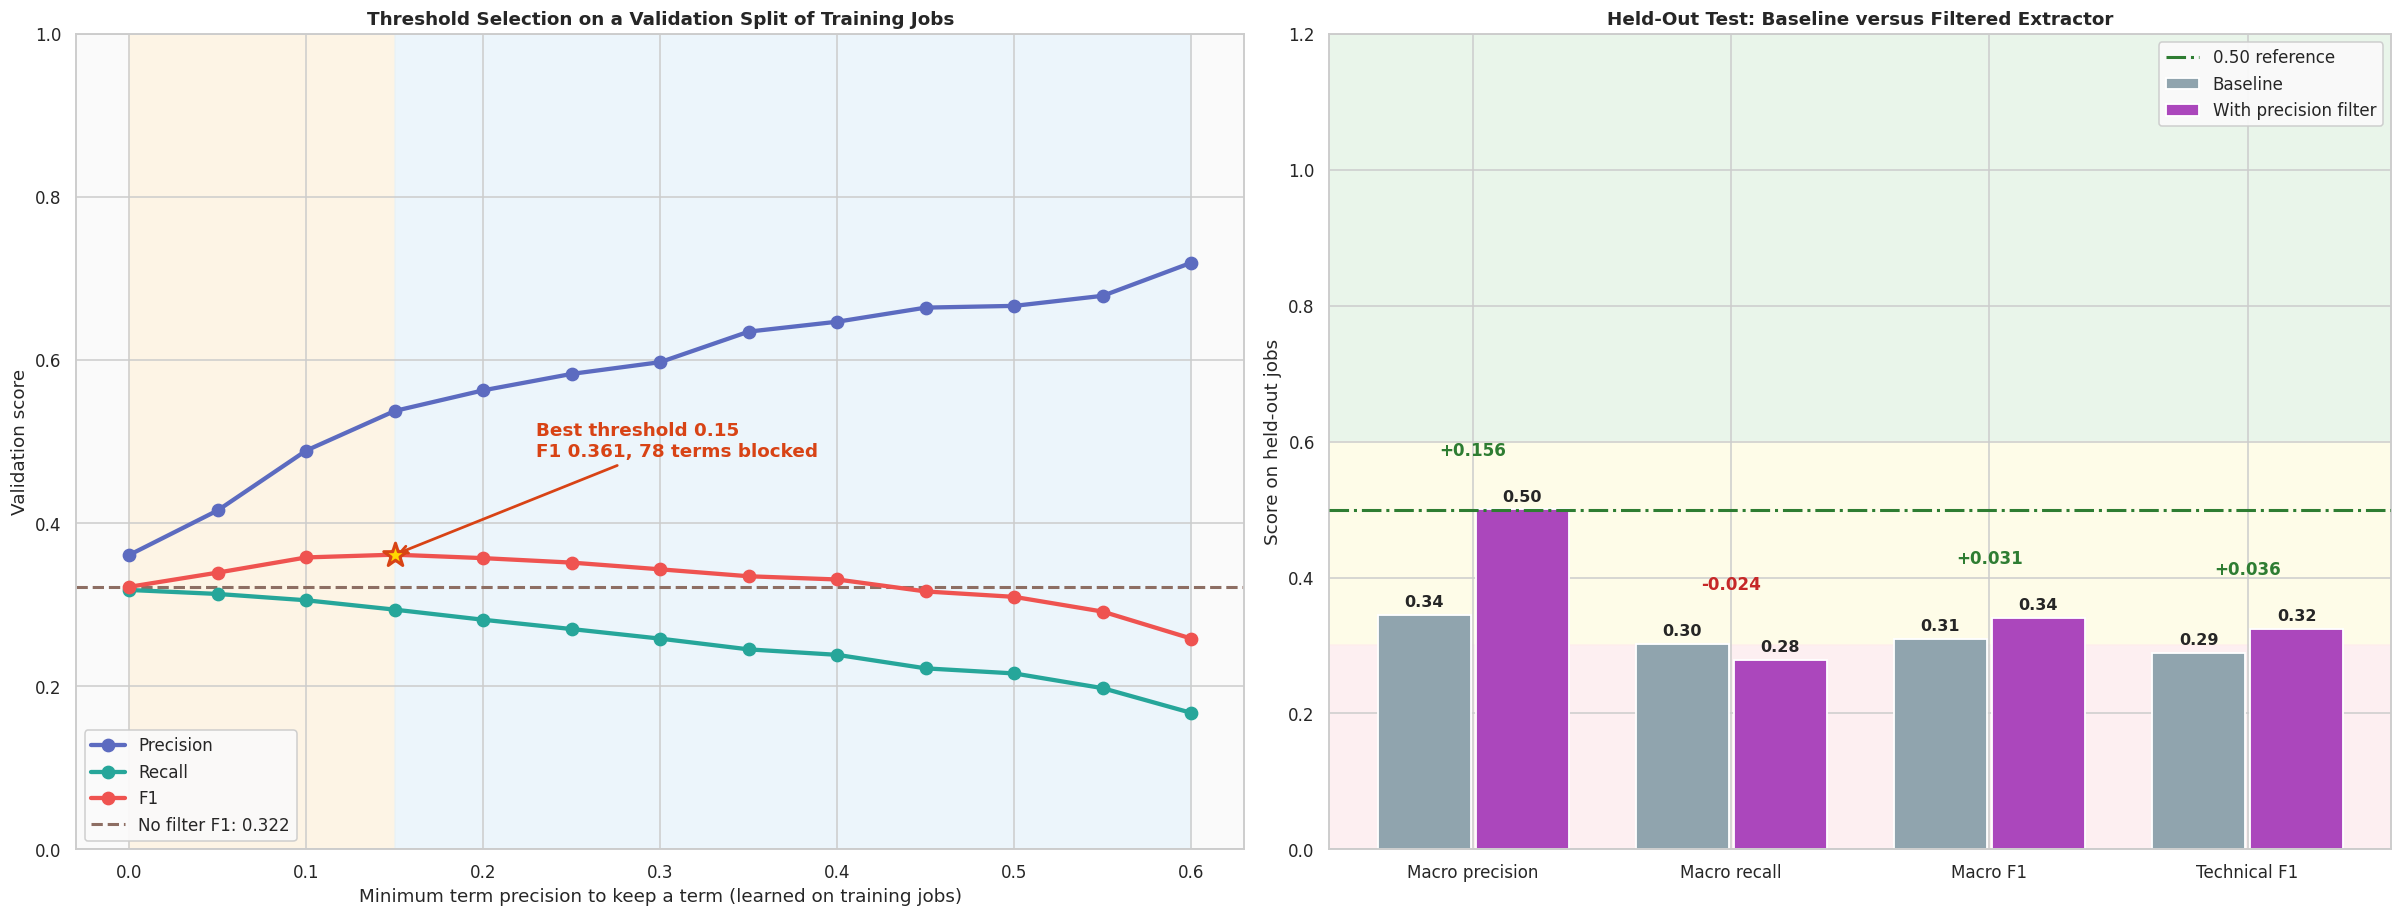

blocked terms: 74
[('management', 0.0, 441), ('organization', 0.07, 344), ('training', 0.06, 331), ('drive', 0.02, 293), ('finance', 0.11, 232), ('reporting', 0.1, 221), ('marketing', 0.14, 213), ('focus', 0.0, 205), ('planning', 0.06, 193), ('human resources', 0.07, 182), ('driving', 0.03, 159), ('innovation', 0.07, 147), ('commitment', 0.01, 134), ('communication skills', 0.04, 133), ('execution', 0.02, 121), ('research', 0.03, 115), ('responsibility', 0.03, 109), ('written communication', 0.06, 97), ('information technology', 0.1, 96), ('engagement', 0.04, 94)]


In [51]:
ext_all = jobs['jd_clean'].apply(extract_tr)

def term_stats(idx):
    ment, hit = Counter(), Counter()
    for k in idx:
        found = set(ext_all.iat[k])
        ment.update(found)
        hit.update(found & set(jobs['skills_list'].iat[k]))
    return ment, hit

def build_block(ment, hit, thr, min_m=5):
    return {s for s, m in ment.items() if m >= min_m and hit[s] / m < thr}

fit_idx, val_idx = train_test_split(m3_tr, test_size=0.25, random_state=SEED)
ment_fit, hit_fit = term_stats(fit_idx)
val_true = [jobs['skills_list'].iat[k] for k in val_idx]
thresholds = np.round(np.arange(0, 0.65, 0.05), 2)
rows = []
for thr in thresholds:
    blk = build_block(ment_fit, hit_fit, thr)
    preds = [[s for s in ext_all.iat[k] if s not in blk] for k in val_idx]
    r = summarize(evaluate(preds, val_true))
    rows.append({'thr': thr, 'blocked': len(blk), 'precision': r['macro_precision'], 'recall': r['macro_recall'], 'f1': r['macro_f1']})
sweep = pd.DataFrame(rows)
best_thr = float(sweep.loc[sweep['f1'].idxmax(), 'thr'])

ment_tr, hit_tr = term_stats(m3_tr)
BLOCK = build_block(ment_tr, hit_tr, best_thr)
test_pred_f = [[s for s in p if s not in BLOCK] for p in test_pred]
filt = {g: summarize(evaluate(test_pred_f, test_true, f)) for g, f in GROUPS.items()}
display(sweep.round(3))

fig, axes = plt.subplots(1, 2, figsize=(22, 8.5), gridspec_kw={'width_ratios': [1.1, 1]})
ax = axes[0]
ax.axvspan(sweep['thr'].min(), best_thr, color='#fff3e0', alpha=0.8, zorder=0)
ax.axvspan(best_thr, sweep['thr'].max(), color='#e3f2fd', alpha=0.6, zorder=0)
for col, name, c in [('precision', 'Precision', '#5c6bc0'), ('recall', 'Recall', '#26a69a'), ('f1', 'F1', '#ef5350')]:
    ax.plot(sweep['thr'], sweep[col], marker='o', linewidth=2.8, markersize=8, color=c, label=name, zorder=3)
kb = sweep.loc[sweep['f1'].idxmax()]
ax.scatter([best_thr], [kb['f1']], s=260, marker='*', color='#ffd600', edgecolor='#d84315', linewidth=2, zorder=6)
ax.annotate(f'Best threshold {best_thr:.2f}\nF1 {kb["f1"]:.3f}, {int(kb["blocked"])} terms blocked', xy=(best_thr, kb['f1']),
            xytext=(best_thr + 0.08, kb['f1'] + 0.12), fontweight='bold', color='#d84315',
            arrowprops=dict(arrowstyle='->', color='#d84315', linewidth=1.8))
ax.axhline(sweep['f1'].iloc[0], color='#8d6e63', linestyle='--', linewidth=2, label=f'No filter F1: {sweep["f1"].iloc[0]:.3f}')
ax.set_ylim(0, 1)
ax.set_xlabel('Minimum term precision to keep a term (learned on training jobs)')
ax.set_ylabel('Validation score')
ax.set_title('Threshold Selection on a Validation Split of Training Jobs')
ax.legend(loc='lower left', framealpha=0.95)

ax2 = axes[1]
labs = ['Macro precision', 'Macro recall', 'Macro F1', 'Technical F1']
bv = [base['All skills']['macro_precision'], base['All skills']['macro_recall'], base['All skills']['macro_f1'], base['Technical']['macro_f1']]
fv = [filt['All skills']['macro_precision'], filt['All skills']['macro_recall'], filt['All skills']['macro_f1'], filt['Technical']['macro_f1']]
x2 = np.arange(4)
ax2.axhspan(0.6, 1.2, color='#e8f5e9', alpha=0.9, zorder=0)
ax2.axhspan(0.3, 0.6, color='#fffde7', alpha=0.9, zorder=0)
ax2.axhspan(0, 0.3, color='#ffebee', alpha=0.7, zorder=0)
b1 = ax2.bar(x2 - 0.19, bv, 0.36, color='#90a4ae', edgecolor='white', linewidth=1.2, zorder=2, label='Baseline')
b2 = ax2.bar(x2 + 0.19, fv, 0.36, color='#ab47bc', edgecolor='white', linewidth=1.2, zorder=2, label='With precision filter')
for bars in (b1, b2):
    for b in bars:
        ax2.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.012, f'{b.get_height():.2f}', ha='center', fontsize=10.5, fontweight='bold')
for x_, a, b_ in zip(x2, bv, fv):
    ax2.text(x_, max(a, b_) + 0.08, f'{b_ - a:+.3f}', ha='center', fontsize=11, fontweight='bold', color='#2e7d32' if b_ >= a else '#c62828')
ax2.axhline(0.5, color='#2e7d32', linestyle='-.', linewidth=2, zorder=3, label='0.50 reference')
ax2.set_xticks(x2)
ax2.set_xticklabels(labs)
ax2.set_ylim(0, 1.2)
ax2.set_ylabel('Score on held-out jobs')
ax2.set_title('Held-Out Test: Baseline versus Filtered Extractor')
ax2.legend(loc='upper right', framealpha=0.95)
plt.tight_layout()
plt.show()

print('blocked terms:', len(BLOCK))
print(sorted([(s, round(hit_tr[s] / ment_tr[s], 2), ment_tr[s]) for s in BLOCK], key=lambda t: -t[2])[:20])

,baseline,filtered,n
cat,,,
BUSINESS-DEVELOPMENT,0.290,0.330,42
FINANCE,0.293,0.326,42
HR,0.352,0.396,39
INFORMATION-TECHNOLOGY,0.333,0.350,42
SALES,0.279,0.298,35


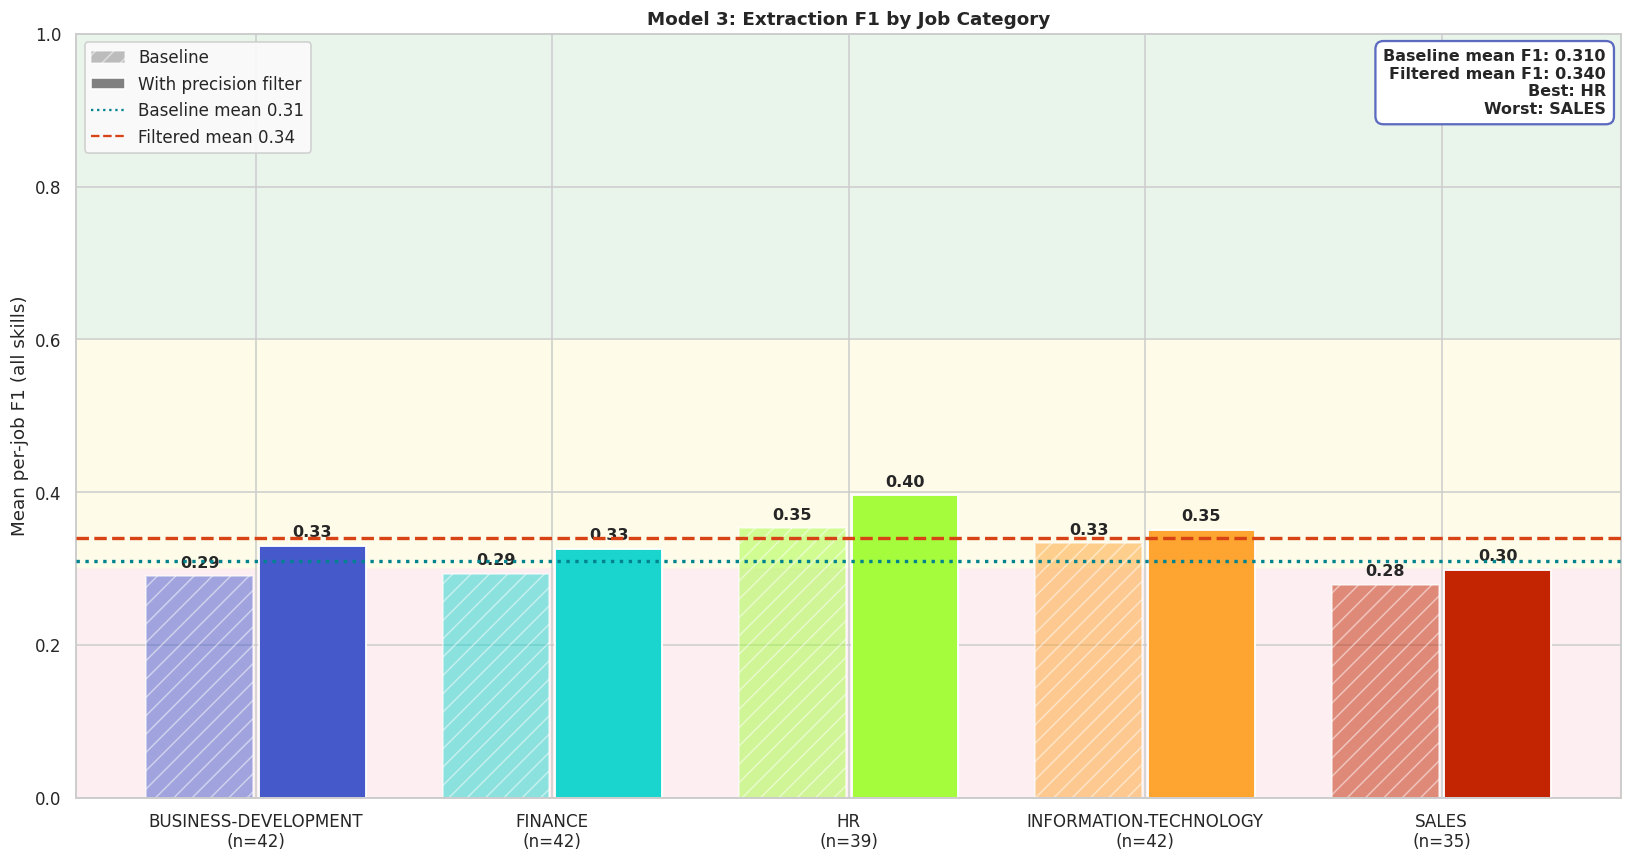

{
  "train_jobs": 933,
  "evaluated_jobs": 200,
  "vocab_size_train_only": 709,
  "vocab_min_freq": 3,
  "recall_ceiling": {
    "All skills": 0.7223,
    "Technical": 0.5736,
    "Soft": 1.0
  },
  "baseline": {
    "All skills": {
      "micro_precision": 0.3381,
      "micro_recall": 0.31,
      "micro_f1": 0.3234,
      "macro_precision": 0.3445,
      "macro_recall": 0.3028,
      "macro_f1": 0.3097,
      "jobs": 200.0
    },
    "Technical": {
      "micro_precision": 0.288,
      "micro_recall": 0.321,
      "micro_f1": 0.3036,
      "macro_precision": 0.2918,
      "macro_recall": 0.3156,
      "macro_f1": 0.2886,
      "jobs": 200.0
    },
    "Soft": {
      "micro_precision": 0.5284,
      "micro_recall": 0.2895,
      "micro_f1": 0.374,
      "macro_precision": 0.4751,
      "macro_recall": 0.2798,
      "macro_f1": 0.3329,
      "jobs": 200.0
    }
  },
  "filtered": {
    "All skills": {
      "micro_precision": 0.4884,
      "micro_recall": 0.2858,
      "micro_f1": 0.3

In [52]:
cat_test = jobs[JOB_CAT].iloc[m3_te].values
df_b, df_f = evaluate(test_pred, test_true), evaluate(test_pred_f, test_true)
df_b['cat'], df_f['cat'] = cat_test, cat_test
cat_tab = pd.DataFrame({'baseline': df_b.groupby('cat')['f1'].mean(), 'filtered': df_f.groupby('cat')['f1'].mean(),
                        'n': df_b.groupby('cat').size()}).reindex(cats)
display(cat_tab.round(3))

x = np.arange(len(cats))
gm_b, gm_f = df_b['f1'].mean(), df_f['f1'].mean()
fig, ax = plt.subplots(figsize=(15, 8))
ax.axhspan(0.6, 1.0, color='#e8f5e9', alpha=0.9, zorder=0)
ax.axhspan(0.3, 0.6, color='#fffde7', alpha=0.9, zorder=0)
ax.axhspan(0, 0.3, color='#ffebee', alpha=0.7, zorder=0)
cols = [CAT_COLORS[c] for c in cats]
b1 = ax.bar(x - 0.19, cat_tab['baseline'], 0.36, color=cols, alpha=0.5, hatch='//', edgecolor='white', linewidth=1.2, zorder=2)
b2 = ax.bar(x + 0.19, cat_tab['filtered'], 0.36, color=cols, edgecolor='white', linewidth=1.2, zorder=2)
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.012, f'{b.get_height():.2f}', ha='center', fontsize=10.5, fontweight='bold')
ax.axhline(gm_b, color='#00838f', linestyle=':', linewidth=2.2, zorder=3)
ax.axhline(gm_f, color='#d84315', linestyle='--', linewidth=2.2, zorder=3)
ax.set_xticks(x)
ax.set_xticklabels([f'{c}\n(n={int(cat_tab.loc[c, "n"])})' for c in cats])
ax.set_ylim(0, 1.0)
ax.set_ylabel('Mean per-job F1 (all skills)')
ax.set_title('Model 3: Extraction F1 by Job Category')
kpi = f'Baseline mean F1: {gm_b:.3f}\nFiltered mean F1: {gm_f:.3f}\nBest: {cat_tab["filtered"].idxmax()}\nWorst: {cat_tab["filtered"].idxmin()}'
ax.text(0.99, 0.98, kpi, transform=ax.transAxes, ha='right', va='top', fontsize=10.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#5c6bc0', linewidth=1.5))
ax.legend(handles=[Patch(facecolor='grey', alpha=0.5, hatch='//', label='Baseline'), Patch(facecolor='grey', label='With precision filter'),
                   plt.Line2D([0], [0], color='#00838f', linestyle=':', label=f'Baseline mean {gm_b:.2f}'),
                   plt.Line2D([0], [0], color='#d84315', linestyle='--', label=f'Filtered mean {gm_f:.2f}')],
          loc='upper left', framealpha=0.95)
plt.tight_layout()
plt.show()

def rnd(d):
    return {k: round(float(v), 4) for k, v in d.items()}

model3_metrics = {
    'train_jobs': int(len(m3_tr)), 'evaluated_jobs': int(len(m3_te)), 'vocab_size_train_only': int(len(vocab_tr)),
    'vocab_min_freq': M3_MIN_FREQ, 'recall_ceiling': rnd(ceiling),
    'baseline': {g: rnd(v) for g, v in base.items()}, 'filtered': {g: rnd(v) for g, v in filt.items()},
    'filter_threshold': best_thr, 'blocked_terms': int(len(BLOCK)),
    'false_negative_share_not_in_vocabulary': round(fn_oov / fn_total, 4)}
print(json.dumps(model3_metrics, indent=2))

In [53]:
from sklearn.model_selection import GroupShuffleSplit
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(pairs[['sim']].values, pairs['match'].values, pairs['resume_idx'].values))
rows = []
for ia in range(21):
    for ib in range(21 - ia):
        a, b, c = ia / 20, ib / 20, (20 - ia - ib) / 20
        sc = a * s_norm + b * ct + c * cs
        rows.append({'semantic': a, 'tech': b, 'soft': c, 'auc_train': roc_auc_score(y_m[tr], sc[tr]), 'auc_test': roc_auc_score(y_m[te], sc[te])})
wg = pd.DataFrame(rows)
best_tr = wg.loc[wg['auc_train'].idxmax()]
cur_sc_all = W['semantic'] * s_norm + W['tech'] * ct + W['soft'] * cs
display(best_tr.round(3).to_frame('train-selected'))
print('train-selected weights, test AUC:', round(float(best_tr['auc_test']), 4))
print('current W', W, 'test AUC:', round(roc_auc_score(y_m[te], cur_sc_all[te]), 4))

,train-selected
semantic,0.400
tech,0.600
soft,0.000
auc_train,0.818
auc_test,0.828


train-selected weights, test AUC: 0.8276
current W {'semantic': 0.45, 'tech': 0.55, 'soft': 0.0} test AUC: 0.8279


,pairs_n,match_rate,pct_of_pairs
band,,,
Low fit,300,0.240,50.000
Moderate fit,214,0.710,35.667
High fit,86,0.884,14.333


,all_pairs,matched_pairs,n_pairs
job_cat,,,
BUSINESS-DEVELOPMENT,38.92,46.40,125
FINANCE,35.33,46.92,127
HR,41.48,55.15,106
INFORMATION-TECHNOLOGY,30.18,39.27,125
SALES,31.78,37.57,117


       cov_all  cov_tech  gap_all  gap_tech
count  600.000   600.000  600.000    600.00
mean     0.205     0.204   14.193     11.64
std      0.145     0.159    8.347      6.99
min      0.000     0.000    0.000      0.00
25%      0.105     0.091    8.000      6.00
50%      0.182     0.182   12.000     10.00
75%      0.288     0.286   19.000     16.00
max      1.000     1.000   44.000     39.00
parsing success: {'resume_parsing_success_pct': np.float64(99.96), 'job_description_parsing_success_pct': np.float64(100.0)}


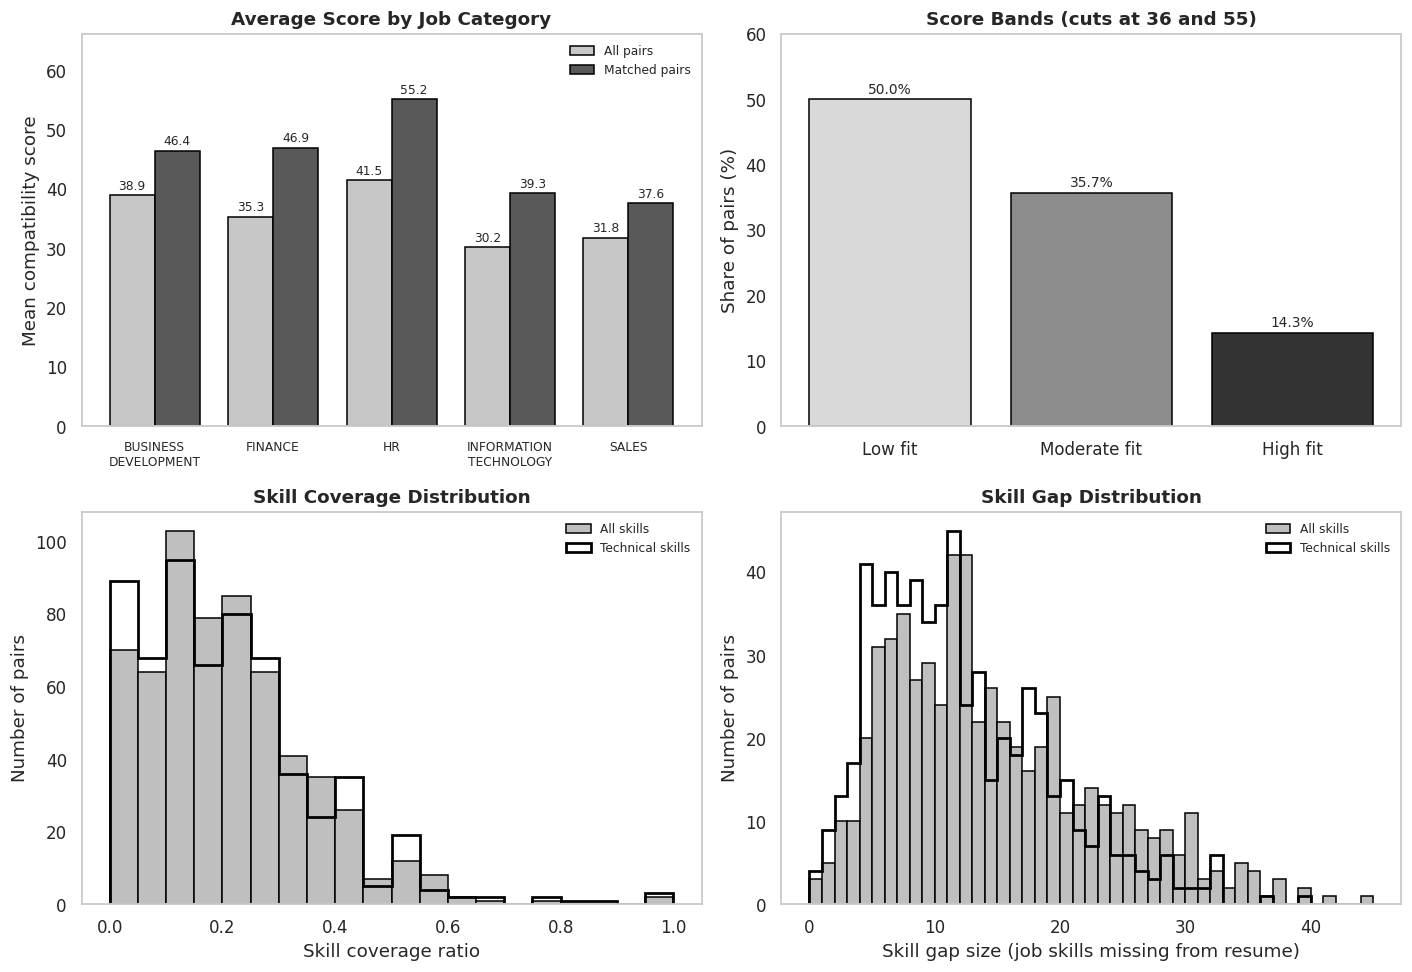

{
  "parsing_success": {
    "resume_parsing_success_pct": 99.96,
    "job_description_parsing_success_pct": 100.0
  },
  "avg_score_by_category": {
    "BUSINESS-DEVELOPMENT": {
      "all_pairs": 38.92,
      "matched_pairs": 46.4,
      "n_pairs": 125
    },
    "FINANCE": {
      "all_pairs": 35.33,
      "matched_pairs": 46.92,
      "n_pairs": 127
    },
    "HR": {
      "all_pairs": 41.48,
      "matched_pairs": 55.15,
      "n_pairs": 106
    },
    "INFORMATION-TECHNOLOGY": {
      "all_pairs": 30.18,
      "matched_pairs": 39.27,
      "n_pairs": 125
    },
    "SALES": {
      "all_pairs": 31.78,
      "matched_pairs": 37.57,
      "n_pairs": 117
    }
  },
  "skill_coverage": {
    "cov_all": {
      "mean": 0.2053,
      "median": 0.1818
    },
    "cov_tech": {
      "mean": 0.2038,
      "median": 0.1818
    }
  },
  "skill_gap": {
    "gap_all": {
      "mean": 14.193,
      "median": 12.0
    },
    "gap_tech": {
      "mean": 11.64,
      "median": 10.0
    }
  },
  

In [54]:
BAND_NAMES = ['Low fit', 'Moderate fit', 'High fit']
pairs['band'] = pd.cut(pairs['score'], bins=[-np.inf, 36, 55, np.inf], labels=BAND_NAMES, right=False)

band_tab = pairs.groupby('band', observed=False).agg(pairs_n=('score', 'size'), match_rate=('match', 'mean'))
band_tab['pct_of_pairs'] = band_tab['pairs_n'] / len(pairs) * 100

cat_tab2 = pd.DataFrame({
    'all_pairs': pairs.groupby('job_cat')['score'].mean(),
    'matched_pairs': pairs[pairs['match'] == 1].groupby('job_cat')['score'].mean(),
    'n_pairs': pairs.groupby('job_cat').size()
})

display(band_tab.round(3))
display(cat_tab2.round(2))
print(pairs[['cov_all', 'cov_tech', 'gap_all', 'gap_tech']].describe().round(3))
print('parsing success:', parsing_success)

fig, axes = plt.subplots(2, 2, figsize=(13, 9), facecolor='white')
for a in axes.ravel():
    a.set_facecolor('white')
    a.grid(False)

ax = axes[0, 0]
x = np.arange(len(cat_tab2))
w = 0.38
b1 = ax.bar(x - w / 2, cat_tab2['all_pairs'], w, color='0.78', edgecolor='black', label='All pairs')
b2 = ax.bar(x + w / 2, cat_tab2['matched_pairs'], w, color='0.35', edgecolor='black', label='Matched pairs')
ax.bar_label(b1, fmt='%.1f', fontsize=8, padding=2)
ax.bar_label(b2, fmt='%.1f', fontsize=8, padding=2)
ax.set_xticks(x)
ax.set_xticklabels([c.replace('-', '\n') for c in cat_tab2.index], fontsize=8)
ax.set_ylim(0, cat_tab2[['all_pairs', 'matched_pairs']].max().max() * 1.2)
ax.set_ylabel('Mean compatibility score')
ax.set_title('Average Score by Job Category')
ax.legend(loc='upper right', frameon=False, fontsize=8)

ax = axes[0, 1]
bb = ax.bar(BAND_NAMES, band_tab['pct_of_pairs'], color=['0.85', '0.55', '0.2'], edgecolor='black')
ax.bar_label(bb, labels=[f'{p:.1f}%' for p in band_tab['pct_of_pairs']], fontsize=9, padding=2)
ax.set_ylim(0, band_tab['pct_of_pairs'].max() * 1.2)
ax.set_ylabel('Share of pairs (%)')
ax.set_title('Score Bands (cuts at 36 and 55)')

ax = axes[1, 0]
ax.hist(pairs['cov_all'], bins=20, range=(0, 1), color='0.75', edgecolor='black', label='All skills')
ax.hist(pairs['cov_tech'], bins=20, range=(0, 1), histtype='step', color='black', linewidth=1.8, label='Technical skills')
ax.set_xlabel('Skill coverage ratio')
ax.set_ylabel('Number of pairs')
ax.set_title('Skill Coverage Distribution')
ax.legend(loc='best', frameon=False, fontsize=8)

ax = axes[1, 1]
gmax = int(pairs['gap_all'].max())
ax.hist(pairs['gap_all'], bins=range(0, gmax + 2), color='0.75', edgecolor='black', label='All skills')
ax.hist(pairs['gap_tech'], bins=range(0, gmax + 2), histtype='step', color='black', linewidth=1.8, label='Technical skills')
ax.set_xlabel('Skill gap size (job skills missing from resume)')
ax.set_ylabel('Number of pairs')
ax.set_title('Skill Gap Distribution')
ax.legend(loc='best', frameon=False, fontsize=8)

plt.tight_layout()
plt.show()

phase4_metrics = {
    'parsing_success': parsing_success,
    'avg_score_by_category': {k: {'all_pairs': round(float(r['all_pairs']), 2), 'matched_pairs': round(float(r['matched_pairs']), 2), 'n_pairs': int(r['n_pairs'])} for k, r in cat_tab2.iterrows()},
    'skill_coverage': {c: {'mean': round(float(pairs[c].mean()), 4), 'median': round(float(pairs[c].median()), 4)} for c in ['cov_all', 'cov_tech']},
    'skill_gap': {c: {'mean': round(float(pairs[c].mean()), 3), 'median': float(pairs[c].median())} for c in ['gap_all', 'gap_tech']},
    'score_bands': {b: {'pairs': int(r['pairs_n']), 'pct_of_pairs': round(float(r['pct_of_pairs']), 2), 'match_rate': round(float(r['match_rate']), 4)} for b, r in band_tab.iterrows()},
    'band_cuts': {'low_max': 36, 'high_min': 55}
}
print(json.dumps(phase4_metrics, indent=2))

In [56]:
import os
import shutil
import joblib
from google.colab import files

ART = '/content/artifacts'
os.makedirs(ART, exist_ok=True)

def dump_json(obj, name):
    with open(f'{ART}/{name}', 'w') as f:
        json.dump(obj, f, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))

joblib.dump(final_pipe.named_steps['clf'], f'{ART}/resume_classifier.joblib')
joblib.dump(final_pipe.named_steps['tfidf'], f'{ART}/tfidf_vectorizer.joblib')
joblib.dump(le, f'{ART}/label_encoder.joblib')

dump_json(sorted(skills_vocab), 'skills_vocab.json')
dump_json(SYNONYMS, 'synonyms.json')
dump_json(sorted(SOFT_SKILLS), 'soft_skills.json')
dump_json(sorted(BLOCK), 'extractor_block_terms_not_applied.json')

config = {
    'embedding_model': EMBED_MODEL,
    'embedding_chunk_words': CHUNK_WORDS,
    'embedding_pooling': 'sum of L2-normalised chunk embeddings, then L2-normalised',
    'sim_lo': SIM_LO,
    'sim_hi': SIM_HI,
    'scorer_weights': W,
    'score_formula': '100 * (semantic * clip((sim - sim_lo) / (sim_hi - sim_lo), 0, 1) + tech * technical_coverage + soft * soft_coverage)',
    'coverage_fallback': 'empty technical or soft set uses overall coverage; empty overall set gives 0',
    'score_bands': {**SCORE_BANDS, 'rule': 'score < low_max is Low fit; low_max <= score < high_min is Moderate fit; score >= high_min is High fit'},
    'classifier': {'model': BEST_NAME, 'tfidf_params': TFIDF_PARAMS, 'classes': le.classes_.tolist()},
    'job_categories': JOB_MATCHABLE,
    'skill_extractor': {'vocab_file': 'skills_vocab.json', 'synonyms_file': 'synonyms.json', 'min_freq': MIN_FREQ,
                        'alias_min_length': 3, 'max_ngram': MAX_N, 'matching': 'greedy longest n-gram on cleaned text',
                        'block_terms_applied_at_inference': False},
    'seed': SEED
}
dump_json(config, 'config.json')

prompt_templates = {
    'skill_extraction': (
        'You are an expert recruiter. Read the job description below and list the skills it requires. '
        'Return only a JSON list of lowercase strings, technical skills first, without duplicates.\n\n'
        'Job description:\n{job_description}'
    ),
    'cv_suggestions': (
        'You are a career coach improving a CV for a specific job. The CV has a compatibility score of {score} out of 100 ({band}). '
        'Skills already matched: {matched_skills}. Skills the job requires that are missing from the CV: {missing_skills}. '
        'Give at most five specific, honest suggestions. Suggest adding a missing skill only if the CV text shows evidence for it. '
        'Do not invent experience.\n\nCV:\n{resume_text}\n\nJob description:\n{job_description}'
    ),
    'career_paths': (
        'You are a career adviser. The CV below was classified as {predicted_category}, with other likely categories {top_categories}. '
        'Its strongest skills are {matched_skills}. Suggest three realistic career paths, and for each give the job titles to target, '
        'the skills to develop next, and a short reason.\n\nCV:\n{resume_text}'
    )
}
dump_json(prompt_templates, 'prompt_templates.json')

metrics_report = {
    'parsing_success': parsing_success,
    'model1_resume_classifier': model1_metrics,
    'model2_rule_based': model2_rule_metrics,
    'model2_supervised': model2_sup_metrics,
    'model3_skill_extraction': model3_metrics,
    'phase4': phase4_metrics,
    'heldout_weight_check': {
        'current_weights_test_auc': 0.8279,
        'train_selected_weights': {'semantic': 0.4, 'tech': 0.6, 'soft': 0.0},
        'train_selected_test_auc': 0.8276
    },
    'limitations': [
        'Match label means same category, so the AUC measures agreement with category rather than true candidate fit.',
        'Score band cuts and the reported rule-based AUC of 0.820 come from the same 600 pairs; the held-out AUC is 0.828.',
        'Listed soft skills are mostly not written in job descriptions, so exact-match extraction cannot recover them.',
        'Skill extraction is limited by the vocabulary: 28 percent of true skills are outside it.'
    ]
}
dump_json(metrics_report, 'metrics_report.json')

clf_l = joblib.load(f'{ART}/resume_classifier.joblib')
tf_l = joblib.load(f'{ART}/tfidf_vectorizer.joblib')
le_l = joblib.load(f'{ART}/label_encoder.joblib')
print('classifier reload matches:', bool(np.array_equal(clf_l.predict(tf_l.transform(X_test)), y_pred)))
print('label encoder reload matches:', bool(np.array_equal(le_l.classes_, le.classes_)))

for fn in sorted(os.listdir(ART)):
    path = f'{ART}/{fn}'
    ok = ''
    if fn.endswith('.json'):
        with open(path) as f:
            json.load(f)
        ok = 'json valid'
    print(f'{fn:45s} {os.path.getsize(path) / 1024:9.1f} KB  {ok}')

shutil.make_archive('/content/cv_artifacts', 'zip', ART)
files.download('/content/cv_artifacts.zip')

classifier reload matches: True
label encoder reload matches: True
config.json                                         1.8 KB  json valid
extractor_block_terms_not_applied.json              1.4 KB  json valid
label_encoder.joblib                                0.7 KB  
metrics_report.json                                 5.5 KB  json valid
prompt_templates.json                               1.0 KB  json valid
resume_classifier.joblib                        11251.1 KB  
skills_vocab.json                                  19.0 KB  json valid
soft_skills.json                                    1.0 KB  json valid
synonyms.json                                       0.5 KB  json valid
tfidf_vectorizer.joblib                          2575.1 KB  


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>